# Option Pricing Atlas: 58 models and methods, when to use them, and what breaks

Companion to the *Financial Instruments Atlas*. Same structure: a searchable **catalog**, a working **pricing library** in plain Python, and **visuals** that compare models on the same footing.

**Runs in:** Google Colab and Microsoft Fabric notebooks (numpy, pandas, scipy, matplotlib; scikit-learn optional for the neural surrogate). Total runtime is a couple of minutes, most of it Monte Carlo.

| Section | Content |
|---|---|
| 1 | Setup and visual theme |
| 2 | Model catalog (58 entries: models, numerical methods, approximations) |
| 3 | Scoring methodology, lookup and the `recommend()` helper |
| 4 | Catalog overview charts |
| 5 | Closed-form models (BSM, Black-76, Bachelier, barriers, Asians, compound...) |
| 6 | Lattices (CRR, Jarrow-Rudd, Leisen-Reimer, trinomial) |
| 7 | American approximations (Barone-Adesi-Whaley, Bjerksund-Stensland) |
| 8 | PDE / finite differences (explicit, implicit, Crank-Nicolson, projected) |
| 9 | Monte Carlo (plain, variance reduction, Sobol, Longstaff-Schwartz) |
| 10 | Fourier methods (CF inversion, Carr-Madan FFT, COS) |
| 11 | Stochastic volatility (Heston, SABR) |
| 12 | Jump models (Merton, Kou, Bates, Variance Gamma, NIG) |
| 13 | Local volatility (CEV, SSVI, Dupire) |
| 14 | Rough volatility (rough Bergomi) |
| 15 | Interest-rate models (Hull-White) |
| 16 | Market practice and data-driven (Vanna-Volga, neural surrogate, VIX) |
| 17 | Smile gallery and risk-neutral densities |
| 18 | Calibration shoot-out (Heston vs SABR on a jumpy market) |
| 19 | Speed vs accuracy benchmark |
| 20 | Model selection guide, coverage check and export |

**The one idea to keep:** a *model* is an assumption about dynamics (Heston, Dupire). A *method* is how you compute a price given a model (tree, PDE, Monte Carlo, FFT). Most real choices are a pair: "Heston priced by COS", "local vol priced by Crank-Nicolson", "LSV priced by Monte Carlo". The catalog keeps them apart in the `kind` column.

Use `describe("heston")` for a full card plus a live demo, and `recommend(...)` for a shortlist given your product.

In [1]:
# Standard toolbox. scikit-learn is optional (only the neural surrogate demo needs it).
import math
import time
import difflib
import warnings
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
from matplotlib.lines import Line2D
from scipy import optimize, stats
from scipy.stats import norm, ncx2, qmc, multivariate_normal
from scipy.linalg import solve_banded

try:
    from IPython.display import display, Markdown
except ImportError:  # running as a plain script: we survive, just less pretty
    display = print
    Markdown = str

warnings.filterwarnings("ignore", category=RuntimeWarning)  # MC tails and log(0) at S=0 grid nodes. Known, harmless.
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

SEED = 7  # every demo seeds its own generator, so cell order doesn't change the numbers

# ---------------------------------------------------------------- visual theme
# Validated categorical order (colorblind-checked as a set). Fixed order, never cycled: slot 1 is always slot 1.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#9a9993", "#e8e7e2"
SEQ = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
       "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ)  # one hue, light to dark: magnitude only
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a8302f"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (10, 4.8),
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.linewidth": 0.9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.markersize": 6,
    "legend.frameon": False, "legend.fontsize": 9,
    "xtick.major.size": 0, "ytick.major.size": 0,
})

def style(ax, title=None, subtitle=None, xlabel=None, ylabel=None):
    """Title + muted subtitle, left aligned. Charts deserve a headline that says what to look at."""
    if title:
        ax.set_title(title, pad=22 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.2, color=INK2, va="bottom")
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    return ax

def end_labels(ax, series, fmt=None, dx=6):
    """Direct labels at line ends: text in ink, the coloured dot carries identity."""
    for name, spec in series.items():
        x, y, color = spec[:3]
        dy = spec[3] if len(spec) > 3 else 0      # optional nudge when two lines finish in the same place
        ax.plot(x[-1], y[-1], "o", color=color, ms=5, mec=SURFACE, mew=1.5, zorder=5)
        ax.annotate(name if fmt is None else fmt(name, y[-1]), (x[-1], y[-1]), xytext=(dx, dy),
                    textcoords="offset points", va="center", fontsize=8.8, color=INK)

def heatmap(ax, data, xlabels, ylabels, cmap=SEQ_CMAP, fmt="{:.2f}", vmin=None, vmax=None, cbar=None, annotate=True):
    data = np.asarray(data, float)
    vmin = np.nanmin(data) if vmin is None else vmin
    vmax = np.nanmax(data) if vmax is None else vmax
    im = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(xlabels)), xlabels)
    ax.set_yticks(range(len(ylabels)), ylabels)
    ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    if annotate:
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                v = data[i, j]
                if np.isfinite(v):
                    dark = (v - vmin) / (vmax - vmin + 1e-12) > 0.55
                    ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="white" if dark else INK)
    if cbar:
        cb = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
        cb.set_label(cbar, color=INK2); cb.outline.set_visible(False)
    return im

# ---------------------------------------------------------------- demo registry
DEMOS = {}
def demo(key):
    def wrap(fn):
        DEMOS[key] = fn
        return fn
    return wrap

def show(obj, title=None):
    if title:
        print(f"\n### {title}")
    if isinstance(obj, dict):
        obj = pd.Series(obj, name="value").to_frame()
    display(obj)

def timed(fn, *a, repeat=3, **kw):
    """Best-of-n wall time. Best, not mean, because the OS scheduler is not part of the model."""
    best, out = float("inf"), None
    for _ in range(repeat):
        t0 = time.perf_counter(); out = fn(*a, **kw); best = min(best, time.perf_counter() - t0)
    return out, best

# The reference contract every method gets graded on. Boring on purpose.
S0, K0, T0, R0, Q0, SIG0 = 100.0, 100.0, 1.0, 0.03, 0.01, 0.20
print("Setup done | numpy", np.__version__, "| pandas", pd.__version__)

Setup done | numpy 2.5.3 | pandas 3.0.5


## 2. Model catalog

| Column | Meaning |
|---|---|
| `kind` | **Model** (dynamics assumption), **Method** (numerical technique) or **Approximation** (analytic shortcut) |
| `family` | Grouping used throughout the notebook |
| `year`, `authors` | Origin (the version that made it famous) |
| `description`, `dynamics` | What it is, the core equation |
| `when_used`, `products` | Where practitioners actually use it |
| `pros`, `cons` | The honest version |
| `accuracy`, `speed`, `flexibility`, `smile`, `ease` | Scores 1 (poor) to 5 (excellent), see section 3 |
| `early_exercise` | Native support for American/Bermudan features |
| `impl` | Demo function in this notebook, empty if catalog-only |

In [2]:
# Column order (so nobody counts commas at 2 am):
# name, kind, family, year, authors, description, dynamics, when_used, products, pros, cons,
# accuracy, speed, flexibility, smile, ease (each 1-5), early_exercise (Yes / Approx / No), impl
MODELS = [
# ------------------------------------------------------------------ CLOSED FORM
("Black-Scholes-Merton", "Model", "Closed form", 1973, "Black, Scholes, Merton",
 "Geometric Brownian motion with constant volatility; the European price has a closed form.",
 "dS = (r - q) S dt + sigma S dW",
 "Quoting convention for the whole vol market, quick sanity checks, Greeks, any desk's first number.",
 "Equity, index and FX vanillas; implied vol quoting", "Instant, exact, closed-form Greeks, universal quoting language",
 "Flat vol, no jumps, thin tails, no early exercise; contradicted by every smile on earth", 2, 5, 1, 1, 5, "No", "bsm"),
("Black-76", "Model", "Closed form", 1976, "Fischer Black",
 "BSM written on the forward price, so carry disappears into the forward.",
 "dF = sigma F dW",
 "Options on futures and forwards, caps/floors and swaptions (lognormal market model).",
 "Commodity, bond and STIR futures options, caps, swaptions", "Same speed as BSM, no dividend/carry assumptions needed",
 "Lognormal: breaks for zero or negative forwards", 2, 5, 1, 1, 5, "No", "black76"),
("Bachelier (normal model)", "Model", "Closed form", 1900, "Louis Bachelier",
 "Arithmetic Brownian motion: the forward moves in absolute, not relative, steps.",
 "dF = sigma_N dW",
 "Negative or near-zero rates (EUR swaptions quoted in normal vol), spreads, power prices that go negative.",
 "Swaptions, caps, spread options, short-dated vanillas", "Handles negative forwards and strikes, normal vol is intuitive in bp",
 "Allows negative prices for assets that cannot go negative", 3, 5, 1, 2, 5, "No", "bachelier"),
("Garman-Kohlhagen", "Model", "Closed form", 1983, "Garman, Kohlhagen",
 "BSM for FX with the foreign rate acting as a continuous dividend yield.",
 "dS = (r_d - r_f) S dt + sigma S dW",
 "FX vanilla pricing and delta conventions; the base layer under Vanna-Volga and SABR in FX.",
 "FX calls and puts", "Exact, fast, matches FX market quoting",
 "No smile; FX smiles (risk reversals, butterflies) need an extra layer", 2, 5, 1, 1, 5, "No", "gk"),
("Displaced diffusion (shifted lognormal)", "Model", "Closed form", 1983, "Mark Rubinstein",
 "Lognormal dynamics on F + d: blends between lognormal (d=0) and normal (d large).",
 "d(F + d) = sigma (F + d) dW",
 "Shifted-Black quotes for low/negative rates, simple skew generation.",
 "Caps, swaptions, rates vanillas", "Closed form, adds monotone skew with one parameter",
 "Only skew, no curvature; shift is arbitrary", 3, 5, 1, 2, 5, "No", "displaced"),
("Margrabe exchange option", "Model", "Closed form", 1978, "William Margrabe",
 "Option to exchange one asset for another; the second asset acts as numeraire.",
 "Two correlated GBMs, sigma^2 = s1^2 + s2^2 - 2 rho s1 s2",
 "Outperformance options, stock-for-stock M&A, spread options with zero strike.",
 "Exchange and outperformance options", "Exact, no rate dependence",
 "Zero strike only; correlation is a single number", 3, 5, 2, 1, 5, "No", "margrabe"),
("Kirk spread approximation", "Approximation", "Closed form", 1995, "Ewan Kirk",
 "Treats F2 + K as lognormal so a spread option becomes a Margrabe option.",
 "F1 - F2 - K with effective vol depending on F2/(F2+K)",
 "Crack spreads, spark spreads, calendar spreads in energy.",
 "Spread options on futures", "Fast, accurate for small K",
 "Error grows with strike; no smile", 3, 5, 2, 1, 5, "No", "kirk"),
("Reiner-Rubinstein barriers", "Model", "Closed form", 1991, "Reiner, Rubinstein",
 "Closed-form prices for single-barrier options under continuous monitoring via reflection principle.",
 "GBM plus first-passage time of a barrier",
 "Knock-in/knock-out options, building blocks of reverse convertibles and bonus certificates.",
 "Barrier options", "Instant and exact under BSM",
 "Continuous monitoring only (needs BGK correction); no smile, which matters a lot for barriers", 3, 5, 2, 1, 4, "No", "barrier_rr"),
("Kemna-Vorst geometric Asian", "Model", "Closed form", 1990, "Kemna, Vorst",
 "Geometric averages of lognormals are lognormal, so the geometric Asian has an exact price.",
 "ln G ~ Normal with reduced variance",
 "Control variate for arithmetic Asians; rarely traded itself.",
 "Geometric Asian options", "Exact, ideal control variate",
 "Nobody trades geometric averages", 4, 5, 2, 1, 5, "No", "asian_geo"),
("Turnbull-Wakeman / Levy moment matching", "Approximation", "Closed form", 1991, "Turnbull, Wakeman, Levy",
 "Matches the first two moments of the arithmetic average to a lognormal.",
 "Lognormal with M1, M2 of the average",
 "Commodity average-price options, quick Asian quotes.",
 "Arithmetic Asian options", "Instant, usually within a few bp",
 "Breaks for high vol and long maturities", 3, 5, 2, 1, 4, "No", "asian_tw"),
("Goldman-Sosin-Gatto lookback", "Model", "Closed form", 1979, "Goldman, Sosin, Gatto",
 "Closed form for floating-strike lookbacks under continuous monitoring.",
 "GBM plus distribution of the running minimum",
 "Lookback options, max-drawdown style payoffs.",
 "Lookbacks", "Exact under BSM",
 "Continuous monitoring bias vs discrete fixings is large", 3, 5, 2, 1, 4, "No", "lookback_gsg"),
("Geske compound option", "Model", "Closed form", 1979, "Robert Geske",
 "Option on an option, priced with the bivariate normal distribution.",
 "GBM, exercise threshold S* solved numerically",
 "Compound options, installment options, equity as an option on firm assets (credit).",
 "Call-on-call, put-on-call", "Closed form for a genuinely path-dependent payoff",
 "Needs root-finding and bivariate normal; no smile", 3, 5, 2, 1, 3, "No", "geske"),
("Stulz two-asset rainbow", "Model", "Closed form", 1982, "Rene Stulz",
 "Options on the max or min of two lognormal assets.",
 "Two correlated GBMs, bivariate normal",
 "Best-of and worst-of on two underlyings.",
 "2-asset rainbow options", "Closed form", "Two assets only; correlation skew ignored", 3, 5, 2, 1, 3, "No", ""),
# ------------------------------------------------------------------ AMERICAN APPROXIMATIONS
("Barone-Adesi-Whaley", "Approximation", "American approximation", 1987, "Barone-Adesi, Whaley",
 "Quadratic approximation of the early-exercise premium (MacMillan method).",
 "European price + A (S/S*)^q, S* solved numerically",
 "Fast American quotes on listed equity and futures options, risk systems.",
 "American vanillas", "Very fast, decent accuracy",
 "Errors grow for long maturities (>1-2y)", 3, 5, 1, 1, 4, "Approx", "baw"),
("Bjerksund-Stensland", "Approximation", "American approximation", 1993, "Bjerksund, Stensland",
 "Flat exercise boundary approximation, closed form with a trigger price.",
 "Closed form with boundary I(T)",
 "Industry workhorse for American options in risk and pricing libraries.",
 "American vanillas", "Fast, slightly conservative (lower bound), robust",
 "Lower bound, not exact; long-dated error", 4, 5, 1, 1, 4, "Approx", "bjs"),
("Roll-Geske-Whaley", "Model", "American approximation", 1979, "Roll, Geske, Whaley",
 "Exact American call with one known discrete dividend via compound option logic.",
 "GBM with discrete dividend, bivariate normal",
 "Single-stock calls ahead of an ex-dividend date.",
 "American calls on dividend stocks", "Exact for its narrow case",
 "One dividend, calls only; numerical issues reported", 4, 5, 1, 1, 3, "Yes", ""),
# ------------------------------------------------------------------ LATTICES
("Cox-Ross-Rubinstein binomial", "Method", "Lattice", 1979, "Cox, Ross, Rubinstein",
 "Recombining binomial tree with u = exp(sigma sqrt(dt)), d = 1/u.",
 "Discrete up/down moves, risk-neutral p",
 "American options, teaching, anything needing early exercise without fuss.",
 "American vanillas, Bermudans, simple path-dependents", "Simple, intuitive, handles early exercise, converges to BSM",
 "Oscillating convergence (odd/even), O(n^2) work", 4, 3, 3, 1, 5, "Yes", "crr"),
("Jarrow-Rudd binomial", "Method", "Lattice", 1983, "Jarrow, Rudd",
 "Equal-probability tree with drift built into the up/down factors.",
 "p = 0.5, u,d include (r - q - sigma^2/2) dt",
 "Alternative to CRR; better centred for large drifts.",
 "American vanillas", "Stable probabilities, simple",
 "Still oscillates; not faster than CRR in practice", 4, 3, 3, 1, 5, "Yes", "jr"),
("Leisen-Reimer binomial", "Method", "Lattice", 1996, "Leisen, Reimer",
 "Tree centred on the strike with Peizer-Pratt inversion; converges at O(1/n^2).",
 "p from Peizer-Pratt on d1, d2; odd n",
 "Accurate American prices with few steps; production tree of choice.",
 "American vanillas", "Smooth, very fast convergence (100 steps beats CRR 2000)",
 "Strike-specific tree; odd n only", 5, 4, 3, 1, 4, "Yes", "lr"),
("Trinomial tree (Boyle)", "Method", "Lattice", 1986, "Phelim Boyle",
 "Three branches per node: up, flat, down. Equivalent to an explicit finite-difference scheme.",
 "u = exp(sigma sqrt(2 dt)), probabilities matched to mean/variance",
 "Barriers (place nodes on the barrier), short-rate trees (Hull-White).",
 "American, barrier, interest-rate trees", "Smoother than binomial, flexible node placement",
 "More memory; still oscillates near barriers without care", 4, 3, 4, 1, 4, "Yes", "trinomial"),
("Implied tree (Derman-Kani)", "Method", "Lattice", 1994, "Derman, Kani, Rubinstein",
 "Tree whose node probabilities are fitted to the implied vol surface (discrete local vol).",
 "Node-dependent transition probabilities",
 "Early local-vol implementations for exotics with smile.",
 "Barriers and Americans with smile", "Fits the smile, keeps early exercise",
 "Negative probabilities, unstable; replaced by Dupire PDE", 4, 2, 4, 4, 2, "Yes", ""),
("Short-rate tree (BDT / Hull-White trinomial)", "Method", "Lattice", 1990, "Black, Derman, Toy; Hull, White",
 "Interest-rate tree calibrated to the zero curve, used for bond options and Bermudans.",
 "Short rate lattice fitted to discount factors",
 "Callable bonds, Bermudan swaptions, embedded options.",
 "Callable/puttable bonds, Bermudan swaptions", "Fits the curve exactly, handles early exercise",
 "One factor: no decorrelation along the curve", 4, 3, 4, 2, 3, "Yes", ""),
# ------------------------------------------------------------------ PDE
("Explicit finite difference", "Method", "PDE / finite difference", 1960, "Classical (Schwartz 1977 in finance)",
 "Steps the BSM PDE backwards using only known values. Easy, conditionally stable.",
 "V_t + 0.5 sigma^2 S^2 V_SS + (r-q) S V_S - r V = 0",
 "Teaching, quick prototypes; mostly a cautionary tale about stability.",
 "Vanillas, barriers", "Trivial to code, naturally handles American by max()",
 "Blows up unless dt <= ~dS^2/(sigma^2 S^2)", 3, 3, 4, 3, 4, "Yes", "pde_explicit"),
("Implicit finite difference", "Method", "PDE / finite difference", 1960, "Classical",
 "Fully implicit time stepping: solve a tridiagonal system per step. Unconditionally stable.",
 "theta = 1 scheme",
 "Robust pricing, Rannacher start-up for Crank-Nicolson.",
 "Vanillas, barriers, Americans", "Stable, smooth Greeks", "Only first-order accurate in time", 4, 3, 4, 3, 4, "Yes", "pde"),
("Crank-Nicolson (+ Rannacher)", "Method", "PDE / finite difference", 1947, "Crank, Nicolson; Rannacher 1984",
 "Average of explicit and implicit: second order in time. Rannacher smoothing kills kink oscillations.",
 "theta = 0.5 scheme",
 "Production PDE pricer for 1D products: vanillas, barriers, local vol.",
 "Vanillas, barriers, Americans, local vol", "Second-order accurate, fast, stable Greeks with Rannacher",
 "Spurious oscillations at the strike kink without smoothing", 5, 4, 4, 3, 3, "Yes", "pde"),
("Projected methods (PSOR / Brennan-Schwartz)", "Method", "PDE / finite difference", 1977, "Brennan, Schwartz; Cryer 1971",
 "Solves the linear complementarity problem V >= payoff at every time step.",
 "max(L V, payoff - V) = 0",
 "American options on PDE grids, exercise boundary extraction.",
 "American options", "Accurate American prices and exercise boundary",
 "Iterative (PSOR) or ordering-dependent (Brennan-Schwartz)", 5, 3, 4, 3, 3, "Yes", "psor"),
("ADI schemes (Craig-Sneyd, Hundsdorfer-Verwer)", "Method", "PDE / finite difference", 1988, "Craig, Sneyd; in 't Hout",
 "Splits multi-dimensional PDEs into 1D implicit sweeps.",
 "Operator splitting for mixed derivatives",
 "Heston and 2-factor PDEs, two-asset options.",
 "Heston barriers, 2D products", "Handles 2-3 dimensions efficiently",
 "Hard to implement, stability subtle with correlation", 5, 2, 4, 5, 2, "Yes", ""),
# ------------------------------------------------------------------ MONTE CARLO
("Plain Monte Carlo", "Method", "Monte Carlo", 1977, "Phelim Boyle",
 "Simulate risk-neutral paths, average the discounted payoff.",
 "Error ~ sigma / sqrt(N)",
 "Path-dependent and multi-asset payoffs, any model you can simulate.",
 "Asians, baskets, autocalls, anything exotic", "Dimension-free, any payoff, any model",
 "Slow: 4x paths for 2x accuracy; noisy Greeks", 3, 1, 5, 5, 5, "No", "mc"),
("Variance-reduced MC (antithetic, control variates)", "Method", "Monte Carlo", 1985, "Various (Hammersley, Boyle)",
 "Same estimator with correlated tricks that cut variance for free.",
 "Antithetic Z/-Z; control variate with known mean",
 "Every serious MC pricer: you should never ship plain MC.",
 "Same as MC", "Often 10-100x variance reduction", "Needs a good control; gains vary by payoff", 3, 2, 5, 5, 4, "No", "mc"),
("Quasi-Monte Carlo (Sobol)", "Method", "Monte Carlo", 1996, "Joy, Boyle, Tan (finance)",
 "Low-discrepancy sequences instead of random numbers; error close to O(1/N).",
 "Scrambled Sobol points through the inverse normal",
 "Basket and Asian pricing where dimension is moderate.",
 "Baskets, Asians, CVA", "Much faster convergence for smooth payoffs",
 "Degrades with dimension and discontinuities; error bars need scrambling", 4, 3, 4, 5, 4, "No", "mc"),
("Longstaff-Schwartz (LSM)", "Method", "Monte Carlo", 2001, "Longstaff, Schwartz",
 "Regression of continuation value on basis functions to decide early exercise inside MC.",
 "E[continuation | S] ~ sum beta_k L_k(S)",
 "Bermudan and American features on multi-factor or path-dependent products, XVA exposures.",
 "Bermudan swaptions, callable exotics, American baskets", "Early exercise in high dimension",
 "Low-biased, basis choice matters, slow", 4, 1, 5, 5, 3, "Yes", "lsm"),
("Multilevel Monte Carlo", "Method", "Monte Carlo", 2008, "Mike Giles",
 "Combines many coarse cheap simulations with few fine ones to cut cost at given accuracy.",
 "Telescoping sum over discretization levels",
 "SDE models needing fine time steps (stoch vol, path-dependent).",
 "Exotics under SDE models", "Cost O(eps^-2) instead of O(eps^-3)", "Complex to tune and implement", 4, 3, 5, 5, 2, "No", ""),
# ------------------------------------------------------------------ FOURIER
("Characteristic function inversion (Gil-Pelaez / Lewis)", "Method", "Fourier transform", 1993, "Gil-Pelaez 1951; Heston 1993; Lewis 2001",
 "Prices Europeans from the characteristic function by numerical integration.",
 "C = S e^{-qT} P1 - K e^{-rT} P2, P_j from integrals of the CF",
 "Any model with a known CF: Heston, Bates, VG, NIG.",
 "European vanillas under affine and Levy models", "Exact up to quadrature, one strike at a time is fine",
 "Oscillatory integrands, tuning of truncation", 5, 4, 2, 5, 3, "No", "cf_integration"),
("Carr-Madan FFT", "Method", "Fourier transform", 1999, "Carr, Madan",
 "Damped call price Fourier transform evaluated for a whole strike grid by one FFT.",
 "C(k) = e^{-alpha k}/pi Re FFT[psi(v)]",
 "Calibration where you need many strikes per maturity quickly.",
 "Vanilla strips for calibration", "Thousands of strikes in one shot",
 "Damping parameter alpha, grid coupling between strike and frequency spacing", 5, 5, 2, 5, 3, "No", "fft"),
("COS method", "Method", "Fourier transform", 2008, "Fang, Oosterlee",
 "Fourier-cosine expansion of the density; exponential convergence for smooth densities.",
 "V ~ e^{-rT} sum' Re[phi(k pi/(b-a)) e^{-i k pi a/(b-a)}] V_k",
 "Fast, robust calibration; Bermudan extension exists.",
 "Vanillas, digitals, Bermudans", "Fastest and most robust CF method; tiny N needed",
 "Truncation range must cover the density", 5, 5, 3, 5, 3, "Approx", "cos"),
# ------------------------------------------------------------------ STOCHASTIC VOLATILITY
("Heston", "Model", "Stochastic volatility", 1993, "Steven Heston",
 "Mean-reverting variance (CIR) correlated with the asset: produces skew and term structure.",
 "dv = kappa (theta - v) dt + xi sqrt(v) dW2, corr(dW1, dW2) = rho",
 "Equity and FX smile modelling, forward-skew sensitive exotics, the textbook stoch vol model.",
 "Vanillas, cliquets, forward starts", "Semi-closed form via CF, sensible dynamics, 5 parameters",
 "Struggles with short-dated skew; Feller condition headaches", 4, 4, 3, 4, 3, "No", "heston"),
("SABR", "Model", "Stochastic volatility", 2002, "Hagan, Kumar, Lesniewski, Woodward",
 "Stochastic alpha-beta-rho: CEV backbone plus lognormal stochastic vol. Hagan's formula gives implied vol directly.",
 "dF = alpha F^beta dW1, d alpha = nu alpha dW2",
 "Interpolating rates smiles (swaptions, caps) per expiry, FX smiles.",
 "Swaptions, caps, FX vanillas", "Implied vol formula is instant, intuitive parameters, market standard in rates",
 "Hagan expansion gives negative densities in low strikes; per-slice, not a term structure model", 4, 5, 2, 4, 4, "No", "sabr"),
("Hull-White stochastic vol", "Model", "Stochastic volatility", 1987, "Hull, White",
 "Lognormal variance process, first stochastic vol model in finance.",
 "dv = mu v dt + xi v dW2", "Historical; uncorrelated case has a series expansion.",
 "Vanillas", "Simple intuition", "No closed form with correlation", 3, 2, 3, 3, 2, "No", ""),
("Stein-Stein / Schobel-Zhu", "Model", "Stochastic volatility", 1991, "Stein, Stein; Schobel, Zhu",
 "Ornstein-Uhlenbeck volatility (not variance), affine in disguise.",
 "d sigma = kappa (theta - sigma) dt + xi dW2", "Alternative to Heston with CF pricing.",
 "Vanillas", "Closed-form CF", "Vol can go negative (symmetric in sign)", 3, 4, 3, 4, 3, "No", ""),
("Heston-Nandi GARCH", "Model", "Stochastic volatility", 2000, "Heston, Nandi",
 "Discrete-time GARCH with closed-form option prices; links econometrics to pricing.",
 "h_t = omega + beta h_{t-1} + alpha (z - gamma sqrt(h))^2",
 "Estimating option models from time series of returns.", "Vanillas",
 "Estimable from history, closed form", "Historical estimates rarely fit the implied surface", 3, 4, 2, 3, 3, "No", ""),
("Bergomi forward-variance (2-factor)", "Model", "Stochastic volatility", 2005, "Lorenzo Bergomi",
 "Models the whole forward variance curve with lognormal factors; controls forward skew and vol-of-vol.",
 "d xi_t^u = omega xi_t^u sum_i w_i e^{-k_i (u - t)} dW_i",
 "Cliquets, VIX options, forward-start products.", "Cliquets, VIX derivatives",
 "Explicit control over vol of vol term structure", "MC only, calibration is a craft", 4, 1, 4, 4, 2, "No", ""),
# ------------------------------------------------------------------ JUMPS
("Merton jump-diffusion", "Model", "Jump models", 1976, "Robert Merton",
 "GBM plus lognormal jumps arriving as a Poisson process.",
 "dS/S = (r - q - lambda k) dt + sigma dW + (J - 1) dN",
 "Short-dated skew, crash risk, single-stock earnings jumps.",
 "Short-dated vanillas", "Closed form as a Poisson-weighted BSM series, fat tails",
 "Skew flattens fast with maturity; jump risk unhedgeable", 3, 5, 2, 3, 4, "No", "merton"),
("Kou double-exponential", "Model", "Jump models", 2002, "Steven Kou",
 "Asymmetric exponential jump sizes; memoryless property gives closed forms for barriers.",
 "Jump log-size ~ p Exp(eta1) - (1 - p) Exp(eta2)",
 "Barrier and lookback pricing with jumps.", "Barriers, lookbacks with jumps",
 "Analytical barrier prices with jumps, asymmetric tails", "Same term structure problem as Merton", 3, 4, 3, 3, 3, "No", "kou"),
("Bates (SVJ)", "Model", "Jump models", 1996, "David Bates",
 "Heston plus Merton jumps: stoch vol handles long-dated smile, jumps the short end.",
 "Heston dynamics + compound Poisson lognormal jumps",
 "Equity index smiles across maturities, FX with crash risk.",
 "Index vanillas, FX vanillas", "Fits both short and long smile", "8 parameters, identification issues", 5, 4, 3, 5, 2, "No", "bates"),
("Variance Gamma", "Model", "Jump models", 1998, "Madan, Carr, Chang",
 "Brownian motion with drift evaluated on a gamma-distributed business clock: pure jump process.",
 "X_t = theta G_t + sigma W(G_t), G ~ Gamma(t/nu, nu)",
 "Fat tails and skew with three parameters.", "Vanillas",
 "Pure jump, simple CF, captures kurtosis", "Smile flattens too fast across maturities", 3, 4, 2, 4, 3, "No", "vg"),
("Normal Inverse Gaussian", "Model", "Jump models", 1997, "Barndorff-Nielsen",
 "Normal variance-mean mixture with inverse Gaussian mixing; semi-heavy tails.",
 "phi(u) = exp(delta T (sqrt(a^2 - b^2) - sqrt(a^2 - (b + iu)^2)))",
 "Return modelling, risk management, vanilla smiles.", "Vanillas, VaR models",
 "Good fit to return distributions, closed-form density", "Same term-structure issue as other Levy models", 3, 4, 2, 4, 3, "No", "nig"),
("CGMY", "Model", "Jump models", 2002, "Carr, Geman, Madan, Yor",
 "Tempered stable Levy process with control of fine structure (infinite activity/variation).",
 "Levy density C e^{-G|x|}/|x|^{1+Y} (neg), C e^{-Mx}/x^{1+Y} (pos)",
 "Academic and some desk calibration of jump structure.", "Vanillas",
 "Flexible tails, nests VG", "Parameters hard to interpret and identify", 4, 4, 2, 4, 2, "No", ""),
# ------------------------------------------------------------------ LOCAL VOL
("CEV (constant elasticity of variance)", "Model", "Local volatility", 1975, "John Cox",
 "Volatility depends on the price level: S^beta with beta < 1 gives a leverage effect.",
 "dS = (r - q) S dt + delta S^beta dW",
 "Equity skew with one parameter, backbone of SABR.", "Vanillas",
 "Closed form via noncentral chi-square, monotone skew", "Skew too flat for indices; absorption at zero", 3, 4, 2, 2, 4, "No", "cev"),
("Dupire local volatility", "Model", "Local volatility", 1994, "Bruno Dupire; Derman, Kani",
 "The unique diffusion sigma(S, t) that reproduces all vanilla prices exactly.",
 "sigma_loc^2 = (dC/dT + (r-q) K dC/dK + q C) / (0.5 K^2 d2C/dK2)",
 "Exotics desks: barriers and Americans consistent with the whole vanilla surface.",
 "Barriers, Americans, autocalls (historically)", "Perfect fit to today's surface by construction",
 "Wrong smile dynamics (forward skew dies), noisy from data", 4, 2, 4, 5, 2, "Yes", "localvol"),
("SVI / SSVI parametrization", "Model", "Local volatility", 2004, "Jim Gatheral; Gatheral, Jacquier 2014",
 "Parametric total implied variance per slice (SVI) or whole surface (SSVI) with no-arbitrage conditions.",
 "w(k) = theta/2 (1 + rho phi k + sqrt((phi k + rho)^2 + 1 - rho^2))",
 "Building arbitrage-free implied vol surfaces to feed Dupire and risk.", "Vol surface construction",
 "Arbitrage-free by construction (SSVI), smooth, few parameters", "A surface model, not dynamics", 4, 5, 1, 5, 3, "No", "localvol"),
("Local-stochastic volatility (LSV)", "Model", "Local volatility", 2007, "Ren, Madan, Qian; Lipton",
 "Stochastic vol with a leverage function that forces an exact vanilla fit.",
 "dS = L(S,t) sqrt(v) S dW",
 "Industry standard for FX and equity exotics (barriers, autocalls).",
 "Barriers, autocalls, TARFs", "Exact vanilla fit plus realistic dynamics",
 "Heavy calibration (particle method or 2D PDE), mixing fraction is a judgement call", 5, 1, 5, 5, 1, "Yes", ""),
# ------------------------------------------------------------------ ROUGH VOLATILITY
("Rough Bergomi", "Model", "Rough volatility", 2016, "Bayer, Friz, Gatheral",
 "Log-variance driven by fractional Brownian motion with H ~ 0.1: volatility is rough.",
 "v_t = xi exp(eta sqrt(2H) int (t-s)^{H-1/2} dW_s - eta^2 t^{2H}/2)",
 "Short-dated equity skew (ATM skew ~ T^{H-1/2}), SPX/VIX joint modelling.",
 "Short-dated index options, VIX options", "Fits the power-law skew term structure with 3 parameters",
 "Non-Markovian: MC only, slow; no early exercise", 5, 1, 3, 5, 1, "No", "rbergomi"),
("Rough Heston", "Model", "Rough volatility", 2019, "El Euch, Rosenbaum",
 "Fractional version of Heston with a semi-closed CF through a fractional Riccati equation.",
 "Volterra CIR variance with kernel (t-s)^{H-1/2}",
 "Rough vol with Fourier pricing speed.", "Index vanillas",
 "Rough dynamics with CF pricing", "Fractional Riccati solver needed", 5, 2, 2, 5, 1, "No", ""),
# ------------------------------------------------------------------ INTEREST RATES
("Hull-White one-factor", "Model", "Interest rate", 1990, "Hull, White",
 "Mean-reverting Gaussian short rate fitted exactly to the initial curve.",
 "dr = (theta(t) - a r) dt + sigma dW",
 "Bond options, callable bonds, Bermudan swaptions, XVA rates factor.",
 "Bond options, caps (via bond puts), Bermudans", "Closed-form bond options, fits curve, trees and PDE easy",
 "Normal rates, one factor, poor smile", 3, 5, 3, 2, 4, "Yes", "hw"),
("LIBOR / Forward Market Model (BGM)", "Model", "Interest rate", 1997, "Brace, Gatarek, Musiela; Jamshidian",
 "Models observable forward rates directly; caplets are Black-consistent.",
 "dF_i = sigma_i(t) F_i dW_i under forward measures",
 "Exotic rates products (CMS spreads, callable range accruals).", "Rates exotics",
 "Market-consistent with caps, multi-factor correlation", "MC only, heavy; Bermudans need LSM", 4, 1, 5, 3, 1, "Approx", ""),
# ------------------------------------------------------------------ MARKET PRACTICE / DATA-DRIVEN
("Vanna-Volga", "Approximation", "Market practice", 2007, "Castagna, Mercurio (desk practice before)",
 "Adds the cost of hedging vanna and volga with three liquid pillars (25P, ATM, 25C) to the BSM price.",
 "Price = BSM(K, s_ATM) + sum_i x_i(K) [C_mkt(K_i) - C_BS(K_i, s_ATM)]",
 "FX smile interpolation and first-generation FX exotics pricing.", "FX vanillas, FX barriers (with adjustments)",
 "Matches the three FX quotes exactly, intuitive hedging story", "Not a model; can create arbitrage in the wings", 3, 5, 2, 4, 4, "No", "vanna_volga"),
("Neural network surrogate", "Method", "Market practice", 2019, "Hutchinson, Lo, Poggio 1994; Horvath, Muguruza, Tomas 2019",
 "Train a network on prices from a slow model, then evaluate it in microseconds.",
 "f_NN(params, k, T) ~ sigma_impl", "Calibrating slow models (rough vol) in real time.",
 "Any model with expensive pricing", "Massive speed-up once trained",
 "Only as good as its training range; extrapolation is fiction", 4, 5, 3, 4, 2, "Approx", "nn"),
("Model-free implied variance (VIX)", "Method", "Market practice", 2003, "Demeterfi, Derman, Kamal, Zou 1999; CBOE 2003",
 "Expected variance from a strip of OTM option prices: replication of the log contract.",
 "sigma^2 = 2/T sum dK/K^2 e^{rT} Q(K) - 1/T (F/K0 - 1)^2",
 "VIX, VSTOXX, variance swap fair strikes.", "Variance swaps, vol indices",
 "No model needed, only option prices", "Needs dense strikes and wings; truncation bias", 4, 5, 1, 5, 4, "No", "vix"),
]


COLS = ["name", "kind", "family", "year", "authors", "description", "dynamics", "when_used", "products",
        "pros", "cons", "accuracy", "speed", "flexibility", "smile", "ease", "early_exercise", "impl"]
catalog = pd.DataFrame(MODELS, columns=COLS)
catalog.insert(0, "id", range(1, len(catalog) + 1))
SCORES = ["accuracy", "speed", "flexibility", "smile", "ease"]

assert catalog["name"].is_unique, "duplicate model names: the catalog is lying to you somewhere"
assert catalog[SCORES].isin(range(1, 6)).all().all()
assert catalog["early_exercise"].isin(["Yes", "Approx", "No"]).all()
print(f"{len(catalog)} entries | {catalog['family'].nunique()} families | "
      + ", ".join(f"{k}: {v}" for k, v in catalog["kind"].value_counts().items()))
catalog[["id", "name", "kind", "family", "year", "early_exercise", "impl"]].head(12)

58 entries | 12 families | Model: 32, Method: 21, Approximation: 5


,id,name,kind,family,year,early_exercise,impl
0,1,Black-Scholes-Merton,Model,Closed form,1973,No,bsm
1,2,Black-76,Model,Closed form,1976,No,black76
2,3,Bachelier (normal model),Model,Closed form,1900,No,bachelier
3,4,Garman-Kohlhagen,Model,Closed form,1983,No,gk
4,5,Displaced diffusion (shifted lognormal),Model,Closed form,1983,No,displaced
5,6,Margrabe exchange option,Model,Closed form,1978,No,margrabe
6,7,Kirk spread approximation,Approximation,Closed form,1995,No,kirk
7,8,Reiner-Rubinstein barriers,Model,Closed form,1991,No,barrier_rr
8,9,Kemna-Vorst geometric Asian,Model,Closed form,1990,No,asian_geo
9,10,Turnbull-Wakeman / Levy moment matching,Approximation,Closed form,1991,No,asian_tw


## 3. Scoring methodology

| Score | 1 means | 5 means |
|---|---|---|
| **accuracy** | systematically wrong vs market for its intended products | prices close to market with realistic dynamics |
| **speed** | minutes per price (MC with fine grids) | microseconds (closed form) |
| **flexibility** | one payoff type | any payoff, path dependence, multi-asset |
| **smile** | flat implied vol | fits a full surface or realistic smile dynamics |
| **ease** | research project to implement and calibrate | ten lines of code, no calibration pain |

The **overall** score below is an equal-weight average; `recommend()` re-weights it for your situation. Scores are judgement calls based on standard literature and desk practice, and they describe a *typical* use. Disagreeing with a score is healthy; editing it is one number in the catalog.

In [3]:
catalog["overall"] = catalog[SCORES].mean(axis=1).round(2)

def find(query, n=10):
    """Fuzzy search on name, family, products and description."""
    q = query.lower()
    hay = (catalog["name"] + " " + catalog["family"] + " " + catalog["products"] + " " + catalog["description"]).str.lower()
    hits = catalog[hay.str.contains(q, regex=False)]
    if hits.empty:
        close = difflib.get_close_matches(query, catalog["name"].tolist(), n=n, cutoff=0.35)
        hits = catalog[catalog["name"].isin(close)]
    return hits[["id", "name", "kind", "family", "year", "overall", "impl"]].head(n)

def describe(query, run_demo=True):
    """Model card + live demo. Typos forgiven, vague queries punished with a list of alternatives."""
    hits = find(query, n=50)
    if hits.empty:
        print(f"No model matches '{query}'.")
        return
    exact = hits[hits["name"].str.lower() == query.lower()]
    row = catalog.loc[(exact if len(exact) else hits).index[0]]
    if len(hits) > 1 and not len(exact):
        print("(Also matched: " + ", ".join(hits["name"].iloc[1:6]) + ")")
    bar = lambda v: "■" * int(v) + "□" * (5 - int(v))
    card = f"""
### {row['name']}
**{row['kind']}** | {row['family']} | {row['year']} | {row['authors']} | Early exercise: **{row['early_exercise']}**

{row['description']}

`{row['dynamics']}`

**When it is used:** {row['when_used']}

**Typical products:** {row['products']}

| | |
|---|---|
| Pros | {row['pros']} |
| Cons | {row['cons']} |

| Accuracy | Speed | Flexibility | Smile | Ease | Overall |
|---|---|---|---|---|---|
| {bar(row['accuracy'])} | {bar(row['speed'])} | {bar(row['flexibility'])} | {bar(row['smile'])} | {bar(row['ease'])} | {row['overall']:.2f} |
"""
    display(Markdown(card))
    if run_demo and row["impl"]:
        if row["impl"] in DEMOS:
            print(f"--- Demo: {row['impl']} ---")
            DEMOS[row["impl"]]()
        else:
            print("Demo defined further down. Run the whole notebook first.")

def recommend(early_exercise=False, needs_smile=False, path_dependent=False, speed_critical=False,
              multi_asset=False, kind=None, top=8):
    """Shortlist models/methods for a situation. Weights shift with the flags; hard filters remove misfits."""
    df = catalog.copy()
    if early_exercise:
        df = df[df["early_exercise"].isin(["Yes", "Approx"])]
    if kind:
        df = df[df["kind"] == kind]
    if path_dependent or multi_asset:
        df = df[df["flexibility"] >= 3]
        df = df[df["family"] != "Fourier transform"]  # Fourier pricers do terminal payoffs, not paths
    w = {"accuracy": 1.0, "speed": 1.0, "flexibility": 0.5, "smile": 0.5, "ease": 0.7}
    if needs_smile: w["smile"] = 2.0
    if path_dependent or multi_asset: w["flexibility"] = 2.0
    if speed_critical: w["speed"] = 2.0
    wsum = sum(w.values())
    df["fit_score"] = sum(df[k] * v for k, v in w.items()) / wsum
    return df.sort_values("fit_score", ascending=False)[["name", "kind", "family", "fit_score", "early_exercise", "products"]].head(top)

show(recommend(early_exercise=True, needs_smile=True, kind="Model"), "recommend(early_exercise=True, needs_smile=True, kind=\"Model\")")


### recommend(early_exercise=True, needs_smile=True, kind="Model")


,name,kind,family,fit_score,early_exercise,products
48,Dupire local volatility,Model,Local volatility,3.730769,Yes,"Barriers, Americans, autocalls (historically)"
50,Local-stochastic volatility (LSV),Model,Local volatility,3.692308,Yes,"Barriers, autocalls, TARFs"
53,Hull-White one-factor,Model,Interest rate,3.134615,Yes,"Bond options, caps (via bond puts), Bermudans"
54,LIBOR / Forward Market Model (BGM),Model,Interest rate,2.730769,Approx,Rates exotics
15,Roll-Geske-Whaley,Model,American approximation,2.615385,Yes,American calls on dividend stocks


## 4. Catalog overview

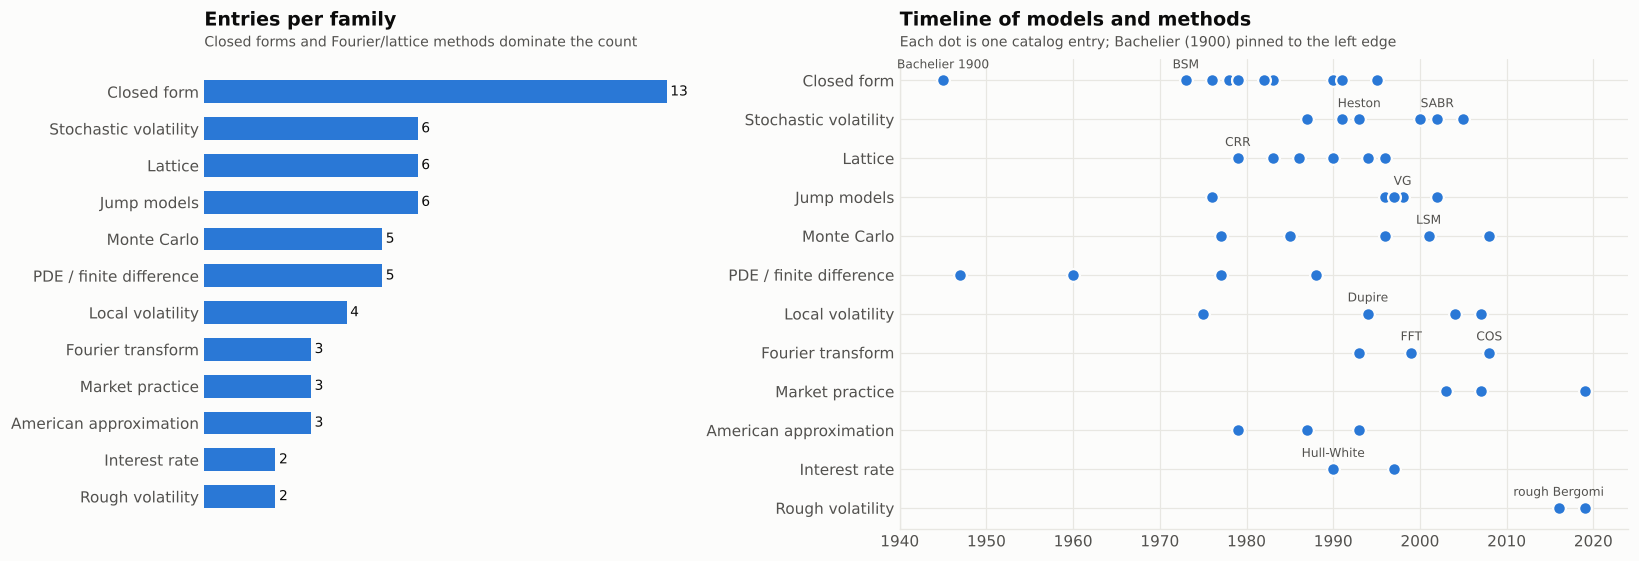

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.5]})

# Left: how many entries per family (one series, one colour, value labels instead of an axis)
cnt = catalog["family"].value_counts().sort_values()
ax = axes[0]
ax.barh(cnt.index, cnt.values, color=PALETTE[0], height=0.62)
for y, v in enumerate(cnt.values):
    ax.text(v + 0.1, y, str(v), va="center", fontsize=9, color=INK)
ax.grid(axis="y", visible=False); ax.set_xticks([])
for s in ["bottom", "left"]: ax.spines[s].set_visible(False)
style(ax, "Entries per family", "Closed forms and Fourier/lattice methods dominate the count")

# Right: 120 years of option pricing on one timeline (Bachelier gets his own exile on the left edge)
ax = axes[1]
fams = cnt.index.tolist()
ypos = {f: i for i, f in enumerate(fams)}
yrs = catalog["year"].clip(lower=1945)
ax.scatter(yrs, catalog["family"].map(ypos), s=70, color=PALETTE[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
famous = {"Black-Scholes-Merton": "BSM", "Heston": "Heston", "Dupire local volatility": "Dupire",
          "SABR": "SABR", "Rough Bergomi": "rough Bergomi", "Longstaff-Schwartz (LSM)": "LSM",
          "COS method": "COS", "Cox-Ross-Rubinstein binomial": "CRR", "Bachelier (normal model)": "Bachelier 1900",
          "Carr-Madan FFT": "FFT", "Variance Gamma": "VG", "Hull-White one-factor": "Hull-White"}
for _, r in catalog[catalog["name"].isin(famous)].iterrows():
    ax.annotate(famous[r["name"]], (max(r["year"], 1945), ypos[r["family"]]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.set_yticks(range(len(fams)), fams); ax.set_xlim(1940, 2024)
style(ax, "Timeline of models and methods", "Each dot is one catalog entry; Bachelier (1900) pinned to the left edge")
plt.tight_layout(); plt.show()

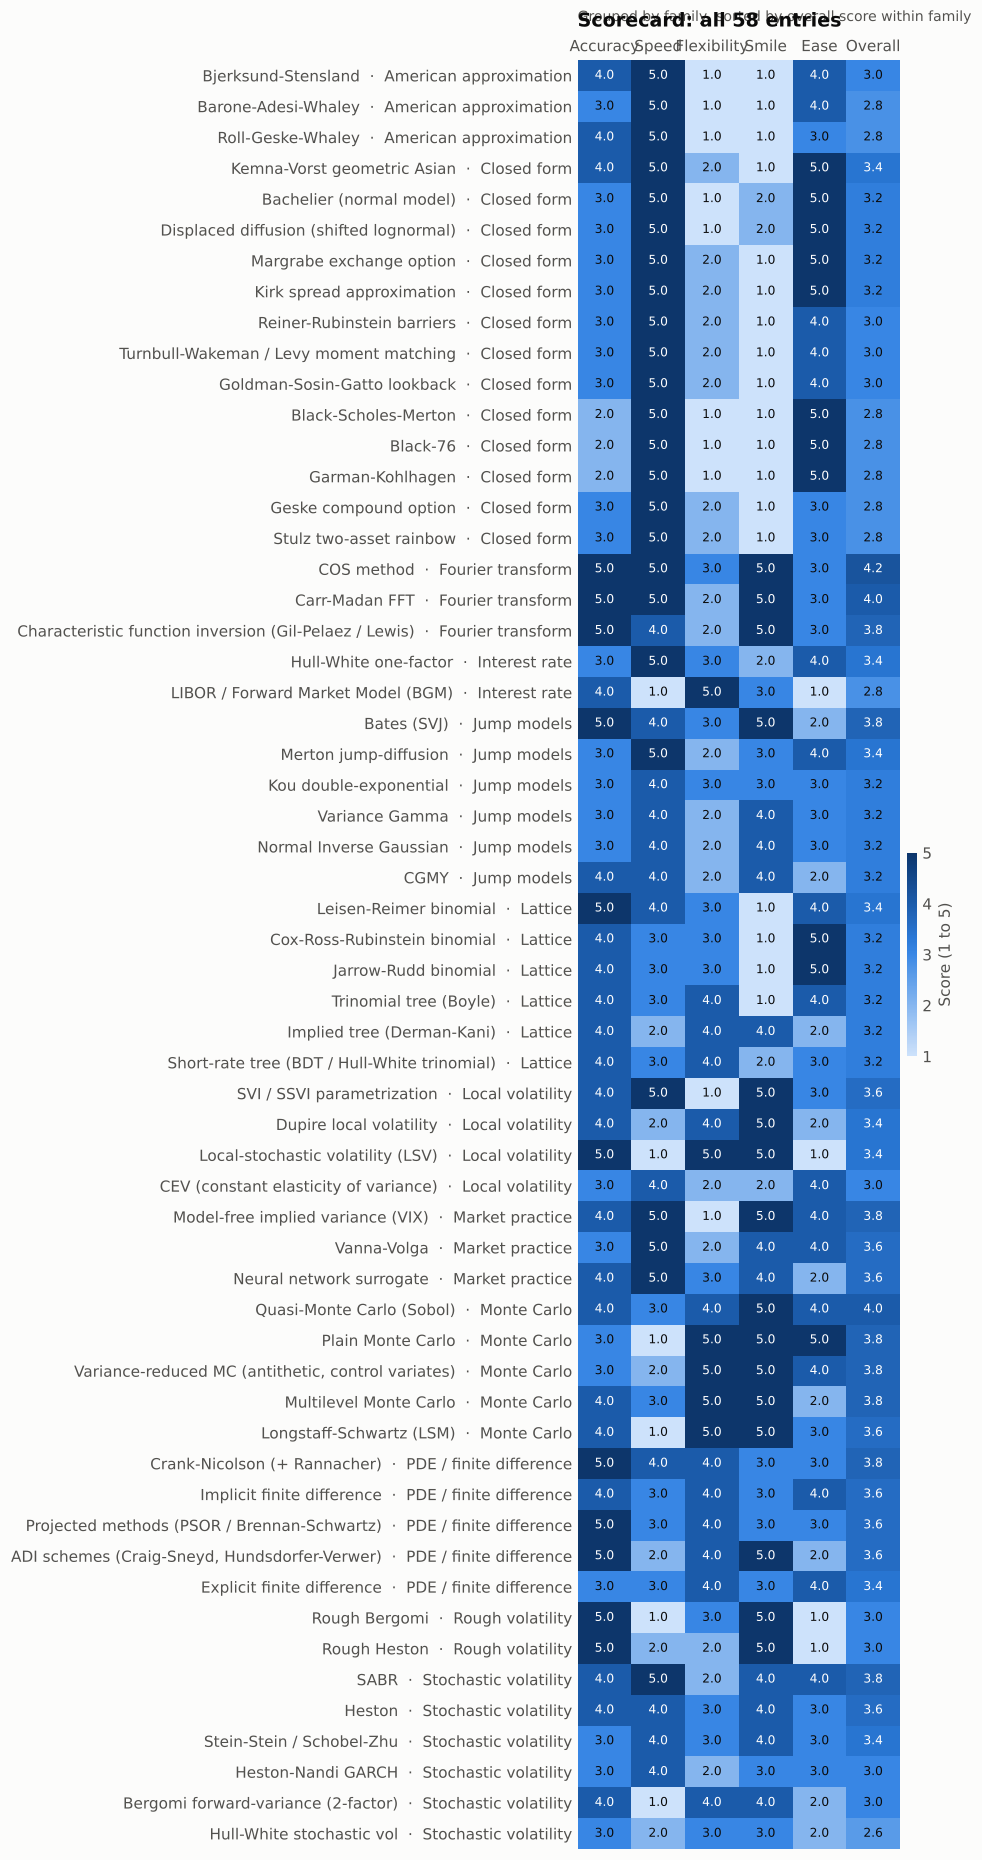

In [5]:
# Score heatmap: every entry, every score. Sequential blue = more is better, no rainbow nonsense.
order = catalog.sort_values(["family", "overall"], ascending=[True, False])
fig, ax = plt.subplots(figsize=(9, 17))
heatmap(ax, order[SCORES + ["overall"]].values, [s.capitalize() for s in SCORES] + ["Overall"],
        (order["name"] + "  ·  " + order["family"]).tolist(), fmt="{:.1f}", vmin=1, vmax=5, cbar="Score (1 to 5)")
ax.xaxis.tick_top()
style(ax, "Scorecard: all 58 entries", "Grouped by family, sorted by overall score within family")
plt.tight_layout(); plt.show()

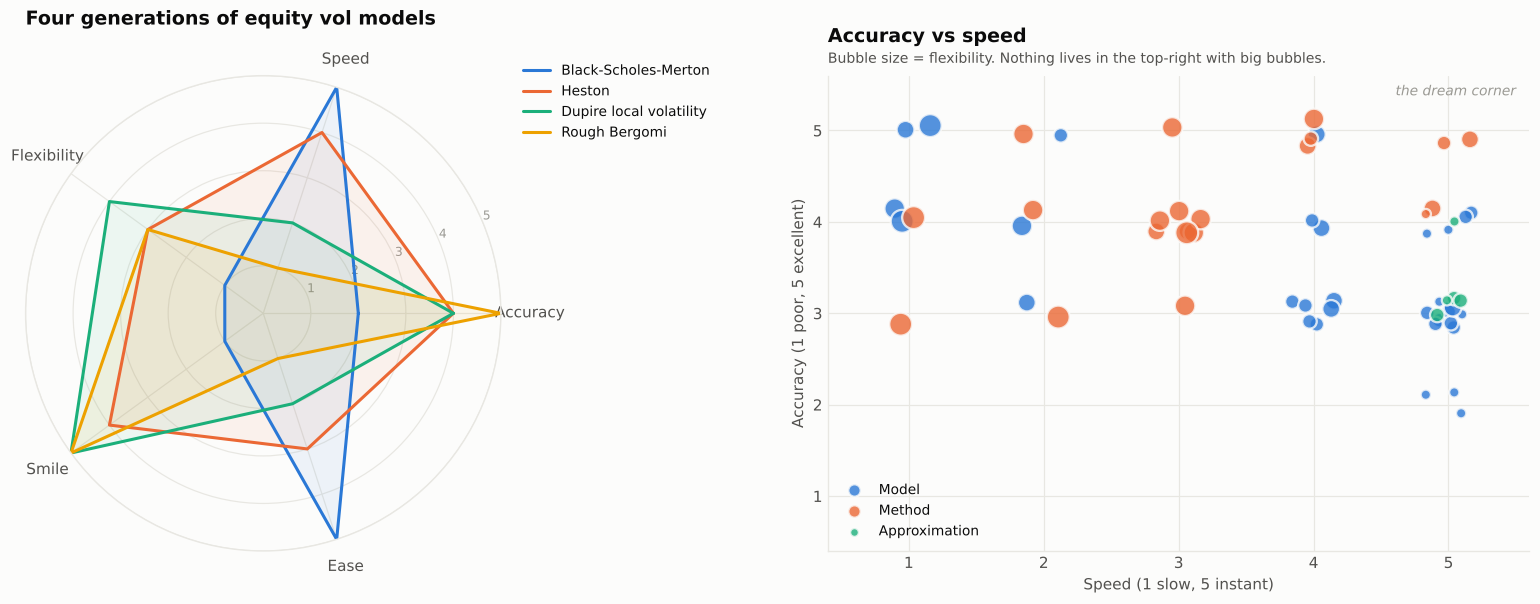

In [6]:
fig = plt.figure(figsize=(15, 5.6))

# Radar: four generations of equity vol modelling. Four series max, legend + colour in fixed slot order.
ax = fig.add_subplot(1, 2, 1, polar=True)
picks = ["Black-Scholes-Merton", "Heston", "Dupire local volatility", "Rough Bergomi"]
ang = np.linspace(0, 2 * np.pi, len(SCORES), endpoint=False).tolist(); ang += ang[:1]
for i, name in enumerate(picks):
    vals = catalog.set_index("name").loc[name, SCORES].tolist(); vals += vals[:1]
    ax.plot(ang, vals, color=PALETTE[i], lw=2, label=name)
    ax.fill(ang, vals, color=PALETTE[i], alpha=0.07)
ax.set_xticks(ang[:-1], [s.capitalize() for s in SCORES], color=INK2)
ax.set_yticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5"], color=MUTED, fontsize=8)
ax.set_ylim(0, 5); ax.spines["polar"].set_color(GRID); ax.grid(color=GRID); ax.tick_params(axis="x", pad=12)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.05))
ax.set_title("Four generations of equity vol models", pad=18)

# Bubble: accuracy vs speed, coloured by kind (3 groups, the all-pairs-safe limit), size = flexibility
ax = fig.add_subplot(1, 2, 2)
jit = np.random.default_rng(SEED).uniform(-0.17, 0.17, (len(catalog), 2))
for i, k in enumerate(["Model", "Method", "Approximation"]):
    m = (catalog["kind"] == k).values
    ax.scatter(catalog.loc[m, "speed"] + jit[m, 0], catalog.loc[m, "accuracy"] + jit[m, 1],
               s=catalog.loc[m, "flexibility"] * 45, color=PALETTE[i], alpha=0.8, edgecolor=SURFACE, lw=1.5, label=k)
ax.set_xlim(0.4, 5.6); ax.set_ylim(0.4, 5.6)
ax.legend(loc="lower left", markerscale=0.7)
ax.text(5.5, 5.5, "the dream corner", ha="right", va="top", color=MUTED, fontsize=9, style="italic")
style(ax, "Accuracy vs speed", "Bubble size = flexibility. Nothing lives in the top-right with big bubbles.",
      "Speed (1 slow, 5 instant)", "Accuracy (1 poor, 5 excellent)")
plt.tight_layout(); plt.show()

## 5. Closed-form models

| Model | Price |
|---|---|
| BSM | $C = Se^{-qT}N(d_1)-Ke^{-rT}N(d_2)$, $d_{1,2}=\frac{\ln(S/K)+(r-q\pm\frac12\sigma^2)T}{\sigma\sqrt T}$ |
| Black-76 | $e^{-rT}[FN(d_1)-KN(d_2)]$ |
| Bachelier | $e^{-rT}[(F-K)N(d)+\sigma_N\sqrt T\,\phi(d)]$, $d=\frac{F-K}{\sigma_N\sqrt T}$ |
| Displaced diffusion | Black-76 on $(F+\delta, K+\delta)$ |
| Margrabe | $S_1e^{-q_1T}N(d_1)-S_2e^{-q_2T}N(d_2)$, $\sigma^2=\sigma_1^2+\sigma_2^2-2\rho\sigma_1\sigma_2$ |
| Kirk | Margrabe with $F_2+K$ and $\sigma^2=\sigma_1^2-2\rho\sigma_1\sigma_2\frac{F_2}{F_2+K}+\left(\sigma_2\frac{F_2}{F_2+K}\right)^2$ |
| Reiner-Rubinstein (down-in call, $H\le K$) | $Se^{-qT}(H/S)^{2\lambda}N(y)-Ke^{-rT}(H/S)^{2\lambda-2}N(y-\sigma\sqrt T)$ |
| Geometric Asian | lognormal with $\sigma_G=\sigma\sqrt{\frac{(n+1)(2n+1)}{6n^2}}$ |
| Turnbull-Wakeman / Levy | lognormal with the first two moments of the arithmetic average |
| Goldman-Sosin-Gatto | floating-strike lookback via the running-minimum distribution |
| Geske | $Se^{-qT_2}M(a_1,b_1;\rho)-K_2e^{-rT_2}M(a_2,b_2;\rho)-K_1e^{-rT_1}N(a_2)$, $\rho=\sqrt{T_1/T_2}$ |


### BSM reference contract (S=K=100, T=1, r=3%, q=1%, vol 20%)


,value
call,8.827321
put,6.866891
put-call parity error,0.000000
implied vol round-trip,0.200000
delta,0.573496
gamma,0.019358
vega_per_volpt,0.387152
theta_per_day,-0.013024



### Black-76


,value
Brent call F=75 K=80 T=0.25 vol 35%,3.233543
Bund future put F=131 K=130 T=0.2 vol 6%,0.948747



### Bachelier with F = -0.20%, normal vol 75bp, 2y expiry (Black-76 cannot price any of these)


...

,value
Margrabe closed form,12.401272
MC check (400k),12.387585



### Kirk spread call vs MC: about a cent everywhere here; the error grows for wider spreads and lower correlation


,strike,Kirk,MC (800k),error vs MC
0,0,11.415385,11.406066,0.009319
1,5,7.995124,7.986436,0.008688
2,10,5.337905,5.330887,0.007018
3,20,2.130572,2.121448,0.009124
4,30,0.782089,0.769166,0.012923



### Down-and-in / down-and-out calls (vanilla = 11.3485)


,barrier,down-in (closed form),down-in (MC daily),down-out = vanilla - in
0,70,0.016502,0.018585,11.331975
1,80,0.393275,0.390758,10.955202
2,85,1.224597,1.221603,10.123880
3,90,3.045251,3.069952,8.303225
4,95,6.319060,6.335293,5.029416


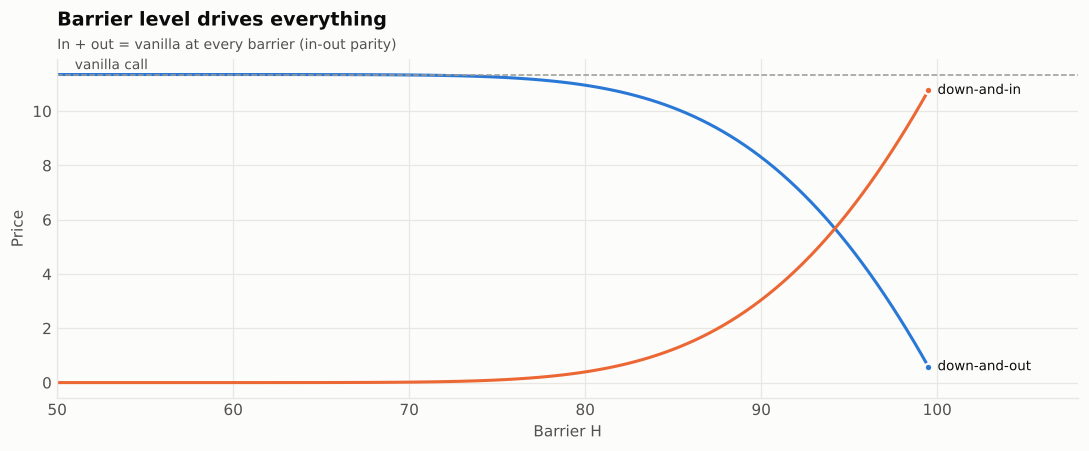


### Geometric Asian, monthly fixings


,value
Kemna-Vorst closed form,7.581942
MC check,7.567636



### Arithmetic Asian, 2y monthly: moment matching is great until vol gets silly


,vol,moment matching,MC + control variate,MC s.e.,error (bp of spot)
0,0.100000,4.959057,4.947751,0.000275,1.130604
1,0.250000,9.705087,9.634156,0.001615,7.093110
2,0.500000,17.918640,17.485917,0.007531,43.272247
3,0.800000,28.177332,26.557354,0.025679,161.997872



### Floating-strike lookback: continuous monitoring overprices discrete fixings


,fixings per year,MC discrete,closed form (continuous)
0,12,16.559792,19.687935
1,52,18.181390,19.687935
2,252,18.976598,19.687935
3,1000,19.302805,19.687935



### Call on call: K1=8 at 6m on a 1y ATM call


,value
Geske closed form,5.858708
MC check,5.857725
underlying call today,11.348477


In [7]:
def _ret(v):
    v = np.asarray(v)
    return v.item() if v.ndim == 0 else v

def bsm(S, K, T, r, sigma, q=0.0, kind="call"):
    S, K, T, sigma = (np.asarray(x, float) for x in (S, K, T, sigma))
    sq = sigma * np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / sq
    d2 = d1 - sq
    if kind == "call":
        v = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    else:
        v = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
    return _ret(v)

def bsm_greeks(S, K, T, r, sigma, q=0.0, kind="call"):
    S, K, T, sigma = (np.asarray(x, float) for x in (S, K, T, sigma))
    sq = sigma * np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / sq
    d2 = d1 - sq
    pdf, eq, er = norm.pdf(d1), np.exp(-q * T), np.exp(-r * T)
    gamma = eq * pdf / (S * sq)
    vega = S * eq * pdf * np.sqrt(T) / 100
    if kind == "call":
        delta = eq * norm.cdf(d1)
        theta = (-S * eq * pdf * sigma / (2 * np.sqrt(T)) - r * K * er * norm.cdf(d2) + q * S * eq * norm.cdf(d1)) / 365
    else:
        delta = -eq * norm.cdf(-d1)
        theta = (-S * eq * pdf * sigma / (2 * np.sqrt(T)) + r * K * er * norm.cdf(-d2) - q * S * eq * norm.cdf(-d1)) / 365
    return {"delta": _ret(delta), "gamma": _ret(gamma), "vega_per_volpt": _ret(vega), "theta_per_day": _ret(theta)}

def implied_vol(price, S, K, T, r, q=0.0, kind="call", lo=1e-4, hi=5.0, iters=90):
    """Vectorized bisection, always via the OTM option (calls above the forward, puts below).
    Bisection is slow-but-certain; Newton is fast-but-moody in the wings. We have numpy, we can afford certain."""
    price, K, T = np.broadcast_arrays(np.asarray(price, float), np.asarray(K, float), np.asarray(T, float))
    F = S * np.exp((r - q) * T)
    disc_S, disc_K = S * np.exp(-q * T), K * np.exp(-r * T)
    if kind == "call":
        use_put = K < F
        target = np.where(use_put, price - disc_S + disc_K, price)
    else:
        use_put = K < F
        target = np.where(use_put, price, price + disc_S - disc_K)
    lo_a, hi_a = np.full(target.shape, lo), np.full(target.shape, hi)
    for _ in range(iters):
        mid = 0.5 * (lo_a + hi_a)
        pm = np.where(use_put, bsm(S, K, T, r, mid, q, "put"), bsm(S, K, T, r, mid, q, "call"))
        up = pm > target
        hi_a = np.where(up, mid, hi_a); lo_a = np.where(up, lo_a, mid)
    iv = 0.5 * (lo_a + hi_a)
    intrinsic = np.where(use_put, np.maximum(disc_K - disc_S, 0), np.maximum(disc_S - disc_K, 0))
    iv = np.where((target <= intrinsic + 1e-12) | (iv >= hi * 0.999), np.nan, iv)
    return _ret(iv)

@demo("bsm")
def demo_bsm():
    c, p = bsm(S0, K0, T0, R0, SIG0, Q0), bsm(S0, K0, T0, R0, SIG0, Q0, "put")
    g = bsm_greeks(S0, K0, T0, R0, SIG0, Q0)
    show({"call": c, "put": p, "put-call parity error": c - p - (S0 * math.exp(-Q0 * T0) - K0 * math.exp(-R0 * T0)),
          "implied vol round-trip": implied_vol(c, S0, K0, T0, R0, Q0), **g}, "BSM reference contract (S=K=100, T=1, r=3%, q=1%, vol 20%)")

def black76(F, K, T, r, sigma, kind="call"):
    return bsm(F, K, T, r, sigma, q=r, kind=kind)  # F e^{-rT}: the forward is a stock paying dividends at r

@demo("black76")
def demo_black76():
    show({"Brent call F=75 K=80 T=0.25 vol 35%": black76(75, 80, 0.25, 0.04, 0.35),
          "Bund future put F=131 K=130 T=0.2 vol 6%": black76(131, 130, 0.2, 0.025, 0.06, "put")}, "Black-76")

def bachelier(F, K, T, r, sigma_n, kind="call"):
    F, K, T = (np.asarray(x, float) for x in (F, K, T))
    sd = sigma_n * np.sqrt(T)
    d = (F - K) / sd
    call = np.exp(-r * T) * ((F - K) * norm.cdf(d) + sd * norm.pdf(d))
    return _ret(call if kind == "call" else call - np.exp(-r * T) * (F - K))

@demo("bachelier")
def demo_bachelier():
    # Negative forward: Black-76 takes log(-0.002) and dies. Bachelier shrugs.
    rows = []
    for K in [-0.005, -0.002, 0.0, 0.002, 0.005]:
        rows.append({"strike": K, "receiver/put price (bp of annuity)": bachelier(-0.002, K, 2.0, 0.0, 0.0075, "put") * 1e4,
                     "payer/call price (bp)": bachelier(-0.002, K, 2.0, 0.0, 0.0075) * 1e4})
    show(pd.DataFrame(rows), "Bachelier with F = -0.20%, normal vol 75bp, 2y expiry (Black-76 cannot price any of these)")

def garman_kohlhagen(S, K, T, rd, rf, sigma, kind="call"):
    return bsm(S, K, T, rd, sigma, q=rf, kind=kind)

@demo("gk")
def demo_gk():
    show({"EUR/SEK 3m 11.30 call (S 11.15, vol 7%)": garman_kohlhagen(11.15, 11.30, 0.25, 0.0200, 0.0225, 0.07),
          "USD/SEK 1y 10.00 put (S 10.45, vol 10%)": garman_kohlhagen(10.45, 10.00, 1.0, 0.020, 0.040, 0.10, "put")},
         "Garman-Kohlhagen (price in SEK per unit of foreign currency)")

def displaced_diffusion(F, K, T, r, sigma, shift, kind="call"):
    return black76(np.asarray(F) + shift, np.asarray(K) + shift, T, r, sigma, kind)

@demo("displaced")
def demo_displaced():
    Ks = np.array([0.0, 0.01, 0.02, 0.03, 0.04])
    p = displaced_diffusion(0.02, Ks, 2.0, 0.0, 0.20, 0.02)
    show(pd.DataFrame({"strike": Ks, "shifted-Black price": p,
                       "equivalent normal vol (bp)": [optimize.brentq(lambda s: bachelier(0.02, k, 2, 0, s) - v, 1e-6, 0.1) * 1e4
                                                      for k, v in zip(Ks, p)]}),
         "Shifted lognormal (shift 2%): prices a zero strike, sits between Black and Bachelier")

def margrabe(S1, S2, T, s1, s2, rho, q1=0.0, q2=0.0):
    s = math.sqrt(s1 ** 2 + s2 ** 2 - 2 * rho * s1 * s2)
    d1 = (math.log(S1 / S2) + (q2 - q1 + 0.5 * s * s) * T) / (s * math.sqrt(T))
    return S1 * math.exp(-q1 * T) * norm.cdf(d1) - S2 * math.exp(-q2 * T) * norm.cdf(d1 - s * math.sqrt(T))

def two_asset_terminal(S1, S2, T, r, s1, s2, rho, n=400_000, seed=SEED, q1=0.0, q2=0.0):
    rng = np.random.default_rng(seed)
    z1 = rng.standard_normal(n // 2); z1 = np.r_[z1, -z1]
    z2 = rng.standard_normal(n // 2); z2 = np.r_[z2, -z2]
    z2 = rho * z1 + math.sqrt(1 - rho ** 2) * z2
    A = S1 * np.exp((r - q1 - 0.5 * s1 ** 2) * T + s1 * math.sqrt(T) * z1)
    B = S2 * np.exp((r - q2 - 0.5 * s2 ** 2) * T + s2 * math.sqrt(T) * z2)
    return A, B

@demo("margrabe")
def demo_margrabe():
    A, B = two_asset_terminal(100, 95, 1.0, 0.03, 0.30, 0.25, 0.6)
    mc = math.exp(-0.03) * np.maximum(A - B, 0).mean()
    show({"Margrabe closed form": margrabe(100, 95, 1.0, 0.30, 0.25, 0.6), "MC check (400k)": mc},
         "Exchange option: receive A, deliver B")

def kirk(F1, F2, K, T, r, s1, s2, rho):
    w = F2 / (F2 + K)
    s = math.sqrt(s1 ** 2 - 2 * rho * s1 * s2 * w + (s2 * w) ** 2)
    d1 = (math.log(F1 / (F2 + K)) + 0.5 * s * s * T) / (s * math.sqrt(T))
    return math.exp(-r * T) * (F1 * norm.cdf(d1) - (F2 + K) * norm.cdf(d1 - s * math.sqrt(T)))

@demo("kirk")
def demo_kirk():
    A, B = two_asset_terminal(80, 70, 0.5, 0.0, 0.40, 0.35, 0.8, n=800_000)
    rows = []
    for K in [0, 5, 10, 20, 30]:
        mc = math.exp(-0.03 * 0.5) * np.maximum(A - B - K, 0).mean()
        kp = kirk(80, 70, K, 0.5, 0.03, 0.40, 0.35, 0.8)
        rows.append({"strike": K, "Kirk": kp, "MC (800k)": mc, "error vs MC": kp - mc})
    show(pd.DataFrame(rows), "Kirk spread call vs MC: about a cent everywhere here; the error grows for wider spreads and lower correlation")

def down_in_call_rr(S, K, H, T, r, sigma, q=0.0):
    """Reiner-Rubinstein down-and-in call for H <= K, continuous monitoring."""
    lam = (r - q + 0.5 * sigma ** 2) / sigma ** 2
    y = math.log(H * H / (S * K)) / (sigma * math.sqrt(T)) + lam * sigma * math.sqrt(T)
    return (S * math.exp(-q * T) * (H / S) ** (2 * lam) * norm.cdf(y)
            - K * math.exp(-r * T) * (H / S) ** (2 * lam - 2) * norm.cdf(y - sigma * math.sqrt(T)))

def gbm_paths(S, T, r, q, sigma, steps, n, seed=SEED):
    rng = np.random.default_rng(seed)
    z = rng.standard_normal((n // 2, steps)); z = np.vstack([z, -z])
    dt = T / steps
    return S * np.exp(np.cumsum((r - q - 0.5 * sigma ** 2) * dt + sigma * math.sqrt(dt) * z, axis=1))

@demo("barrier_rr")
def demo_barrier():
    S, K, T, r, s = 100, 100, 1.0, 0.03, 0.25
    P = gbm_paths(S, T, r, 0, s, 252, 100_000)
    vanilla = bsm(S, K, T, r, s)
    rows = []
    for H in [70, 80, 85, 90, 95]:
        # Broadie-Glasserman-Kou: daily monitoring ~ continuous barrier shifted towards spot by exp(0.5826 s sqrt(dt))
        H_eff = H * math.exp(0.5826 * s * math.sqrt(T / 252))
        hit = P.min(axis=1) <= H_eff
        mc = math.exp(-r * T) * (np.maximum(P[:, -1] - K, 0) * hit).mean()
        cf = down_in_call_rr(S, K, H, T, r, s)
        rows.append({"barrier": H, "down-in (closed form)": cf, "down-in (MC daily)": mc, "down-out = vanilla - in": vanilla - cf})
    df = pd.DataFrame(rows)
    show(df, f"Down-and-in / down-and-out calls (vanilla = {vanilla:.4f})")
    Hs = np.linspace(50, 99.5, 120)
    fig, ax = plt.subplots(figsize=(10, 4.2))
    din = np.array([down_in_call_rr(S, K, h, T, r, s) for h in Hs])
    ax.plot(Hs, vanilla - din, color=PALETTE[0]); ax.plot(Hs, din, color=PALETTE[1])
    ax.axhline(vanilla, color=MUTED, lw=1, ls="--"); ax.text(51, vanilla + 0.2, "vanilla call", color=INK2, fontsize=9)
    end_labels(ax, {"down-and-out": (Hs, vanilla - din, PALETTE[0]), "down-and-in": (Hs, din, PALETTE[1])})
    style(ax, "Barrier level drives everything", "In + out = vanilla at every barrier (in-out parity)", "Barrier H", "Price")
    ax.set_xlim(50, 108); plt.tight_layout(); plt.show()

def geometric_asian(S, K, T, r, sigma, n, q=0.0):
    sg = sigma * math.sqrt((n + 1) * (2 * n + 1) / (6 * n * n))
    nu = (r - q - 0.5 * sigma ** 2) * (n + 1) / (2 * n)
    d1 = (math.log(S / K) + (nu + sg * sg) * T) / (sg * math.sqrt(T))
    return math.exp(-r * T) * (S * math.exp((nu + 0.5 * sg * sg) * T) * norm.cdf(d1) - K * norm.cdf(d1 - sg * math.sqrt(T)))

def asian_levy(S, K, T, r, sigma, n, q=0.0):
    t = T * np.arange(1, n + 1) / n
    g = r - q
    M1 = S * np.mean(np.exp(g * t))
    tt = np.minimum.outer(t, t)
    M2 = S * S * np.mean(np.exp(g * (t[:, None] + t[None, :]) + sigma ** 2 * tt))
    sA = math.sqrt(math.log(M2 / M1 ** 2) / T)
    d1 = (math.log(M1 / K) + 0.5 * sA * sA * T) / (sA * math.sqrt(T))
    return math.exp(-r * T) * (M1 * norm.cdf(d1) - K * norm.cdf(d1 - sA * math.sqrt(T)))

def asian_mc_cv(S, K, T, r, sigma, n, paths=200_000, q=0.0, seed=SEED):
    P = gbm_paths(S, T, r, q, sigma, n, paths, seed)
    arith = math.exp(-r * T) * np.maximum(P.mean(axis=1) - K, 0)
    geo = math.exp(-r * T) * np.maximum(np.exp(np.log(P).mean(axis=1)) - K, 0)
    b = np.cov(arith, geo)[0, 1] / geo.var()
    est = arith - b * (geo - geometric_asian(S, K, T, r, sigma, n, q))
    return est.mean(), est.std() / math.sqrt(paths)

@demo("asian_geo")
def demo_asian_geo():
    P = gbm_paths(100, 1, 0.03, 0, 0.3, 12, 200_000)
    mc = math.exp(-0.03) * np.maximum(np.exp(np.log(P).mean(axis=1)) - 100, 0).mean()
    show({"Kemna-Vorst closed form": geometric_asian(100, 100, 1, 0.03, 0.3, 12), "MC check": mc},
         "Geometric Asian, monthly fixings")

@demo("asian_tw")
def demo_asian_tw():
    rows = []
    for vol in [0.10, 0.25, 0.50, 0.80]:
        mc, se = asian_mc_cv(100, 100, 2.0, 0.03, vol, 24)
        lv = asian_levy(100, 100, 2.0, 0.03, vol, 24)
        rows.append({"vol": vol, "moment matching": lv, "MC + control variate": mc, "MC s.e.": se, "error (bp of spot)": (lv - mc) * 100})
    show(pd.DataFrame(rows), "Arithmetic Asian, 2y monthly: moment matching is great until vol gets silly")

def lookback_float_call(S, T, r, sigma, q=0.0, Smin=None):
    Smin = S if Smin is None else Smin
    b = r - q
    a1 = (math.log(S / Smin) + (b + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    a2 = a1 - sigma * math.sqrt(T)
    a3 = (math.log(S / Smin) + (-b + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    Y1 = -2 * (b - 0.5 * sigma ** 2) * math.log(S / Smin) / sigma ** 2
    k = sigma ** 2 / (2 * b)
    return (S * math.exp(-q * T) * norm.cdf(a1) - S * math.exp(-q * T) * k * norm.cdf(-a1)
            - Smin * math.exp(-r * T) * (norm.cdf(a2) - k * math.exp(Y1) * norm.cdf(-a3)))

@demo("lookback_gsg")
def demo_lookback():
    rows = []
    for steps in [12, 52, 252, 1000]:
        P = gbm_paths(100, 1, 0.03, 0.0, 0.25, steps, 60_000 if steps <= 252 else 20_000)  # RAM is not infinite
        mn = np.minimum(P.min(axis=1), 100)
        rows.append({"fixings per year": steps, "MC discrete": math.exp(-0.03) * (P[:, -1] - mn).mean()})
    df = pd.DataFrame(rows); df["closed form (continuous)"] = lookback_float_call(100, 1, 0.03, 0.25)
    show(df, "Floating-strike lookback: continuous monitoring overprices discrete fixings")

def geske_call_on_call(S, K1, T1, K2, T2, r, sigma, q=0.0):
    """Call (strike K1, expiry T1) on a call (strike K2, expiry T2)."""
    Sstar = optimize.brentq(lambda s: bsm(s, K2, T2 - T1, r, sigma, q) - K1, 1e-6, 100 * S)
    rho = math.sqrt(T1 / T2)
    a1 = (math.log(S / Sstar) + (r - q + 0.5 * sigma ** 2) * T1) / (sigma * math.sqrt(T1)); a2 = a1 - sigma * math.sqrt(T1)
    b1 = (math.log(S / K2) + (r - q + 0.5 * sigma ** 2) * T2) / (sigma * math.sqrt(T2)); b2 = b1 - sigma * math.sqrt(T2)
    M = lambda x, y: multivariate_normal.cdf([x, y], mean=[0, 0], cov=[[1, rho], [rho, 1]])
    return (S * math.exp(-q * T2) * M(a1, b1) - K2 * math.exp(-r * T2) * M(a2, b2)
            - K1 * math.exp(-r * T1) * norm.cdf(a2))

@demo("geske")
def demo_geske():
    # MC only needs S at T1: the inner option is BSM exactly. One-dimensional, so it converges fast.
    rng = np.random.default_rng(SEED)
    z = rng.standard_normal(500_000)
    ST1 = 100 * np.exp((0.03 - 0.5 * 0.25 ** 2) * 0.5 + 0.25 * math.sqrt(0.5) * z)
    mc = math.exp(-0.03 * 0.5) * np.maximum(bsm(ST1, 100, 0.5, 0.03, 0.25) - 8, 0).mean()
    show({"Geske closed form": geske_call_on_call(100, 8, 0.5, 100, 1.0, 0.03, 0.25), "MC check": mc,
          "underlying call today": bsm(100, 100, 1.0, 0.03, 0.25)}, "Call on call: K1=8 at 6m on a 1y ATM call")

for k in ["bsm", "black76", "bachelier", "gk", "displaced", "margrabe", "kirk", "barrier_rr", "asian_geo",
          "asian_tw", "lookback_gsg", "geske"]:
    DEMOS[k]()

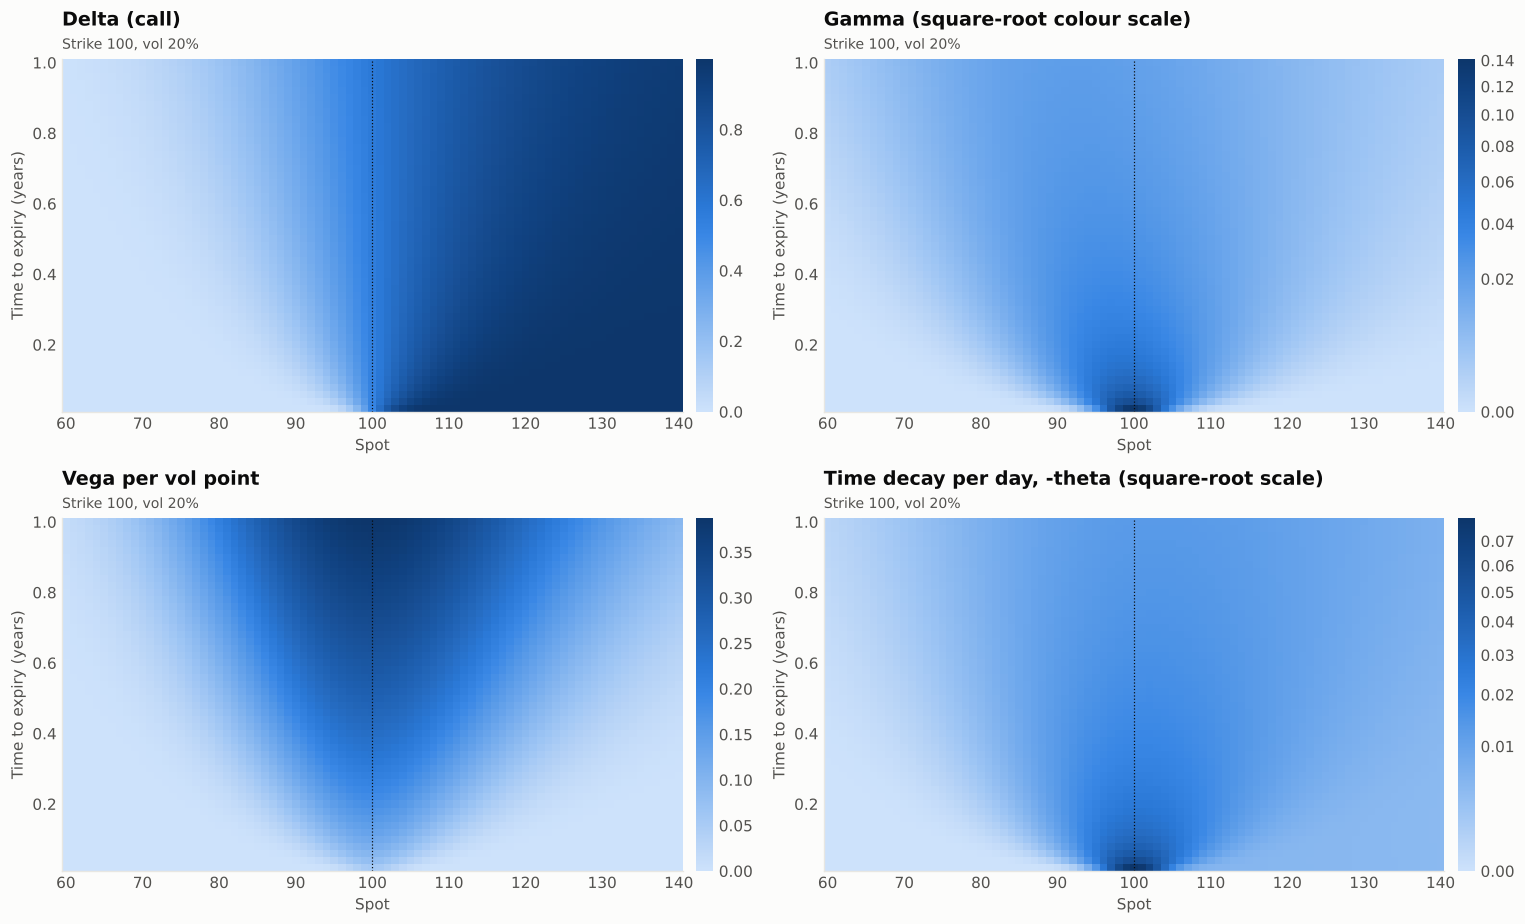

In [8]:
# Greeks landscape: where does the risk live? Gamma and vega concentrate at the strike near expiry, theta follows.
Sg = np.linspace(60, 140, 81); Tg = np.linspace(0.02, 1.0, 50)
SS, TT = np.meshgrid(Sg, Tg)
G = bsm_greeks(SS, 100.0, TT, R0, SIG0, Q0)
panels = [("Delta (call)", G["delta"], None), ("Gamma (square-root colour scale)", G["gamma"], PowerNorm(0.5)),
          ("Vega per vol point", G["vega_per_volpt"], None), ("Time decay per day, -theta (square-root scale)", -G["theta_per_day"], PowerNorm(0.5))]
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for ax, (title, Z, nrm) in zip(axes.ravel(), panels):
    # gamma and theta explode at the strike near expiry; a sqrt scale keeps the rest of the map visible
    im = ax.pcolormesh(Sg, Tg, Z, cmap=SEQ_CMAP, shading="auto", norm=nrm)
    ax.axvline(100, color=INK, lw=0.8, ls=":"); ax.grid(False)
    cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False)
    style(ax, title, "Strike 100, vol 20%", "Spot", "Time to expiry (years)")
plt.tight_layout(); plt.show()

## 6. Lattices

| Tree | Parameters |
|---|---|
| CRR | $u=e^{\sigma\sqrt{\Delta t}}$, $d=1/u$, $p=\frac{e^{(r-q)\Delta t}-d}{u-d}$ |
| Jarrow-Rudd | $u,d=e^{(r-q-\sigma^2/2)\Delta t\pm\sigma\sqrt{\Delta t}}$, $p=\tfrac12$ |
| Leisen-Reimer | $p=h(d_2)$, $p'=h(d_1)$ with Peizer-Pratt $h(z)=\tfrac12+\text{sgn}(z)\sqrt{\tfrac14-\tfrac14e^{-\left(\frac{z}{n+1/3+0.1/(n+1)}\right)^2(n+1/6)}}$, $u=e^{(r-q)\Delta t}p'/p$ |
| Trinomial | $u=e^{\sigma\sqrt{2\Delta t}}$, $p_{u,d}=\left(\frac{\pm e^{(r-q)\Delta t/2}\mp e^{\mp\sigma\sqrt{\Delta t/2}}}{e^{\sigma\sqrt{\Delta t/2}}-e^{-\sigma\sqrt{\Delta t/2}}}\right)^2$ |

**When to use:** American and Bermudan vanillas, teaching, short-rate models. **Why Leisen-Reimer wins:** it aligns nodes with the strike, so the odd/even sawtooth of CRR disappears and convergence goes from $O(1/n)$ to roughly $O(1/n^2)$.


### CRR tree, K=105 call (BSM 6.638061)


,steps,price,abs error vs BSM
0,25,6.616112,0.021949
1,50,6.634443,0.003618
2,100,6.644279,0.006218
3,200,6.643494,0.005432
4,400,6.642601,0.004540
5,American put 400,9.839842,NaN



### JR tree, K=105 call (BSM 6.638061)


,steps,price,abs error vs BSM
0,25,6.615858,0.022203
1,50,6.634316,0.003745
2,100,6.644216,0.006155
3,200,6.643462,0.005401
4,400,6.642585,0.004524
5,American put 400,9.839854,NaN



### LR tree, K=105 call (BSM 6.638061)


,steps,price,abs error vs BSM
0,25,6.637468,0.000593
1,50,6.637914,0.000147
2,100,6.638023,0.000038
3,200,6.638052,0.000010
4,400,6.638059,0.000002
5,American put 400,9.841002,NaN



### Trinomial tree, K=105 call


,steps,price,abs error
0,25,6.634443,0.003618
1,50,6.644279,0.006218
2,100,6.643494,0.005432
3,200,6.642601,0.004540
4,400,6.640355,0.002294


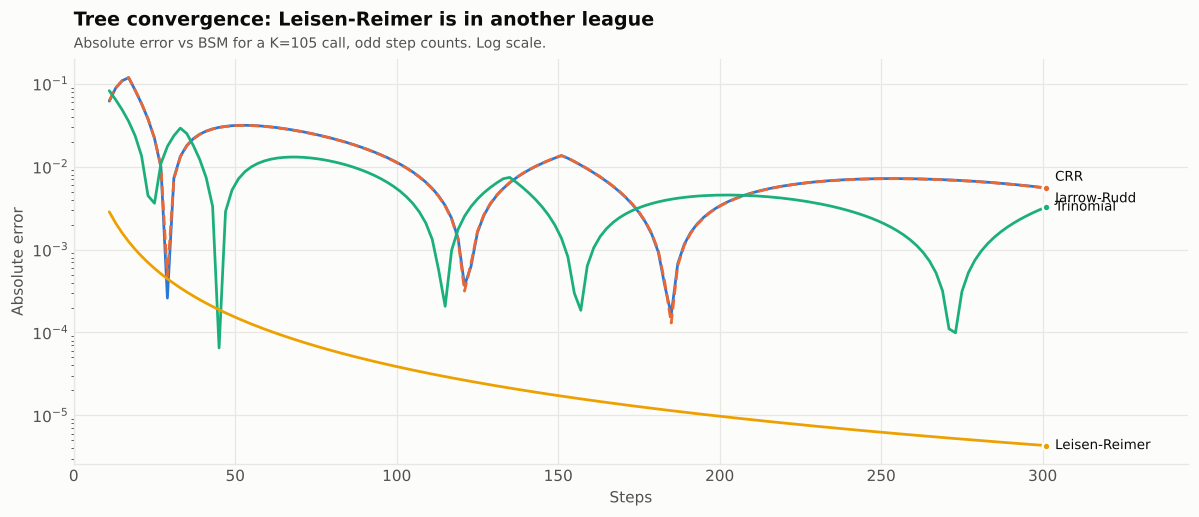

In [9]:
def binomial(S, K, T, r, sigma, q=0.0, n=200, kind="call", american=False, scheme="crr"):
    dt = T / n
    g = math.exp((r - q) * dt)
    if scheme == "crr":
        u = math.exp(sigma * math.sqrt(dt)); d = 1 / u; p = (g - d) / (u - d)
    elif scheme == "jr":
        nu = (r - q - 0.5 * sigma ** 2) * dt
        u = math.exp(nu + sigma * math.sqrt(dt)); d = math.exp(nu - sigma * math.sqrt(dt)); p = 0.5
    elif scheme == "lr":
        if n % 2 == 0: n += 1; dt = T / n; g = math.exp((r - q) * dt)  # LR wants odd n, and it always gets what it wants
        d1 = (math.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T)); d2 = d1 - sigma * math.sqrt(T)
        h = lambda z: 0.5 + math.copysign(1, z) * math.sqrt(0.25 - 0.25 * math.exp(-(z / (n + 1 / 3 + 0.1 / (n + 1))) ** 2 * (n + 1 / 6)))
        p = h(d2); pb = h(d1); u = g * pb / p; d = (g - p * u) / (1 - p)
    else:
        raise ValueError(scheme)
    disc = math.exp(-r * dt)
    j = np.arange(n + 1)
    ST = S * u ** (n - j) * d ** j
    V = np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)
    for i in range(n - 1, -1, -1):
        V = disc * (p * V[:-1] + (1 - p) * V[1:])
        if american:
            Si = S * u ** (i - np.arange(i + 1)) * d ** np.arange(i + 1)
            V = np.maximum(V, (Si - K) if kind == "call" else (K - Si))
    return float(V[0])

def trinomial(S, K, T, r, sigma, q=0.0, n=200, kind="call", american=False):
    dt = T / n
    u = math.exp(sigma * math.sqrt(2 * dt))
    a, b = math.exp((r - q) * dt / 2), math.exp(sigma * math.sqrt(dt / 2))
    pu = ((a - 1 / b) / (b - 1 / b)) ** 2
    pd_ = ((b - a) / (b - 1 / b)) ** 2
    pm = 1 - pu - pd_
    disc = math.exp(-r * dt)
    ST = S * u ** np.arange(n, -n - 1, -1)
    V = np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)
    for i in range(n - 1, -1, -1):
        V = disc * (pu * V[:-2] + pm * V[1:-1] + pd_ * V[2:])
        if american:
            Si = S * u ** np.arange(i, -i - 1, -1)
            V = np.maximum(V, (Si - K) if kind == "call" else (K - Si))
    return float(V[0])

for key, scheme in [("crr", "crr"), ("jr", "jr"), ("lr", "lr")]:
    def _d(scheme=scheme):
        ex = bsm(S0, 105, T0, R0, SIG0, Q0)
        rows = [{"steps": n, "price": binomial(S0, 105, T0, R0, SIG0, Q0, n, scheme=scheme),
                 "abs error vs BSM": abs(binomial(S0, 105, T0, R0, SIG0, Q0, n, scheme=scheme) - ex)} for n in [25, 50, 100, 200, 400]]
        rows.append({"steps": "American put 400", "price": binomial(S0, 105, T0, R0, SIG0, Q0, 401, "put", True, scheme), "abs error vs BSM": np.nan})
        show(pd.DataFrame(rows), f"{scheme.upper()} tree, K=105 call (BSM {ex:.6f})")
    demo(key)(_d)

@demo("trinomial")
def demo_tri():
    ex = bsm(S0, 105, T0, R0, SIG0, Q0)
    show(pd.DataFrame([{"steps": n, "price": trinomial(S0, 105, T0, R0, SIG0, Q0, n),
                        "abs error": abs(trinomial(S0, 105, T0, R0, SIG0, Q0, n) - ex)} for n in [25, 50, 100, 200, 400]]),
         "Trinomial tree, K=105 call")

for k in ["crr", "jr", "lr", "trinomial"]:
    DEMOS[k]()

# Convergence picture: the sawtooth that made Leisen and Reimer famous
ns = np.arange(11, 302, 2)
ex = bsm(S0, 105, T0, R0, SIG0, Q0)
err = {"CRR": [abs(binomial(S0, 105, T0, R0, SIG0, Q0, n) - ex) for n in ns],
       "Jarrow-Rudd": [abs(binomial(S0, 105, T0, R0, SIG0, Q0, n, scheme="jr") - ex) for n in ns],
       "Trinomial": [abs(trinomial(S0, 105, T0, R0, SIG0, Q0, n) - ex) for n in ns],
       "Leisen-Reimer": [abs(binomial(S0, 105, T0, R0, SIG0, Q0, n, scheme="lr") - ex) for n in ns]}
fig, ax = plt.subplots(figsize=(11, 4.8))
nudge = {"CRR": 7, "Jarrow-Rudd": -7}
for i, (nm, e) in enumerate(err.items()):
    ax.plot(ns, e, color=PALETTE[i], lw=1.8, ls="--" if nm == "Jarrow-Rudd" else "-")  # JR hides under CRR at this drift
end_labels(ax, {nm: (ns, np.array(e), PALETTE[i], nudge.get(nm, 0)) for i, (nm, e) in enumerate(err.items())})
ax.set_yscale("log"); ax.set_xlim(0, 345)
style(ax, "Tree convergence: Leisen-Reimer is in another league",
      "Absolute error vs BSM for a K=105 call, odd step counts. Log scale.", "Steps", "Absolute error")
plt.tight_layout(); plt.show()

## 7. American approximations

**Barone-Adesi-Whaley (1987):** the early-exercise premium satisfies the BSM PDE; drop a small term and you get an ODE with solution $A(S/S^*)^{q}$. Solve once for the critical price $S^*$.

**Bjerksund-Stensland (1993):** assume a flat exercise boundary $I$ and price the resulting barrier-like claim in closed form. It is a lower bound, which risk managers like.

Both are graded against a 1,001-step Leisen-Reimer tree.


### American put (K=100, r=5%, vol 25%): BAW vs tree


,S,T,LR tree 1001,BAW,BAW error
0,80,0.250000,20.000000,20.000000,0.000000
1,80,1.000000,20.362668,20.277670,-0.084997
2,80,3.000000,21.883144,21.815504,-0.067641
3,90,0.250000,10.695212,10.643148,-0.052063
4,90,1.000000,13.039684,12.981660,-0.058025
5,90,3.000000,15.992810,16.015347,0.022538
6,100,0.250000,4.460040,4.450589,-0.009450
7,100,1.000000,7.974270,7.982520,0.008250
8,100,3.000000,11.706216,11.815962,0.109746
9,110,0.250000,1.422870,1.430337,0.007467



### Bjerksund-Stensland: a lower bound, as promised


,S,T,LR tree 1001,Bjerksund-Stensland,BjS error
0,80,0.250000,20.000000,20.000000,0.000000
1,80,1.000000,20.362668,20.308008,-0.054660
2,80,3.000000,21.883144,21.805407,-0.077738
3,90,0.250000,10.695212,10.637436,-0.057775
4,90,1.000000,13.039684,12.917629,-0.122055
5,90,3.000000,15.992810,15.877981,-0.114829
6,100,0.250000,4.460040,4.410766,-0.049273
7,100,1.000000,7.974270,7.853954,-0.120316
8,100,3.000000,11.706216,11.577744,-0.128472
9,110,0.250000,1.422870,1.405906,-0.016964


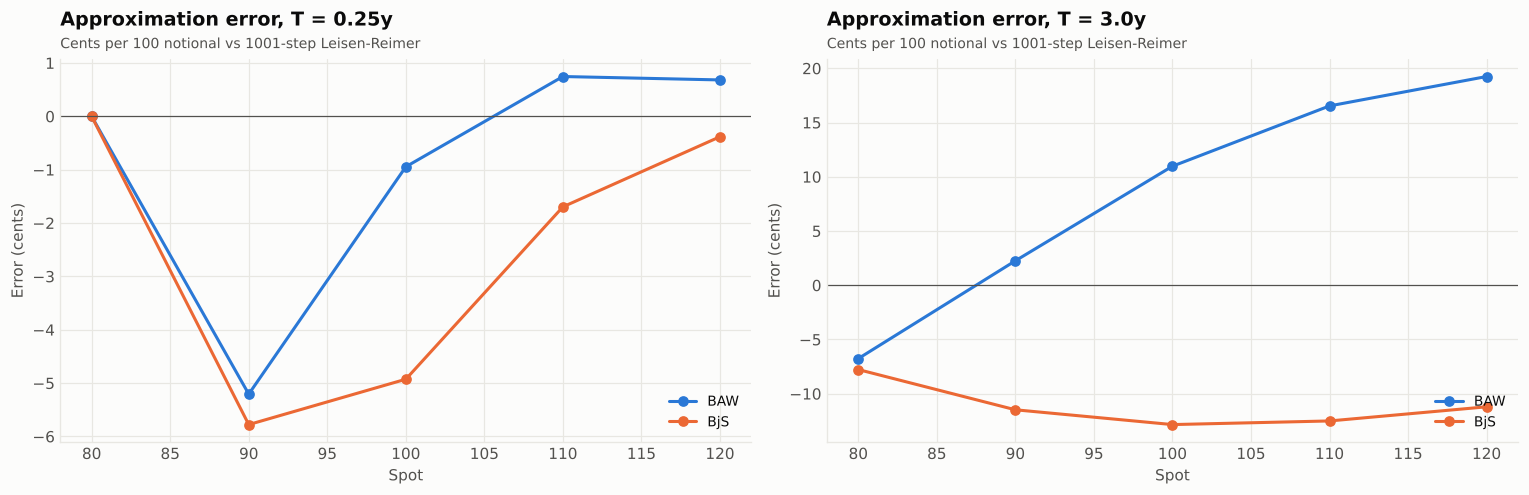

In [10]:
def baw(S, K, T, r, sigma, q=0.0, kind="call"):
    b = r - q
    euro = lambda s: bsm(s, K, T, r, sigma, q, kind)
    if kind == "call" and b >= r:
        return euro(S)  # no dividend, no early exercise of calls; Merton said so in 1973
    Nn, M, Kf = 2 * b / sigma ** 2, 2 * r / sigma ** 2, 1 - math.exp(-r * T)
    d1 = lambda s: (math.log(s / K) + (b + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    if kind == "call":
        q2 = (-(Nn - 1) + math.sqrt((Nn - 1) ** 2 + 4 * M / Kf)) / 2
        f = lambda s: s - K - euro(s) - (1 - math.exp((b - r) * T) * norm.cdf(d1(s))) * s / q2
        Ss = optimize.brentq(f, K * 1.0000001, K * 100)
        if S >= Ss: return S - K
        A2 = Ss / q2 * (1 - math.exp((b - r) * T) * norm.cdf(d1(Ss)))
        return euro(S) + A2 * (S / Ss) ** q2
    q1 = (-(Nn - 1) - math.sqrt((Nn - 1) ** 2 + 4 * M / Kf)) / 2
    f = lambda s: K - s - euro(s) + (1 - math.exp((b - r) * T) * norm.cdf(-d1(s))) * s / q1
    Ss = optimize.brentq(f, K * 1e-4, K * 0.9999999)
    if S <= Ss: return K - S
    A1 = -Ss / q1 * (1 - math.exp((b - r) * T) * norm.cdf(-d1(Ss)))
    return euro(S) + A1 * (S / Ss) ** q1

def _bjs_call(S, K, T, r, b, sigma):
    if b >= r:
        return bsm(S, K, T, r, sigma, q=r - b)
    beta = (0.5 - b / sigma ** 2) + math.sqrt((b / sigma ** 2 - 0.5) ** 2 + 2 * r / sigma ** 2)
    Binf = beta / (beta - 1) * K
    B0 = max(K, r / (r - b) * K)
    h = -(b * T + 2 * sigma * math.sqrt(T)) * B0 / (Binf - B0)
    I = B0 + (Binf - B0) * (1 - math.exp(h))
    if S >= I:
        return S - K
    alpha = (I - K) * I ** (-beta)
    def phi(S, T, gamma, H, I):
        lam = (-r + gamma * b + 0.5 * gamma * (gamma - 1) * sigma ** 2) * T
        d = -(math.log(S / H) + (b + (gamma - 0.5) * sigma ** 2) * T) / (sigma * math.sqrt(T))
        kap = 2 * b / sigma ** 2 + (2 * gamma - 1)
        return math.exp(lam) * S ** gamma * (norm.cdf(d) - (I / S) ** kap * norm.cdf(d - 2 * math.log(I / S) / (sigma * math.sqrt(T))))
    return (alpha * S ** beta - alpha * phi(S, T, beta, I, I) + phi(S, T, 1, I, I) - phi(S, T, 1, K, I)
            - K * phi(S, T, 0, I, I) + K * phi(S, T, 0, K, I))

def bjerksund_stensland(S, K, T, r, sigma, q=0.0, kind="call"):
    b = r - q
    if kind == "call":
        return _bjs_call(S, K, T, r, b, sigma)
    return _bjs_call(K, S, T, r - b, -b, sigma)  # put-call transformation: swap S and K, shift rates

def _amer_grid():
    rows = []
    for S in [80, 90, 100, 110, 120]:
        for T in [0.25, 1.0, 3.0]:
            ref = binomial(S, 100, T, 0.05, 0.25, 0.0, 1001, "put", True, "lr")
            rows.append({"S": S, "T": T, "LR tree 1001": ref, "BAW": baw(S, 100, T, 0.05, 0.25, 0.0, "put"),
                         "Bjerksund-Stensland": bjerksund_stensland(S, 100, T, 0.05, 0.25, 0.0, "put"),
                         "European": bsm(S, 100, T, 0.05, 0.25, 0.0, "put")})
    df = pd.DataFrame(rows)
    df["BAW error"] = df["BAW"] - df["LR tree 1001"]; df["BjS error"] = df["Bjerksund-Stensland"] - df["LR tree 1001"]
    return df

AMER = _amer_grid()

@demo("baw")
def demo_baw():
    show(AMER[["S", "T", "LR tree 1001", "BAW", "BAW error"]], "American put (K=100, r=5%, vol 25%): BAW vs tree")

@demo("bjs")
def demo_bjs():
    show(AMER[["S", "T", "LR tree 1001", "Bjerksund-Stensland", "BjS error"]], "Bjerksund-Stensland: a lower bound, as promised")

DEMOS["baw"](); DEMOS["bjs"]()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, T in zip(axes, [0.25, 3.0]):
    sub = AMER[AMER["T"] == T]
    for i, col in enumerate(["BAW error", "BjS error"]):
        ax.plot(sub["S"], sub[col] * 100, marker="o", color=PALETTE[i], label=col.replace(" error", ""))
    ax.axhline(0, color=INK2, lw=0.8)
    ax.legend(loc="lower right")
    style(ax, f"Approximation error, T = {T}y", "Cents per 100 notional vs 1001-step Leisen-Reimer", "Spot", "Error (cents)")
plt.tight_layout(); plt.show()

## 8. PDE / finite differences

The BSM PDE in time-to-expiry $\tau$: $V_\tau = \tfrac12\sigma^2S^2V_{SS} + (r-q)SV_S - rV$. Discretize $S$ uniformly and step with the $\theta$-scheme

$$(I-\theta\Delta\tau L)V^{n+1} = (I+(1-\theta)\Delta\tau L)V^n,\qquad \theta = 0\ \text{(explicit)},\ \tfrac12\ \text{(Crank-Nicolson)},\ 1\ \text{(implicit)}$$

| Scheme | Accuracy | Stability | Watch out for |
|---|---|---|---|
| Explicit | $O(\Delta\tau, \Delta S^2)$ | only if $\Delta\tau \lesssim \frac{\Delta S^2}{\sigma^2S_{max}^2}$ | explosions (shown below) |
| Implicit | $O(\Delta\tau, \Delta S^2)$ | unconditional | smearing |
| Crank-Nicolson | $O(\Delta\tau^2, \Delta S^2)$ | unconditional | gamma oscillations at the kink: fix with **Rannacher** implicit start-up steps |
| Brennan-Schwartz (American) | as underlying scheme | unconditional | only valid for single exercise region (puts, calls) |


### European put on PDE grids (BSM 6.866891)


,scheme,grid NS = Nt,price,abs error
0,Implicit,50,7.004058,0.137167
1,Implicit,100,6.817480,0.049411
2,Implicit,200,6.852049,0.014842
3,Implicit,400,6.861905,0.004987
4,Crank-Nicolson + Rannacher,50,7.022580,0.155689
5,Crank-Nicolson + Rannacher,100,6.827706,0.039186
6,Crank-Nicolson + Rannacher,200,6.857150,0.009741
7,Crank-Nicolson + Rannacher,400,6.864459,0.002432


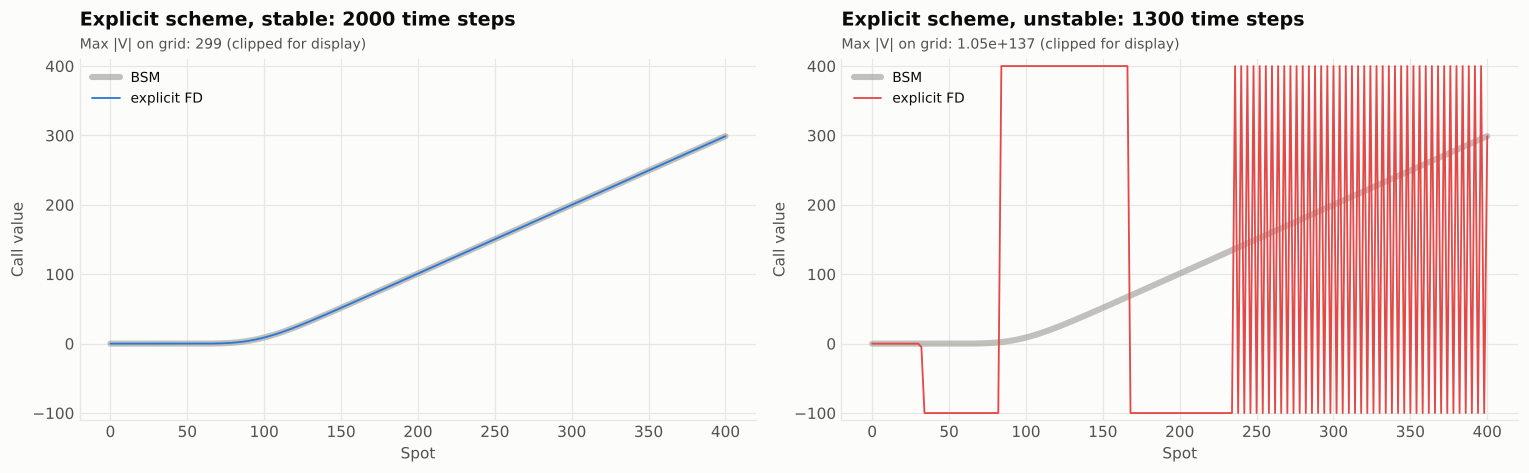

Rule of thumb: dt < 1 / (sigma^2 Ns^2) = 1/1600 here. 1500 steps technically breaks it but survives (only the
top few nodes are unstable); 1300 steps reaches values around 1e137. The bound is a cliff edge, not a suggestion.



### American put on the PDE grid


,value
American put (Crank-Nicolson + Brennan-Schwartz),7.971893
LR tree 1001 steps,7.974270
critical price today,75.000000
European,7.458941


In [11]:
def brennan_schwartz(lower, diag, upper, rhs, payoff):
    """Solve tridiagonal LCP for an American put: eliminate upwards, substitute forwards with max().
    Works because the exercise region is a contiguous block at low S. For anything fancier, PSOR."""
    m = len(diag)
    d = diag.copy(); b = rhs.copy()
    for i in range(m - 2, -1, -1):
        f = upper[i] / d[i + 1]
        d[i] -= f * lower[i + 1]
        b[i] -= f * b[i + 1]
    x = np.empty(m)
    x[0] = max(b[0] / d[0], payoff[0])
    for i in range(1, m):
        x[i] = max((b[i] - lower[i] * x[i - 1]) / d[i], payoff[i])
    return x

def pde_price(S0, K, T, r, sigma, q=0.0, kind="put", american=False, theta=0.5, Ns=300, Nt=300,
              smax_mult=4.0, rannacher=2, return_grid=False):
    Smax = smax_mult * max(S0, K)
    S = np.linspace(0, Smax, Ns + 1)
    dt = T / Nt
    payoff = np.maximum(S - K, 0) if kind == "call" else np.maximum(K - S, 0)
    V = payoff.copy()
    i = np.arange(1, Ns)
    a_, b_ = 0.5 * sigma ** 2 * i ** 2, 0.5 * (r - q) * i
    l, dg, u = a_ - b_, -2 * a_ - r, a_ + b_
    def bounds(tau):
        if kind == "call":
            return 0.0, Smax * math.exp(-q * tau) - K * math.exp(-r * tau)
        return (K if american else K * math.exp(-r * tau)), 0.0
    boundary = []
    for n in range(Nt):
        th = 1.0 if (theta == 0.5 and n < rannacher) else theta
        lo_n, hi_n = bounds((n + 1) * dt)
        rhs = V[1:-1] + (1 - th) * dt * (l * V[:-2] + dg * V[1:-1] + u * V[2:])
        rhs[0] += th * dt * l[0] * lo_n
        rhs[-1] += th * dt * u[-1] * hi_n
        if th == 0:
            Vin = rhs
            if american: Vin = np.maximum(Vin, payoff[1:-1])
        else:
            lower, diag, upper = -th * dt * l, 1 - th * dt * dg, -th * dt * u
            if american and kind == "put":
                Vin = brennan_schwartz(lower, diag, upper, rhs, payoff[1:-1])
            else:
                ab = np.zeros((3, Ns - 1)); ab[0, 1:] = upper[:-1]; ab[1] = diag; ab[2, :-1] = lower[1:]
                Vin = solve_banded((1, 1), ab, rhs)
                if american: Vin = np.maximum(Vin, payoff[1:-1])
        V = np.r_[lo_n, Vin, hi_n]
        if american and kind == "put":
            ex = (np.abs(V - payoff) < 1e-9) & (S < K) & (S > 0)
            boundary.append(S[ex].max() if ex.any() else np.nan)
    price = float(np.interp(S0, S, V))
    if return_grid:
        return price, S, V, np.array(boundary[::-1])  # boundary reversed: index 0 = today
    return price

@demo("pde")
def demo_pde():
    ex = bsm(S0, K0, T0, R0, SIG0, Q0, "put")
    rows = []
    for nm, th in [("Implicit", 1.0), ("Crank-Nicolson + Rannacher", 0.5)]:
        for N in [50, 100, 200, 400]:
            p = pde_price(S0, K0, T0, R0, SIG0, Q0, "put", theta=th, Ns=N, Nt=N)
            rows.append({"scheme": nm, "grid NS = Nt": N, "price": p, "abs error": abs(p - ex)})
    show(pd.DataFrame(rows), f"European put on PDE grids (BSM {ex:.6f})")

@demo("pde_explicit")
def demo_explicit():
    Ns = 200
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=False)
    # A call, on purpose: the unstable modes live at high S, where a put is worth zero and has nothing to amplify
    for ax, Nt, lbl in [(axes[0], 2000, "stable: 2000 time steps"), (axes[1], 1300, "unstable: 1300 time steps")]:
        _, S, V, _ = pde_price(S0, K0, T0, R0, SIG0, Q0, "call", theta=0.0, Ns=Ns, Nt=Nt, return_grid=True)
        ref = bsm(np.maximum(S, 1e-9), K0, T0, R0, SIG0, Q0, "call")
        ax.plot(S, ref, color=MUTED, lw=4, alpha=0.6, label="BSM")
        ax.plot(S, np.clip(V, -100, 400), color=PALETTE[0] if Nt == 2000 else PALETTE[7], lw=1.2, label="explicit FD")
        ax.set_ylim(-110, 410); ax.legend(loc="upper left")
        style(ax, f"Explicit scheme, {lbl}", f"Max |V| on grid: {np.abs(V).max():.3g} (clipped for display)", "Spot", "Call value")
    plt.tight_layout(); plt.show()
    print("Rule of thumb: dt < 1 / (sigma^2 Ns^2) = 1/1600 here. 1500 steps technically breaks it but survives (only the")
    print("top few nodes are unstable); 1300 steps reaches values around 1e137. The bound is a cliff edge, not a suggestion.")

@demo("psor")
def demo_psor():
    p, S, V, bnd = pde_price(S0, K0, T0, 0.05, 0.25, 0.0, "put", american=True, Ns=400, Nt=400, return_grid=True)
    show({"American put (Crank-Nicolson + Brennan-Schwartz)": p,
          "LR tree 1001 steps": binomial(S0, K0, T0, 0.05, 0.25, 0.0, 1001, "put", True, "lr"),
          "critical price today": bnd[0], "European": bsm(S0, K0, T0, 0.05, 0.25, 0.0, "put")}, "American put on the PDE grid")

for k in ["pde", "pde_explicit", "psor"]:
    DEMOS[k]()

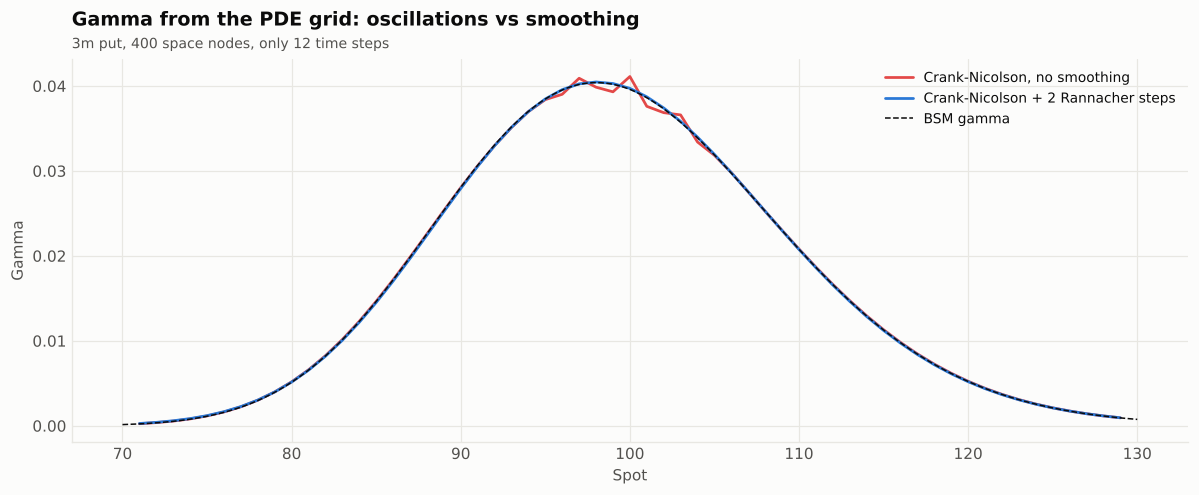

In [12]:
# Crank-Nicolson's dirty secret: big time steps + payoff kink = oscillating gamma. Rannacher fixes it in two steps.
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (rann, nm) in enumerate([(0, "Crank-Nicolson, no smoothing"), (2, "Crank-Nicolson + 2 Rannacher steps")]):
    _, S, V, _ = pde_price(100, 100, 0.25, R0, SIG0, Q0, "put", theta=0.5, Ns=400, Nt=12, rannacher=rann, return_grid=True)
    gam = np.gradient(np.gradient(V, S), S)
    m = (S > 70) & (S < 130)
    ax.plot(S[m], gam[m], color=PALETTE[[7, 0][i]], lw=1.8, label=nm)
Sg = np.linspace(70, 130, 300)
ax.plot(Sg, bsm_greeks(Sg, 100, 0.25, R0, SIG0, Q0, "put")["gamma"], color=INK, lw=1, ls="--", label="BSM gamma")
ax.legend(loc="upper right")
style(ax, "Gamma from the PDE grid: oscillations vs smoothing", "3m put, 400 space nodes, only 12 time steps", "Spot", "Gamma")
plt.tight_layout(); plt.show()

## 9. Monte Carlo

$$\hat V = e^{-rT}\frac1N\sum_{i=1}^N \text{payoff}(S^{(i)}),\qquad \text{s.e.} = \frac{\hat\sigma}{\sqrt N}$$

| Technique | Idea | Typical gain |
|---|---|---|
| Antithetic | use $Z$ and $-Z$ | 2x to 5x for monotone payoffs |
| Control variate | subtract $b(X-\mathbb E[X])$ with known $\mathbb E[X]$ (here $S_T$) | 5x to 100x |
| Sobol QMC | low-discrepancy points, randomized by scrambling | error close to $O(1/N)$ for smooth payoffs |
| Longstaff-Schwartz | regress continuation value on $\{1, x, x^2, x^3\}$ at each exercise date | early exercise inside MC |


### MC on 131,072 samples (BSM 8.827321); QMC has no honest single-run s.e., see chart


,method,price,reported s.e.,error vs BSM
0,plain,8.811228,0.037657,-0.016093
1,antithetic,8.812610,0.028775,-0.014711
2,cv,8.813964,0.016053,-0.013357
3,antithetic+cv,8.823313,0.007995,-0.004008
4,qmc,8.827234,NaN,-0.000087


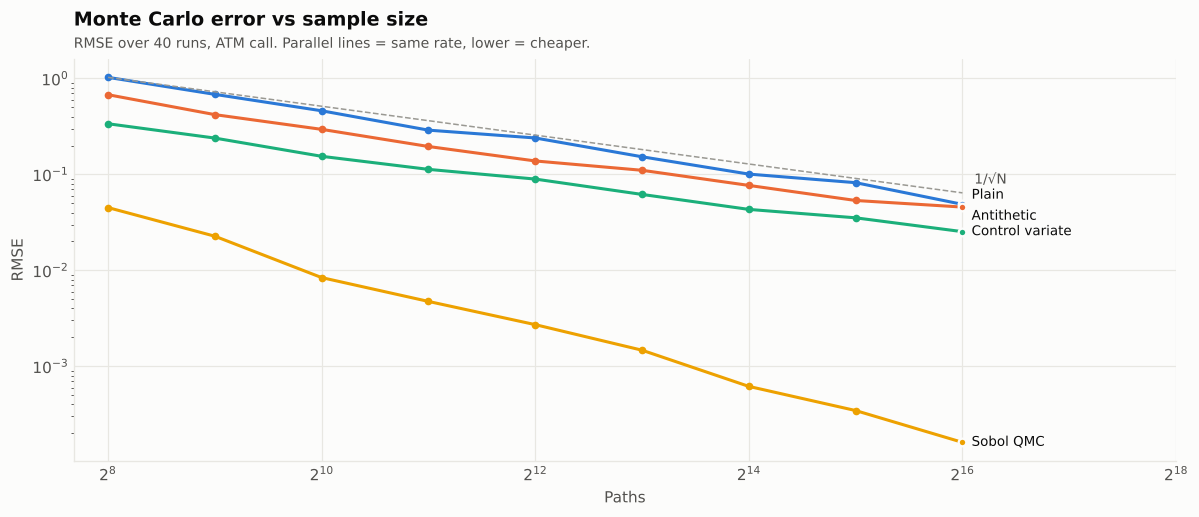

In [13]:
def mc_euro(S, K, T, r, sigma, q=0.0, n=100_000, method="plain", seed=SEED, kind="call"):
    rng = np.random.default_rng(seed)
    if method == "qmc":
        m = int(round(math.log2(n)))
        u = qmc.Sobol(d=1, scramble=True, seed=seed).random_base2(m).ravel()
        Z = norm.ppf(np.clip(u, 1e-12, 1 - 1e-12))
    elif method in ("antithetic", "antithetic+cv"):
        z = rng.standard_normal(n // 2); Z = np.r_[z, -z]
    else:
        Z = rng.standard_normal(n)
    ST = S * np.exp((r - q - 0.5 * sigma ** 2) * T + sigma * math.sqrt(T) * Z)
    pay = math.exp(-r * T) * (np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0))
    X = math.exp(-r * T) * ST                         # discounted terminal price: a martingale with known mean
    if method in ("antithetic", "antithetic+cv"):
        # average each Z/-Z pair first: the pairs are the independent samples, the halves are not
        h = len(pay) // 2
        pay, X = 0.5 * (pay[:h] + pay[h:]), 0.5 * (X[:h] + X[h:])
    if method in ("cv", "antithetic+cv"):
        b = np.cov(pay, X)[0, 1] / X.var()
        pay = pay - b * (X - S * math.exp(-q * T))
    return pay.mean(), pay.std(ddof=1) / math.sqrt(len(pay))

@demo("mc")
def demo_mc():
    ex = bsm(S0, K0, T0, R0, SIG0, Q0)
    rows = []
    for m in ["plain", "antithetic", "cv", "antithetic+cv", "qmc"]:
        v, se = mc_euro(S0, K0, T0, R0, SIG0, Q0, 2 ** 17, m)
        rows.append({"method": m, "price": v, "reported s.e.": se if m != "qmc" else np.nan, "error vs BSM": v - ex})
    show(pd.DataFrame(rows), f"MC on 131,072 samples (BSM {ex:.6f}); QMC has no honest single-run s.e., see chart")

DEMOS["mc"]()

# RMSE over 40 independent runs per sample size. The slope tells you the convergence order.
Ns_ = 2 ** np.arange(8, 17)
rmse = {}
ex = bsm(S0, K0, T0, R0, SIG0, Q0)
for m, nm in [("plain", "Plain"), ("antithetic", "Antithetic"), ("cv", "Control variate"), ("qmc", "Sobol QMC")]:
    rmse[nm] = [math.sqrt(np.mean([(mc_euro(S0, K0, T0, R0, SIG0, Q0, int(n), m, seed=s)[0] - ex) ** 2 for s in range(40)])) for n in Ns_]
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (nm, e) in enumerate(rmse.items()):
    ax.plot(Ns_, e, color=PALETTE[i], marker="o", ms=4)
ref = rmse["Plain"][0] * np.sqrt(Ns_[0] / Ns_)
ax.plot(Ns_, ref, color=MUTED, ls="--", lw=1); ax.text(Ns_[-1] * 1.08, ref[-1] * 1.25, "1/√N", color=INK2, fontsize=9)
mc_nudge = {"Plain": 6, "Antithetic": -6}
end_labels(ax, {nm: (Ns_, np.array(e), PALETTE[i], mc_nudge.get(nm, 0)) for i, (nm, e) in enumerate(rmse.items())})
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlim(Ns_[0] * 0.8, Ns_[-1] * 4)
style(ax, "Monte Carlo error vs sample size", "RMSE over 40 runs, ATM call. Parallel lines = same rate, lower = cheaper.", "Paths", "RMSE")
plt.tight_layout(); plt.show()


### Longstaff-Schwartz (low-biased by construction: a suboptimal rule can't beat the optimal one)


,value
"LSM American put (50 dates, 100k paths)",7.975647
s.e.,0.029154
LR tree (Bermudan-like 50 steps),7.968497
LR tree 1001 steps (American),7.974270


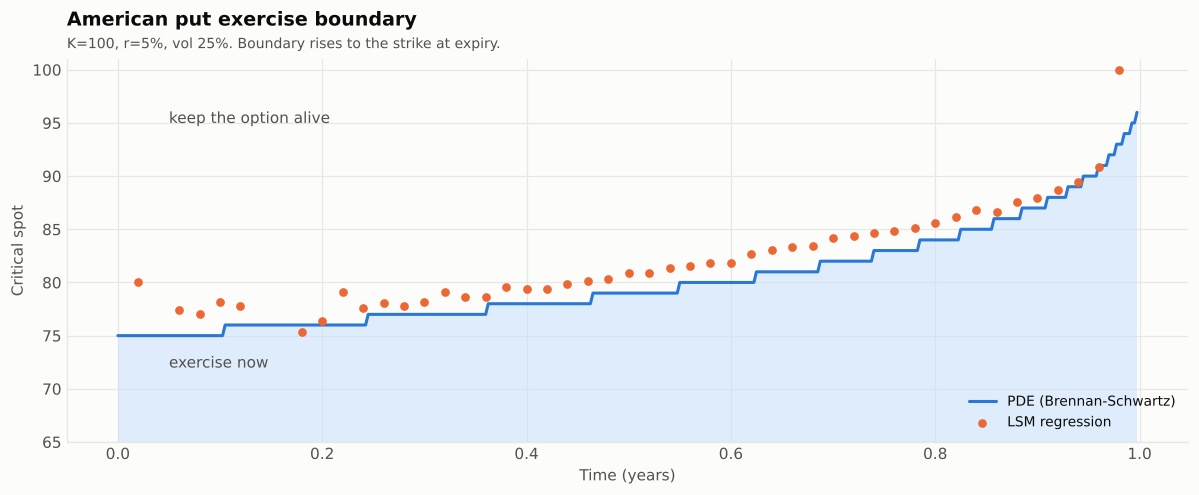

In [14]:
def lsm_put(S, K, T, r, sigma, q=0.0, steps=50, paths=100_000, seed=SEED, deg=3):
    P = gbm_paths(S, T, r, q, sigma, steps, paths, seed)
    dt = T / steps; disc = math.exp(-r * dt)
    cash = np.maximum(K - P[:, -1], 0)
    bnd = np.full(steps, np.nan); bnd[-1] = K
    sgrid = np.linspace(0.4 * K, K, 400)
    for t in range(steps - 2, -1, -1):
        cash *= disc
        St = P[:, t]
        itm = K - St > 0
        X = St[itm] / K
        coef = np.polyfit(X, cash[itm], deg)
        cont = np.polyval(coef, X)
        ex = (K - St[itm]) > cont
        idx = np.where(itm)[0][ex]
        cash[idx] = K - St[idx]
        crossing = (K - sgrid) - np.polyval(coef, sgrid / K)
        pos = np.where(crossing > 0)[0]
        bnd[t] = sgrid[pos.max()] if len(pos) else np.nan  # highest spot where exercising beats waiting
    v = disc * cash
    return v.mean(), v.std() / math.sqrt(paths), bnd

@demo("lsm")
def demo_lsm():
    v, se, _ = lsm_put(S0, K0, T0, 0.05, 0.25, 0.0)
    show({"LSM American put (50 dates, 100k paths)": v, "s.e.": se,
          "LR tree (Bermudan-like 50 steps)": binomial(S0, K0, T0, 0.05, 0.25, 0.0, 51, "put", True, "lr"),
          "LR tree 1001 steps (American)": binomial(S0, K0, T0, 0.05, 0.25, 0.0, 1001, "put", True, "lr")},
         "Longstaff-Schwartz (low-biased by construction: a suboptimal rule can't beat the optimal one)")

DEMOS["lsm"]()

p_pde, S_, V_, bnd_pde = pde_price(S0, K0, T0, 0.05, 0.25, 0.0, "put", american=True, Ns=400, Nt=400, return_grid=True)
_, _, bnd_lsm = lsm_put(S0, K0, T0, 0.05, 0.25, 0.0)
fig, ax = plt.subplots(figsize=(11, 4.6))
t_pde = np.linspace(0, T0, len(bnd_pde), endpoint=False)
ax.plot(t_pde, bnd_pde, color=PALETTE[0], label="PDE (Brennan-Schwartz)")
ax.scatter(np.linspace(0, T0, len(bnd_lsm), endpoint=False), bnd_lsm, color=PALETTE[1], s=22, zorder=3, label="LSM regression")
ax.fill_between(t_pde, 0, bnd_pde, color=SEQ[0], alpha=0.6, lw=0)
ax.text(0.05, 72, "exercise now", color=INK2, fontsize=10); ax.text(0.05, 95, "keep the option alive", color=INK2, fontsize=10)
ax.set_ylim(65, 101); ax.legend(loc="lower right")
style(ax, "American put exercise boundary", "K=100, r=5%, vol 25%. Boundary rises to the strike at expiry.", "Time (years)", "Critical spot")
plt.tight_layout(); plt.show()

## 10. Fourier methods

All three need only the characteristic function $\varphi(u)=\mathbb E[e^{iu\ln S_T}]$, so they price every affine and Levy model in this notebook.

| Method | Formula | Strengths |
|---|---|---|
| Gil-Pelaez / Lewis | $C = Se^{-qT}P_1 - Ke^{-rT}P_2$, $P_2 = \tfrac12+\tfrac1\pi\int_0^\infty \text{Re}\frac{e^{-iu\ln K}\varphi(u)}{iu}du$ | any strike, transparent |
| Carr-Madan FFT | $C(k)=\frac{e^{-\alpha k}}{\pi}\text{Re}\sum e^{-iv_jk}\psi(v_j)\eta_j$, $\psi(v)=\frac{e^{-rT}\varphi(v-(\alpha+1)i)}{\alpha^2+\alpha-v^2+i(2\alpha+1)v}$ | whole strike grid at once |
| COS | $V\approx e^{-rT}\sum_k{}' \text{Re}\left[\varphi_X\!\left(\tfrac{k\pi}{b-a}\right)e^{-ik\pi\frac{a}{b-a}}\right]V_k$ | exponential convergence, robust |

Characteristic functions implemented: BSM, Heston (Albrecher "little trap" form, no branch-cut drama), Merton, Bates, Kou, Variance Gamma, NIG.


### Three Fourier methods vs BSM closed form


,strike,Gil-Pelaez,Carr-Madan FFT,COS,max disagreement,BSM exact,Gil-Pelaez error
0,70.000000,31.262358,31.262188,31.262358,0.000170,31.262358,0.000000
1,85.000000,18.285331,18.285370,18.285331,0.000039,18.285331,0.000000
2,100.000000,8.827321,8.828002,8.827321,0.000680,8.827321,0.000000
3,115.000000,3.543316,3.543901,3.543316,0.000585,3.543316,0.000000
4,130.000000,1.219769,1.220129,1.219769,0.000360,1.219769,0.000000



### Heston, T=0.5: FFT vs the other two


,strike,Gil-Pelaez,Carr-Madan FFT,COS,max disagreement
0,70.000000,30.825765,30.825530,30.825756,0.000236
1,85.000000,17.025717,17.025712,17.025708,0.000009
2,100.000000,5.517474,5.518571,5.517465,0.001106
3,115.000000,0.452992,0.453893,0.452983,0.000910
4,130.000000,0.025727,0.025780,0.025718,0.000062



### Variance Gamma, T=0.5: COS vs the other two


,strike,Gil-Pelaez,Carr-Madan FFT,COS,max disagreement
0,70.000000,30.698608,30.698371,30.698608,0.000237
1,85.000000,16.876935,16.876948,16.876934,0.000014
2,100.000000,6.058355,6.059473,6.058354,0.001119
3,115.000000,1.216348,1.217121,1.216348,0.000773
4,130.000000,0.216360,0.216531,0.216361,0.000171


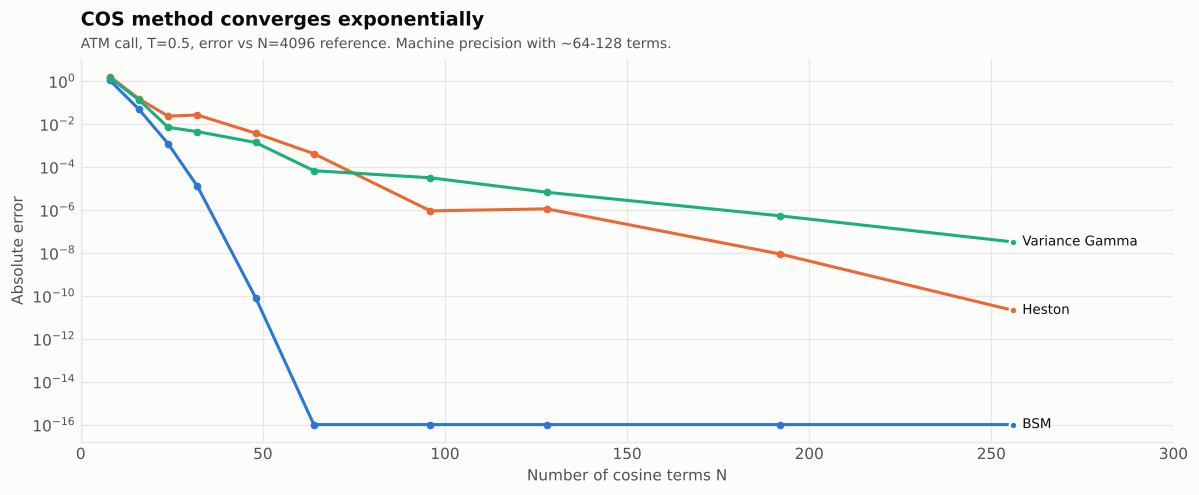

In [15]:
def cf_bsm(u, S, T, r, q, sigma):
    return np.exp(1j * u * (np.log(S) + (r - q - 0.5 * sigma ** 2) * T) - 0.5 * sigma ** 2 * u ** 2 * T)

def cf_heston(u, S, T, r, q, v0, kappa, theta, xi, rho):
    u = np.asarray(u, complex)
    a = kappa - rho * xi * 1j * u
    d = np.sqrt(a ** 2 + xi ** 2 * (1j * u + u ** 2))
    g = (a - d) / (a + d)
    e = np.exp(-d * T)
    C = kappa * theta / xi ** 2 * ((a - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    D = (a - d) / xi ** 2 * (1 - e) / (1 - g * e)
    return np.exp(1j * u * (np.log(S) + (r - q) * T) + C + D * v0)

def _jump_lognormal(u, T, lam, muJ, dJ):
    k = math.exp(muJ + 0.5 * dJ ** 2) - 1
    return np.exp(lam * T * (np.exp(1j * u * muJ - 0.5 * dJ ** 2 * u ** 2) - 1) - 1j * u * lam * k * T)

def cf_merton(u, S, T, r, q, sigma, lam, muJ, dJ):
    return cf_bsm(u, S, T, r, q, sigma) * _jump_lognormal(u, T, lam, muJ, dJ)

def cf_bates(u, S, T, r, q, v0, kappa, theta, xi, rho, lam, muJ, dJ):
    return cf_heston(u, S, T, r, q, v0, kappa, theta, xi, rho) * _jump_lognormal(u, T, lam, muJ, dJ)

def cf_kou(u, S, T, r, q, sigma, lam, p, eta1, eta2):
    zeta = p * eta1 / (eta1 - 1) + (1 - p) * eta2 / (eta2 + 1) - 1
    jump = p * eta1 / (eta1 - 1j * u) + (1 - p) * eta2 / (eta2 + 1j * u)
    return np.exp(1j * u * (np.log(S) + (r - q - 0.5 * sigma ** 2 - lam * zeta) * T)
                  - 0.5 * sigma ** 2 * u ** 2 * T + lam * T * (jump - 1))

def cf_vg(u, S, T, r, q, sigma, nu, theta):
    omega = math.log(1 - theta * nu - 0.5 * sigma ** 2 * nu) / nu
    return np.exp(1j * u * (np.log(S) + (r - q + omega) * T) - T / nu * np.log(1 - 1j * u * theta * nu + 0.5 * sigma ** 2 * nu * u ** 2))

def cf_nig(u, S, T, r, q, alpha, beta, delta):
    omega = delta * (math.sqrt(alpha ** 2 - (beta + 1) ** 2) - math.sqrt(alpha ** 2 - beta ** 2))
    return np.exp(1j * u * (np.log(S) + (r - q + omega) * T)
                  + delta * T * (math.sqrt(alpha ** 2 - beta ** 2) - np.sqrt(alpha ** 2 - (beta + 1j * u) ** 2)))

# Parameter sets used throughout. Plausible equity-index flavours, not a calibration.
P_HESTON = dict(v0=0.04, kappa=1.5, theta=0.04, xi=0.6, rho=-0.7)
P_MERTON = dict(sigma=0.15, lam=0.5, muJ=-0.10, dJ=0.15)
P_BATES = dict(v0=0.03, kappa=2.0, theta=0.035, xi=0.45, rho=-0.6, lam=0.4, muJ=-0.12, dJ=0.10)
P_KOU = dict(sigma=0.15, lam=1.0, p=0.3, eta1=10.0, eta2=5.0)
P_VG = dict(sigma=0.20, nu=0.25, theta=-0.15)
P_NIG = dict(alpha=10.0, beta=-4.0, delta=0.25)

def make_cf(model, S, T, r, q, **p):
    f = {"bsm": cf_bsm, "heston": cf_heston, "merton": cf_merton, "bates": cf_bates,
         "kou": cf_kou, "vg": cf_vg, "nig": cf_nig}[model]
    return lambda u: f(u, S, T, r, q, **p)

def _scalar_out(K_in, v):
    """Scalar strike in, scalar price out. Arrays stay arrays."""
    return float(np.asarray(v).ravel()[0]) if np.ndim(K_in) == 0 else np.asarray(v)

def price_gil_pelaez(cf, S, K, T, r, q=0.0, umax=300.0, n=1024):
    K_in, K = K, np.atleast_1d(np.asarray(K, float))
    x, w = np.polynomial.legendre.leggauss(n)
    u = 0.5 * umax * (x + 1); w = 0.5 * umax * w
    e = np.exp(-1j * np.outer(np.log(K), u))
    fwd = S * math.exp((r - q) * T)
    P2 = 0.5 + np.sum(w * np.real(e * cf(u) / (1j * u)), axis=1) / math.pi
    P1 = 0.5 + np.sum(w * np.real(e * cf(u - 1j) / (1j * u * fwd)), axis=1) / math.pi
    return _scalar_out(K_in, S * math.exp(-q * T) * P1 - K * math.exp(-r * T) * P2)

def price_fft(cf, S, K, T, r, alpha=1.5, N=4096, eta=0.25):
    lam = 2 * math.pi / (N * eta); b = N * lam / 2
    j = np.arange(N); v = eta * j; k = -b + lam * j
    psi = math.exp(-r * T) * cf(v - (alpha + 1) * 1j) / (alpha ** 2 + alpha - v ** 2 + 1j * (2 * alpha + 1) * v)
    simpson = (3 + (-1) ** (j + 1)) / 3; simpson[0] = 1 / 3
    y = np.fft.fft(np.exp(1j * b * v) * psi * eta * simpson).real
    calls = np.exp(-alpha * k) / math.pi * y
    return _scalar_out(K, np.interp(np.log(np.atleast_1d(K)), k, calls))

def price_cos(cf, S, K, T, r, q=0.0, N=256, L=12.0):
    """COS method (Fang-Oosterlee) for calls, priced via puts + parity: puts have bounded payoffs, so the
    truncation error stays polite. Vectorized over strikes."""
    K_in, K = K, np.atleast_1d(np.asarray(K, float))
    lnS = math.log(S)
    phiX = lambda u: cf(u) * np.exp(-1j * np.asarray(u) * lnS)   # CF of ln(S_T/S)
    h = 1e-4
    lp, lm = np.log(phiX(np.array([h]))), np.log(phiX(np.array([-h])))
    c1 = float(((lp - lm) / (2 * h)).imag[0])
    c2 = float(-((lp + lm) / h ** 2).real[0])
    a, b = c1 - L * math.sqrt(abs(c2)), c1 + L * math.sqrt(abs(c2))
    kk = np.arange(N); w = kk * math.pi / (b - a)
    F = np.real(phiX(w) * np.exp(-1j * w * a)); F[0] *= 0.5
    x = np.log(S / K)[:, None]                       # one row per strike
    A = x + a; c_ = A; d_ = np.minimum(0.0, x + b)
    valid = c_ < d_
    wA_d, wA_c = w * (d_ - A), w * (c_ - A)
    chi = (np.cos(wA_d) * np.exp(d_) - np.cos(wA_c) * np.exp(c_) + w * np.sin(wA_d) * np.exp(d_) - w * np.sin(wA_c) * np.exp(c_)) / (1 + w ** 2)
    with np.errstate(divide="ignore", invalid="ignore"):
        psi_ = np.where(kk == 0, d_ - c_, (np.sin(wA_d) - np.sin(wA_c)) / np.where(w == 0, 1, w))
    Vk = 2 / (b - a) * K[:, None] * (psi_ - chi) * valid
    put = math.exp(-r * T) * (Vk * F).sum(axis=1)
    return _scalar_out(K_in, put + S * math.exp(-q * T) - K * math.exp(-r * T))

def _three_way(model, params, Ks, T=0.5, title=""):
    cf = make_cf(model, S0, T, R0, Q0, **params)
    df = pd.DataFrame({"strike": Ks, "Gil-Pelaez": price_gil_pelaez(cf, S0, Ks, T, R0, Q0),
                       "Carr-Madan FFT": price_fft(cf, S0, Ks, T, R0), "COS": price_cos(cf, S0, Ks, T, R0, Q0)})
    df["max disagreement"] = df[["Gil-Pelaez", "Carr-Madan FFT", "COS"]].max(axis=1) - df[["Gil-Pelaez", "Carr-Madan FFT", "COS"]].min(axis=1)
    return df

KS = np.array([70, 85, 100, 115, 130.0])

@demo("cf_integration")
def demo_gp():
    df = _three_way("bsm", {"sigma": SIG0}, KS, T0)
    df["BSM exact"] = bsm(S0, KS, T0, R0, SIG0, Q0)
    df["Gil-Pelaez error"] = df["Gil-Pelaez"] - df["BSM exact"]
    show(df, "Three Fourier methods vs BSM closed form")

@demo("fft")
def demo_fft():
    show(_three_way("heston", P_HESTON, KS), "Heston, T=0.5: FFT vs the other two")

@demo("cos")
def demo_cos():
    show(_three_way("vg", P_VG, KS), "Variance Gamma, T=0.5: COS vs the other two")

for k in ["cf_integration", "fft", "cos"]:
    DEMOS[k]()

# COS convergence: error halves... no, it collapses exponentially. That is the whole selling point.
Ncos = np.array([8, 16, 24, 32, 48, 64, 96, 128, 192, 256])
fig, ax = plt.subplots(figsize=(11, 4.6))
series = {}
for i, (nm, model, p) in enumerate([("BSM", "bsm", {"sigma": SIG0}), ("Heston", "heston", P_HESTON), ("Variance Gamma", "vg", P_VG)]):
    cf = make_cf(model, S0, 0.5, R0, Q0, **p)
    ref = price_cos(cf, S0, 100.0, 0.5, R0, Q0, N=4096)
    e = np.array([abs(price_cos(cf, S0, 100.0, 0.5, R0, Q0, N=int(n)) - ref) for n in Ncos])
    e = np.maximum(e, 1e-16)
    ax.plot(Ncos, e, color=PALETTE[i], marker="o", ms=4); series[nm] = (Ncos, e, PALETTE[i])
end_labels(ax, series)
ax.set_yscale("log"); ax.set_xlim(0, 300)
style(ax, "COS method converges exponentially", "ATM call, T=0.5, error vs N=4096 reference. Machine precision with ~64-128 terms.",
      "Number of cosine terms N", "Absolute error")
plt.tight_layout(); plt.show()

## 11. Stochastic volatility

**Heston:** $dS = (r-q)S\,dt + \sqrt v S\,dW_1$, $dv = \kappa(\theta - v)dt + \xi\sqrt v\,dW_2$, $d\langle W_1,W_2\rangle=\rho\,dt$.

| Parameter | Drives |
|---|---|
| $v_0$ | short-dated ATM level |
| $\theta$ | long-dated ATM level |
| $\kappa$ | how fast short becomes long (term structure) |
| $\rho$ | skew (negative for equities: spot down, vol up) |
| $\xi$ | smile curvature (vol of vol) |

Feller condition $2\kappa\theta>\xi^2$ keeps $v>0$; real calibrations violate it all the time, which matters only for simulation.

**SABR:** $dF = \alpha F^\beta dW_1$, $d\alpha = \nu\alpha\,dW_2$. Hagan's expansion gives the implied vol directly:

$$\sigma_B(K)\approx\frac{\alpha}{(FK)^{\frac{1-\beta}{2}}\left[1+\frac{(1-\beta)^2}{24}\ln^2\frac FK+\dots\right]}\cdot\frac{z}{x(z)}\cdot\left[1+\left(\frac{(1-\beta)^2\alpha^2}{24(FK)^{1-\beta}}+\frac{\rho\beta\nu\alpha}{4(FK)^{\frac{1-\beta}{2}}}+\frac{2-3\rho^2}{24}\nu^2\right)T\right]$$

In [16]:
def heston_price(S, K, T, r, q=0.0, **p):
    return price_cos(make_cf("heston", S, T, r, q, **p), S, K, T, r, q)

def heston_iv(S, K, T, r, q=0.0, **p):
    return implied_vol(heston_price(S, K, T, r, q, **p), S, K, T, r, q)

def heston_mc(S, K, T, r, q, v0, kappa, theta, xi, rho, steps=200, paths=100_000, seed=SEED):
    """Full-truncation Euler on log S: the least-bad simple Heston scheme (Lord, Koekkoek, van Dijk 2010)."""
    rng = np.random.default_rng(seed)
    dt = T / steps
    x = np.full(paths, math.log(S)); v = np.full(paths, v0)
    for _ in range(steps):
        z1 = rng.standard_normal(paths); z2 = rho * z1 + math.sqrt(1 - rho ** 2) * rng.standard_normal(paths)
        vp = np.maximum(v, 0)
        x += (r - q - 0.5 * vp) * dt + np.sqrt(vp * dt) * z1
        v += kappa * (theta - vp) * dt + xi * np.sqrt(vp * dt) * z2
    ST = np.exp(x)
    K = np.atleast_1d(K)
    return math.exp(-r * T) * np.maximum(ST[:, None] - K[None, :], 0).mean(axis=0)

@demo("heston")
def demo_heston():
    T = 0.5
    df = pd.DataFrame({"strike": KS, "COS": heston_price(S0, KS, T, R0, Q0, **P_HESTON),
                       "MC full truncation (200 steps, 100k)": heston_mc(S0, KS, T, R0, Q0, **P_HESTON)})
    df["implied vol"] = implied_vol(df["COS"].values, S0, KS, T, R0, Q0)
    show(df, "Heston (v0 4%, kappa 1.5, theta 4%, xi 0.6, rho -0.7), T=0.5")
    print(f"Feller 2 kappa theta - xi^2 = {2 * 1.5 * 0.04 - 0.36:+.3f} (negative: variance hits zero, MC must truncate)")
    print("MC sits ~1% low at the money: that is Euler discretization bias, not noise. Andersen's QE scheme (2008) is the fix.")

def sabr_vol(F, K, T, alpha, beta, rho, nu):
    K = np.asarray(K, float)
    logFK = np.log(F / K)
    FK = (F * K) ** ((1 - beta) / 2)
    z = nu / alpha * FK * logFK
    xz = np.log((np.sqrt(1 - 2 * rho * z + z * z) + z - rho) / (1 - rho))
    zx = np.where(np.abs(z) < 1e-10, 1.0, z / np.where(np.abs(xz) < 1e-14, 1e-14, xz))
    denom = FK * (1 + (1 - beta) ** 2 / 24 * logFK ** 2 + (1 - beta) ** 4 / 1920 * logFK ** 4)
    corr = 1 + ((1 - beta) ** 2 / 24 * alpha ** 2 / FK ** 2 + rho * beta * nu * alpha / (4 * FK) + (2 - 3 * rho ** 2) / 24 * nu ** 2) * T
    return _ret(alpha / denom * zx * corr)

def sabr_mc_beta1(F, K, T, alpha, rho, nu, steps=250, paths=200_000, seed=SEED):
    """beta = 1: both F and alpha are lognormal, so log-Euler is almost exact. Good referee for Hagan."""
    rng = np.random.default_rng(seed)
    dt = T / steps
    lnF = np.full(paths, math.log(F)); a = np.full(paths, alpha)
    for _ in range(steps):
        z1 = rng.standard_normal(paths); z2 = rho * z1 + math.sqrt(1 - rho ** 2) * rng.standard_normal(paths)
        lnF += -0.5 * a * a * dt + a * math.sqrt(dt) * z1
        a *= np.exp(-0.5 * nu * nu * dt + nu * math.sqrt(dt) * z2)
    FT = np.exp(lnF)
    K = np.atleast_1d(K)
    return np.maximum(FT[:, None] - K[None, :], 0).mean(axis=0)

@demo("sabr")
def demo_sabr():
    F, T, a, rho, nu = 100.0, 1.0, 0.20, -0.5, 0.8
    Ks = np.array([70, 85, 100, 115, 130.0])
    mc = sabr_mc_beta1(F, Ks, T, a, rho, nu)
    df = pd.DataFrame({"strike": Ks, "Hagan implied vol": sabr_vol(F, Ks, T, a, 1.0, rho, nu),
                       "MC implied vol": implied_vol(mc, F, Ks, T, 0.0, 0.0)})
    df["Hagan error (vol pts)"] = (df["Hagan implied vol"] - df["MC implied vol"]) * 100
    show(df, "SABR beta=1, alpha 20%, rho -0.5, nu 0.8, T=1: Hagan's formula vs Monte Carlo")
    print("Hagan is an expansion in T * nu^2: fine for short expiries, drifts for long ones and big vol of vol.")

for k in ["heston", "sabr"]:
    DEMOS[k]()


### Heston (v0 4%, kappa 1.5, theta 4%, xi 0.6, rho -0.7), T=0.5


,strike,COS,"MC full truncation (200 steps, 100k)",implied vol
0,70.000000,30.825756,30.760203,0.296873
1,85.000000,17.025708,16.965158,0.240749
2,100.000000,5.517465,5.473467,0.179392
3,115.000000,0.452983,0.447212,0.138867
4,130.000000,0.025718,0.024345,0.144750


Feller 2 kappa theta - xi^2 = -0.240 (negative: variance hits zero, MC must truncate)
MC sits ~1% low at the money: that is Euler discretization bias, not noise. Andersen's QE scheme (2008) is the fix.



### SABR beta=1, alpha 20%, rho -0.5, nu 0.8, T=1: Hagan's formula vs Monte Carlo


,strike,Hagan implied vol,MC implied vol,Hagan error (vol pts)
0,70.000000,0.291902,0.279724,1.217812
1,85.000000,0.241255,0.234617,0.663793
2,100.000000,0.202667,0.200403,0.226388
3,115.000000,0.183501,0.183637,-0.013519
4,130.000000,0.185358,0.185485,-0.012697


Hagan is an expansion in T * nu^2: fine for short expiries, drifts for long ones and big vol of vol.


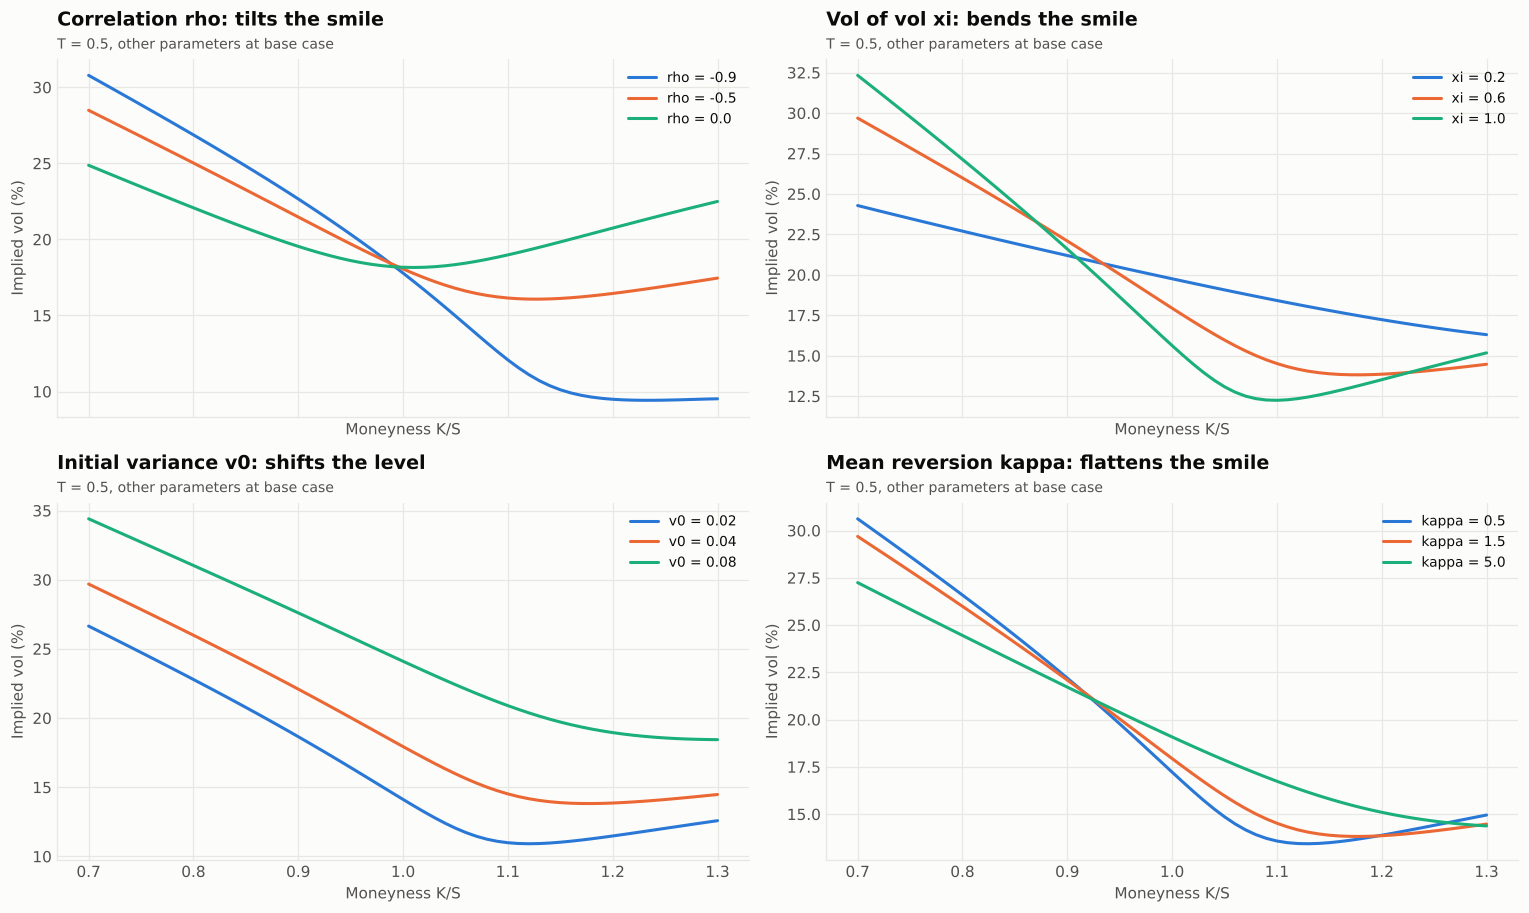

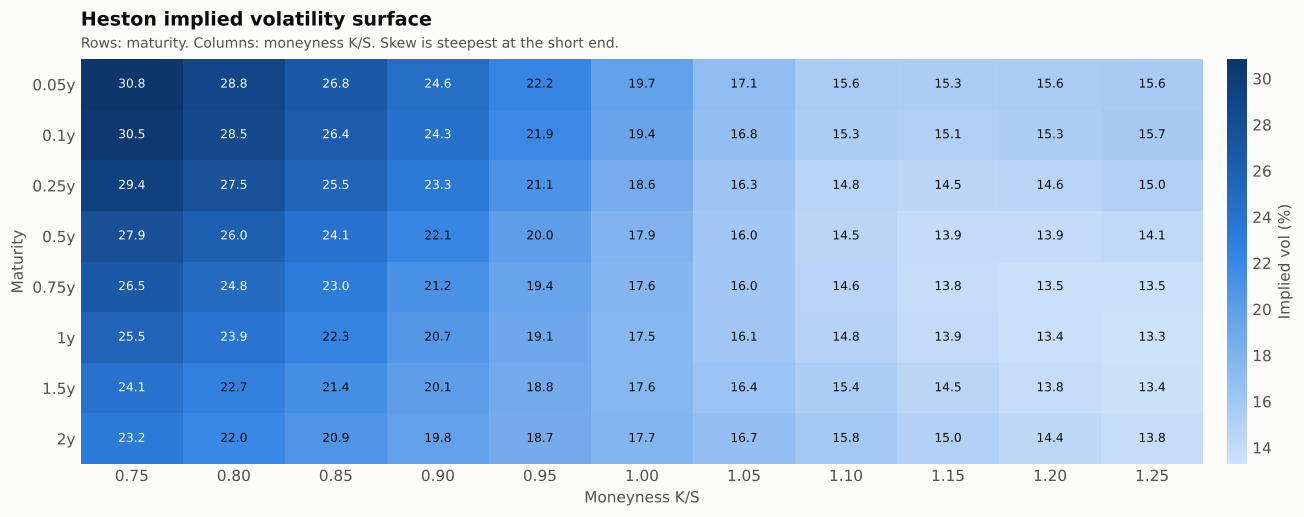

In [17]:
# What each Heston parameter actually does: vary one, freeze the rest. Three lines per panel, colour = value order.
mny = np.linspace(0.7, 1.3, 61); Ks_ = S0 * mny; T = 0.5
tweaks = [("rho", [-0.9, -0.5, 0.0], "Correlation rho: tilts the smile"),
          ("xi", [0.2, 0.6, 1.0], "Vol of vol xi: bends the smile"),
          ("v0", [0.02, 0.04, 0.08], "Initial variance v0: shifts the level"),
          ("kappa", [0.5, 1.5, 5.0], "Mean reversion kappa: flattens the smile")]
fig, axes = plt.subplots(2, 2, figsize=(14, 8.4), sharex=True)
for ax, (pn, vals, title) in zip(axes.ravel(), tweaks):
    for i, v in enumerate(vals):
        p = dict(P_HESTON); p[pn] = v
        ax.plot(mny, heston_iv(S0, Ks_, T, R0, Q0, **p) * 100, color=PALETTE[i], label=f"{pn} = {v}")
    ax.legend(loc="upper right")
    style(ax, title, "T = 0.5, other parameters at base case", "Moneyness K/S", "Implied vol (%)")
plt.tight_layout(); plt.show()

# Heston implied vol surface as a heatmap: skew across strikes, term structure down the rows
Tsurf = np.array([0.05, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0])
msurf = np.array([0.75, 0.8, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.15, 1.2, 1.25])
surf = np.array([heston_iv(S0, S0 * msurf, t, R0, Q0, **P_HESTON) for t in Tsurf]) * 100
fig, ax = plt.subplots(figsize=(12, 4.8))
heatmap(ax, surf, [f"{m:.2f}" for m in msurf], [f"{t:g}y" for t in Tsurf], fmt="{:.1f}", cbar="Implied vol (%)")
style(ax, "Heston implied volatility surface", "Rows: maturity. Columns: moneyness K/S. Skew is steepest at the short end.",
      "Moneyness K/S", "Maturity")
plt.tight_layout(); plt.show()

## 12. Jump models

| Model | Jump structure | Pricing here |
|---|---|---|
| Merton | lognormal jumps, Poisson arrivals | closed-form Poisson series, cross-checked with COS |
| Kou | double-exponential jump sizes | COS, checked by Monte Carlo |
| Bates | Heston + Merton jumps | COS |
| Variance Gamma | Brownian motion on a gamma clock (pure jump) | COS |
| NIG | inverse-Gaussian clock (pure jump) | COS |

Merton series: $C=\sum_{n\ge0}\frac{e^{-\lambda'T}(\lambda'T)^n}{n!}C_{BSM}(\sigma_n, r_n)$ with $\lambda'=\lambda(1+k)$, $\sigma_n^2=\sigma^2+n\delta^2/T$, $r_n=r-\lambda k+\frac{n\ln(1+k)}{T}$.

**The structural problem:** jumps are i.i.d. over time, so their skew contribution decays roughly like $1/T$. Great at the short end, useless at the long end. Stochastic vol is the reverse. Hence Bates, and hence the smile chart below.


### Merton jump-diffusion (0.5 jumps/year, mean jump -10%, jump vol 15%)


,strike,Poisson series,COS,difference,implied vol
0,70.000000,30.661100,30.661100,0.000000,0.255743
1,85.000000,16.629408,16.629408,0.000000,0.213198
2,100.000000,5.641873,5.641873,0.000000,0.183869
3,115.000000,1.003883,1.003883,0.000000,0.175474
4,130.000000,0.124402,0.124402,0.000000,0.179290



### Kou double-exponential (30% up-jumps of mean 10%, 70% down-jumps of mean 20%)


,strike,COS,MC (1M),MC s.e.,implied vol
0,70.000000,31.291732,31.293656,0.016135,0.365459
1,85.000000,17.889295,17.892635,0.013991,0.292129
2,100.000000,7.057561,7.063336,0.010391,0.234816
3,115.000000,1.779899,1.780017,0.006176,0.215923
4,130.000000,0.436247,0.434103,0.003680,0.225670



### Bates SVJ, T=0.5


,strike,COS,Gil-Pelaez,implied vol
0,70.000000,30.725613,30.725614,0.274509
1,85.000000,16.939845,16.939846,0.235087
2,100.000000,5.886817,5.886817,0.192684
3,115.000000,0.709215,0.709215,0.157352
4,130.000000,0.041709,0.041709,0.153538



### Variance Gamma (sigma 20%, nu 0.25, theta -0.15)


,strike,COS,implied vol
0,70.000000,30.698608,0.267255
1,85.000000,16.876934,0.230845
2,100.000000,6.058354,0.198857
3,115.000000,1.216348,0.187336
4,130.000000,0.216361,0.196803



### Normal Inverse Gaussian (alpha 10, beta -4, delta 0.25)


,strike,COS,implied vol
0,70.000000,30.658372,0.254820
1,85.000000,16.507253,0.203762
2,100.000000,5.026131,0.161707
3,115.000000,0.643844,0.152952
4,130.000000,0.081425,0.168141


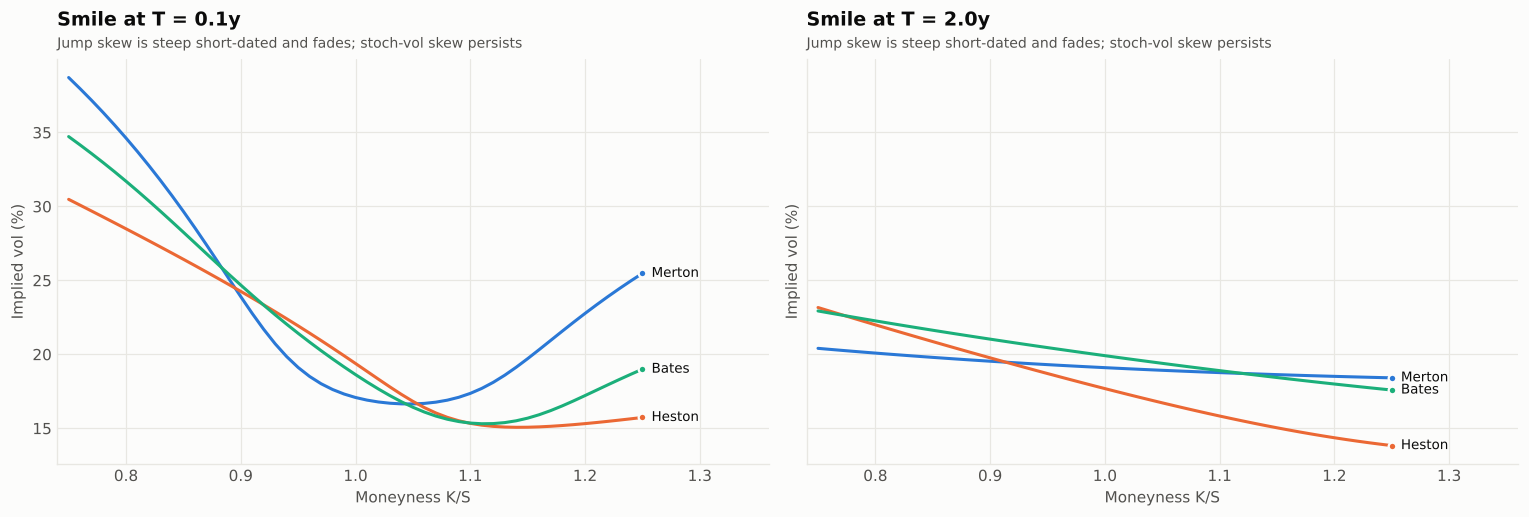

In [18]:
def merton_series(S, K, T, r, sigma, lam, muJ, dJ, q=0.0, nmax=60):
    k = math.exp(muJ + 0.5 * dJ ** 2) - 1
    lp = lam * (1 + k)
    tot = 0.0
    for n in range(nmax):
        w = math.exp(-lp * T + n * math.log(lp * T) - math.lgamma(n + 1))
        sn = math.sqrt(sigma ** 2 + n * dJ ** 2 / T)
        rn = r - lam * k + n * math.log(1 + k) / T
        tot = tot + w * bsm(S, K, T, rn, sn, q)
    return tot

def cf_price(model, params, K, T, S=S0, r=R0, q=Q0):
    return price_cos(make_cf(model, S, T, r, q, **params), S, K, T, r, q)

def cf_iv(model, params, K, T, S=S0, r=R0, q=Q0):
    return implied_vol(cf_price(model, params, K, T, S, r, q), S, K, T, r, q)

@demo("merton")
def demo_merton():
    T = 0.5
    df = pd.DataFrame({"strike": KS, "Poisson series": merton_series(S0, KS, T, R0, q=Q0, **P_MERTON),
                       "COS": cf_price("merton", P_MERTON, KS, T)})
    df["difference"] = df["Poisson series"] - df["COS"]
    df["implied vol"] = implied_vol(df["COS"].values, S0, KS, T, R0, Q0)
    show(df, "Merton jump-diffusion (0.5 jumps/year, mean jump -10%, jump vol 15%)")

@demo("kou")
def demo_kou():
    T, n = 0.5, 1_000_000
    p = P_KOU
    rng = np.random.default_rng(SEED)
    zeta = p["p"] * p["eta1"] / (p["eta1"] - 1) + (1 - p["p"]) * p["eta2"] / (p["eta2"] + 1) - 1
    N = rng.poisson(p["lam"] * T, n)
    # sum of N double-exponential jumps: draw up to max(N) jumps, mask the extras (vectorized laziness)
    J = np.zeros(n)
    for j in range(N.max()):
        up = rng.random(n) < p["p"]
        size = np.where(up, rng.exponential(1 / p["eta1"], n), -rng.exponential(1 / p["eta2"], n))
        J += np.where(N > j, size, 0.0)
    lnST = math.log(S0) + (R0 - Q0 - 0.5 * p["sigma"] ** 2 - p["lam"] * zeta) * T + p["sigma"] * math.sqrt(T) * rng.standard_normal(n) + J
    pay = math.exp(-R0 * T) * np.maximum(np.exp(lnST)[:, None] - KS[None, :], 0)
    df = pd.DataFrame({"strike": KS, "COS": cf_price("kou", P_KOU, KS, T), "MC (1M)": pay.mean(axis=0),
                       "MC s.e.": pay.std(axis=0) / math.sqrt(n)})
    df["implied vol"] = implied_vol(df["COS"].values, S0, KS, T, R0, Q0)
    show(df, "Kou double-exponential (30% up-jumps of mean 10%, 70% down-jumps of mean 20%)")

@demo("bates")
def demo_bates():
    show(pd.DataFrame({"strike": KS, "COS": cf_price("bates", P_BATES, KS, 0.5),
                       "Gil-Pelaez": price_gil_pelaez(make_cf("bates", S0, 0.5, R0, Q0, **P_BATES), S0, KS, 0.5, R0, Q0),
                       "implied vol": cf_iv("bates", P_BATES, KS, 0.5)}), "Bates SVJ, T=0.5")

@demo("vg")
def demo_vg():
    show(pd.DataFrame({"strike": KS, "COS": cf_price("vg", P_VG, KS, 0.5), "implied vol": cf_iv("vg", P_VG, KS, 0.5)}),
         "Variance Gamma (sigma 20%, nu 0.25, theta -0.15)")

@demo("nig")
def demo_nig():
    show(pd.DataFrame({"strike": KS, "COS": cf_price("nig", P_NIG, KS, 0.5), "implied vol": cf_iv("nig", P_NIG, KS, 0.5)}),
         "Normal Inverse Gaussian (alpha 10, beta -4, delta 0.25)")

for k in ["merton", "kou", "bates", "vg", "nig"]:
    DEMOS[k]()

# The short-end / long-end story in one picture: jumps own short maturities, stoch vol owns long ones, Bates owns both.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
mny = np.linspace(0.75, 1.25, 51)
for ax, T in zip(axes, [0.1, 2.0]):
    ser = {}
    for i, (nm, model, p) in enumerate([("Merton", "merton", P_MERTON), ("Heston", "heston", P_HESTON), ("Bates", "bates", P_BATES)]):
        iv = cf_iv(model, p, S0 * mny, T) * 100
        ax.plot(mny, iv, color=PALETTE[i]); ser[nm] = (mny, iv, PALETTE[i])
    end_labels(ax, ser)
    ax.set_xlim(0.74, 1.36)
    style(ax, f"Smile at T = {T}y", "Jump skew is steep short-dated and fades; stoch-vol skew persists",
          "Moneyness K/S", "Implied vol (%)")
plt.tight_layout(); plt.show()

## 13. Local volatility

**CEV:** $dS=(r-q)S\,dt+\delta S^\beta dW$. Closed form via the noncentral $\chi^2$ distribution (Schroder 1989):
$C = Se^{-qT}[1-\chi^2(a;\,b+2,\,c)] - Ke^{-rT}\chi^2(c;\,b,\,a)$.

**SSVI (Gatheral-Jacquier):** total implied variance $w(k,T)=\frac{\theta_T}{2}\left(1+\rho\varphi k+\sqrt{(\varphi k+\rho)^2+1-\rho^2}\right)$ with $\varphi(\theta)=\eta\,\theta^{-\gamma}(1+\theta)^{\gamma-1}$. Free of calendar and butterfly arbitrage when $\eta(1+|\rho|)\le2$.

**Dupire in implied-variance form (Gatheral):**
$$\sigma_{loc}^2(k,T)=\frac{\partial_T w}{1-\frac kw\partial_kw+\frac14\left(-\frac14-\frac1w+\frac{k^2}{w^2}\right)(\partial_kw)^2+\frac12\partial_{kk}w}$$

The test that matters: simulate the local vol diffusion and check it reprices the vanillas it was built from.


### CEV beta = 0.5 (square-root model)


,strike,closed form (ncx2),"MC Euler antithetic (200k, 500 steps)",MC s.e.,implied vol
0,70.000000,30.580909,30.576185,0.002945,0.218402
1,85.000000,16.564749,16.557372,0.008068,0.208276
2,100.000000,6.091287,6.074692,0.014348,0.200042
3,115.000000,1.325186,1.317070,0.008724,0.193136
4,130.000000,0.162201,0.157863,0.002912,0.187213



### Dupire local vol built from SSVI, then simulated: does it give the surface back?


,log-moneyness,SSVI target vol,local vol MC implied vol,"local vol at (k, 1y)",repricing error (vol pts)
0,-0.300000,0.264517,0.263446,0.311029,-0.107181
1,-0.200000,0.234850,0.234354,0.263260,-0.049610
2,-0.100000,0.202224,0.202192,0.205445,-0.003204
3,0.000000,0.168120,0.168345,0.141585,0.022512
4,0.100000,0.143744,0.144033,0.107718,0.028849
5,0.200000,0.141806,0.141869,0.123042,0.006241


Rule of thumb checked: near ATM, local-vol skew is about twice the implied-vol skew.


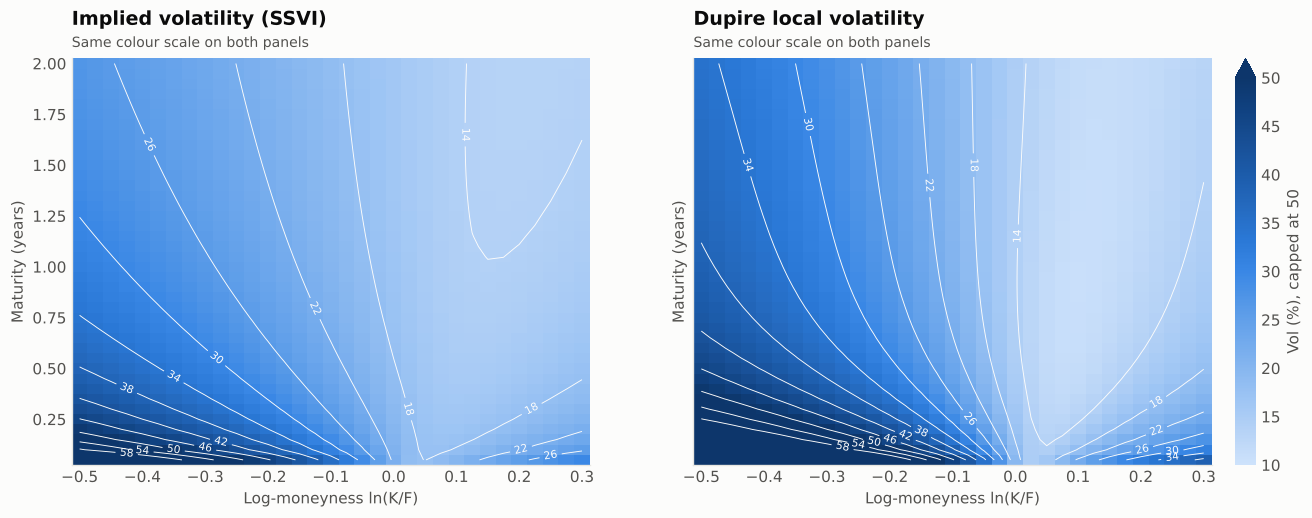

In [19]:
def cev_call(S, K, T, r, delta, beta, q=0.0):
    K = np.atleast_1d(np.asarray(K, float))
    g = r - q
    v = delta ** 2 * T if abs(g) < 1e-12 else delta ** 2 / (2 * g * (beta - 1)) * (math.exp(2 * g * (beta - 1) * T) - 1)
    a = (K * math.exp(-g * T)) ** (2 * (1 - beta)) / ((1 - beta) ** 2 * v)
    b = 1 / (1 - beta)
    c = S ** (2 * (1 - beta)) / ((1 - beta) ** 2 * v)
    return _ret(S * math.exp(-q * T) * (1 - ncx2.cdf(a, b + 2, c)) - K * math.exp(-r * T) * ncx2.cdf(c, b, a))

@demo("cev")
def demo_cev():
    beta, T = 0.5, 0.5
    delta = 0.2 * S0 ** (1 - beta)                   # ~20% ATM vol
    rng = np.random.default_rng(SEED)
    n, steps = 200_000, 500; dt = T / steps
    S = np.full(n, S0)
    for _ in range(steps):
        z = rng.standard_normal(n // 2); z = np.r_[z, -z]
        S = np.maximum(S + (R0 - Q0) * S * dt + delta * np.maximum(S, 0) ** beta * math.sqrt(dt) * z, 0)  # absorb at zero
    pay = math.exp(-R0 * T) * np.maximum(S[:, None] - KS[None, :], 0)
    pair = 0.5 * (pay[: n // 2] + pay[n // 2:])
    cf = cev_call(S0, KS, T, R0, delta, beta, Q0)
    show(pd.DataFrame({"strike": KS, "closed form (ncx2)": cf, "MC Euler antithetic (200k, 500 steps)": pay.mean(axis=0),
                       "MC s.e.": pair.std(axis=0) / math.sqrt(n // 2),
                       "implied vol": implied_vol(cf, S0, KS, T, R0, Q0)}), "CEV beta = 0.5 (square-root model)")

# --------------------------------------------- SSVI surface -> Dupire local vol -> MC repricing check
SSVI = dict(rho=-0.55, eta=1.2, gamma=0.5)
def atm_var(T):
    s = 0.16 + 0.06 * np.exp(-2 * np.asarray(T))     # downward-sloping ATM term structure, calendar-arbitrage free
    return s * s * T

def ssvi_w(k, T, rho=SSVI["rho"], eta=SSVI["eta"], gamma=SSVI["gamma"]):
    th = atm_var(T)
    ph = eta / (th ** gamma * (1 + th) ** (1 - gamma))
    return th / 2 * (1 + rho * ph * k + np.sqrt((ph * k + rho) ** 2 + 1 - rho ** 2))

def ssvi_iv(k, T):
    return np.sqrt(ssvi_w(k, T) / T)

def dupire_local_vol(k, T, hk=1e-3, hT=1e-4):
    w = ssvi_w(k, T)
    wk = (ssvi_w(k + hk, T) - ssvi_w(k - hk, T)) / (2 * hk)
    wkk = (ssvi_w(k + hk, T) - 2 * w + ssvi_w(k - hk, T)) / hk ** 2
    wT = (ssvi_w(k, T + hT) - ssvi_w(k, T - hT)) / (2 * hT)
    den = 1 - k / w * wk + 0.25 * (-0.25 - 1 / w + k * k / (w * w)) * wk ** 2 + 0.5 * wkk
    return np.sqrt(np.maximum(wT / den, 1e-8))

def local_vol_mc(T=1.0, steps=250, paths=200_000, seed=SEED):
    """r = q = 0, so F = S and k = ln(S/S0). Local vol pre-tabulated per time step, interpolated in k."""
    rng = np.random.default_rng(seed)
    dt = T / steps
    kgrid = np.linspace(-2.5, 1.5, 801)
    X = np.zeros(paths)
    for i in range(steps):
        t = max((i + 0.5) * dt, 1e-3)
        lv = np.interp(X, kgrid, dupire_local_vol(kgrid, t))
        z = rng.standard_normal(paths // 2); z = np.r_[z, -z]
        X += -0.5 * lv * lv * dt + lv * math.sqrt(dt) * z
    return 100 * np.exp(X)

@demo("localvol")
def demo_localvol():
    ST = local_vol_mc()
    kk = np.array([-0.3, -0.2, -0.1, 0.0, 0.1, 0.2])
    Ks = 100 * np.exp(kk)
    mc = np.maximum(ST[:, None] - Ks[None, :], 0).mean(axis=0)
    df = pd.DataFrame({"log-moneyness": kk, "SSVI target vol": ssvi_iv(kk, 1.0),
                       "local vol MC implied vol": implied_vol(mc, 100, Ks, 1.0, 0.0, 0.0),
                       "local vol at (k, 1y)": dupire_local_vol(kk, 1.0)})
    df["repricing error (vol pts)"] = (df["local vol MC implied vol"] - df["SSVI target vol"]) * 100
    show(df, "Dupire local vol built from SSVI, then simulated: does it give the surface back?")
    print("Rule of thumb checked: near ATM, local-vol skew is about twice the implied-vol skew.")

for k in ["cev", "localvol"]:
    DEMOS[k]()

kg = np.linspace(-0.5, 0.3, 33); Tg = np.linspace(0.05, 2.0, 40)
KK, TT = np.meshgrid(kg, Tg)
IV, LV = ssvi_iv(KK, TT) * 100, dupire_local_vol(KK, TT) * 100
vmin, vmax = 10, 50   # clipped: the 1-week deep-OTM corner hits 90%+ and would wash out the rest
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, Z, title in [(axes[0], IV, "Implied volatility (SSVI)"), (axes[1], LV, "Dupire local volatility")]:
    im = ax.pcolormesh(kg, Tg, Z, cmap=SEQ_CMAP, vmin=vmin, vmax=vmax, shading="auto"); ax.grid(False)
    cs = ax.contour(kg, Tg, Z, levels=np.arange(10, 60, 4), colors=SURFACE, linewidths=0.6)
    ax.clabel(cs, fontsize=7, fmt="%d")
    style(ax, title, "Same colour scale on both panels", "Log-moneyness ln(K/F)", "Maturity (years)")
cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, extend="max"); cb.set_label("Vol (%), capped at 50", color=INK2); cb.outline.set_visible(False)
plt.show()

## 14. Rough volatility

**Rough Bergomi (Bayer-Friz-Gatheral 2016):**
$$v_t=\xi_0\exp\!\left(\eta\tilde W^H_t-\tfrac12\eta^2t^{2H}\right),\qquad \tilde W^H_t=\sqrt{2H}\int_0^t(t-s)^{H-\frac12}dW_s$$

With $H\approx0.1$ the model reproduces the empirical **power law of the ATM skew**: $\psi(T)\sim T^{H-1/2}$. Classical stochastic vol (Heston) has a skew that goes flat as $T\to0$, which is why it cannot fit short-dated index options without jumps.

Simulation here: Riemann sum of the Volterra integral with exactly integrated kernel weights per step (simple, slightly biased for small $H$; the hybrid scheme of Bennedsen-Lunde-Pakkanen is the production fix). The compensator uses the variance of the discretized process so that $\mathbb E[v_t]=\xi_0$ holds exactly on the grid.


### Rough Bergomi implied vols (%) : H 0.1, eta 1.9, rho -0.9, xi 4%


,K=80,K=90,K=100,K=110,K=120
T=0.1,29.888915,25.499344,17.620175,11.306406,NaN
T=0.5,25.126484,20.951339,16.554911,12.209543,10.212579
T=1.0,23.032830,19.507754,16.103804,12.799955,10.539268


Mean terminal price check (should be 100): 99.979


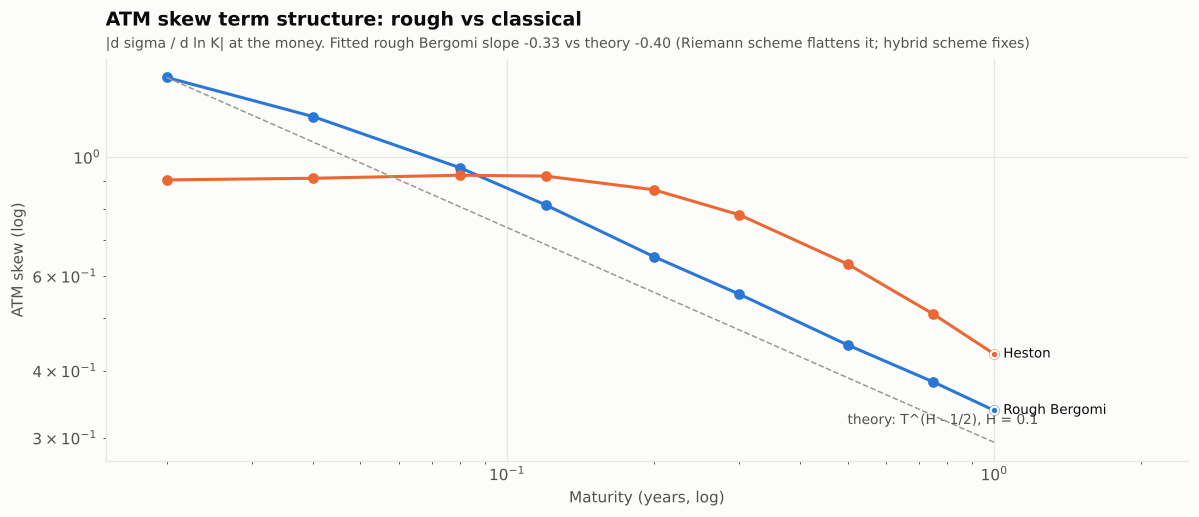

In [20]:
def rbergomi_paths(H=0.1, eta=1.9, rho=-0.9, xi=0.04, T=1.0, steps=250, paths=40_000, seed=SEED, S=100.0):
    rng = np.random.default_rng(seed)
    dt = T / steps
    t = dt * np.arange(1, steps + 1)
    # W[i, j] = sqrt(2H)/dt * integral over [t_j, t_j+1] of (t_i - s)^(H - 1/2) ds, j < i (strictly causal)
    i_idx, j_idx = np.meshgrid(np.arange(1, steps + 1), np.arange(steps), indexing="ij")
    ti, tj = i_idx * dt, j_idx * dt
    with np.errstate(invalid="ignore"):
        Wk = math.sqrt(2 * H) / (H + 0.5) * (np.maximum(ti - tj, 0) ** (H + 0.5) - np.maximum(ti - tj - dt, 0) ** (H + 0.5)) / dt
    Wk = np.where(j_idx < i_idx, Wk, 0.0)
    dW = rng.standard_normal((paths, steps)) * math.sqrt(dt)
    dWp = rng.standard_normal((paths, steps)) * math.sqrt(dt)
    Vt = dW @ Wk.T                                     # Volterra process at t_1..t_n
    var_disc = (Wk ** 2).sum(axis=1) * dt
    V = xi * np.exp(eta * Vt - 0.5 * eta ** 2 * var_disc)
    V = np.hstack([np.full((paths, 1), xi), V[:, :-1]])  # left-point variance for each step
    lnS = math.log(S) + np.cumsum(-0.5 * V * dt + np.sqrt(V) * (rho * dW + math.sqrt(1 - rho ** 2) * dWp), axis=1)
    return t, np.exp(lnS)

def atm_skew_from_paths(t, P, Ts, S=100.0, width=0.08):
    out = []
    for T in Ts:
        i = int(round(T / (t[1] - t[0]))) - 1
        d = width * math.sqrt(T)
        Ks = S * np.exp(np.array([-d, d]))
        px = np.maximum(P[:, i][:, None] - Ks[None, :], 0).mean(axis=0)
        iv = implied_vol(px, S, Ks, t[i], 0.0, 0.0)
        out.append(abs(iv[1] - iv[0]) / (2 * d))
    return np.array(out)

RB_T, RB_P = rbergomi_paths()

@demo("rbergomi")
def demo_rbergomi():
    Ks = np.array([80, 90, 100, 110, 120.0])
    rows = []
    for T in [0.1, 0.5, 1.0]:
        i = int(round(T / (RB_T[1] - RB_T[0]))) - 1
        px = np.maximum(RB_P[:, i][:, None] - Ks[None, :], 0).mean(axis=0)
        rows.append(pd.Series(implied_vol(px, 100, Ks, RB_T[i], 0, 0) * 100, index=[f"K={k:g}" for k in Ks], name=f"T={T}"))
    show(pd.DataFrame(rows), "Rough Bergomi implied vols (%) : H 0.1, eta 1.9, rho -0.9, xi 4%")
    print("Mean terminal price check (should be 100):", round(RB_P[:, -1].mean(), 3))

DEMOS["rbergomi"]()

Ts = np.array([0.02, 0.04, 0.08, 0.12, 0.2, 0.3, 0.5, 0.75, 1.0])
sk_rb = atm_skew_from_paths(RB_T, RB_P, Ts)
p_h = dict(v0=0.04, kappa=2.0, theta=0.04, xi=0.8, rho=-0.9)  # Heston with similar ATM vol and correlation
sk_h = []
for T in Ts:
    d = 0.08 * math.sqrt(T)
    iv = cf_iv("heston", p_h, 100 * np.exp(np.array([-d, d])), T, S=100, r=0, q=0)
    sk_h.append(abs(iv[1] - iv[0]) / (2 * d))
sk_h = np.array(sk_h)
slope = np.polyfit(np.log(Ts[:5]), np.log(sk_rb[:5]), 1)[0]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(Ts, sk_rb, "o-", color=PALETTE[0]); ax.plot(Ts, sk_h, "o-", color=PALETTE[1])
ax.plot(Ts, sk_rb[0] * (Ts / Ts[0]) ** (0.1 - 0.5), color=MUTED, ls="--", lw=1)
ax.text(Ts[-3], sk_rb[0] * (Ts[-3] / Ts[0]) ** (-0.4) * 0.82, "theory: T^(H - 1/2), H = 0.1", color=INK2, fontsize=9)
end_labels(ax, {"Rough Bergomi": (Ts, sk_rb, PALETTE[0]), "Heston": (Ts, sk_h, PALETTE[1])})
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.015, 2.5)
style(ax, "ATM skew term structure: rough vs classical",
      f"|d sigma / d ln K| at the money. Fitted rough Bergomi slope {slope:.2f} vs theory -0.40 (Riemann scheme flattens it; hybrid scheme fixes)",
      "Maturity (years, log)", "ATM skew (log)")
plt.tight_layout(); plt.show()

## 15. Interest-rate models: Hull-White one-factor

$dr = (\theta(t)-ar)dt+\sigma dW$, with $\theta(t)$ fitted to today's curve. Zero-coupon bond option (Jamshidian 1989):

$$ZBC = P(0,S)N(h) - K\,P(0,T)N(h-\sigma_p),\quad \sigma_p=\frac\sigma a\left(1-e^{-a(S-T)}\right)\sqrt{\frac{1-e^{-2aT}}{2a}},\quad h=\frac{1}{\sigma_p}\ln\frac{P(0,S)}{K P(0,T)}+\frac{\sigma_p}{2}$$

A caplet is a put on a zero-coupon bond, so this one formula also prices caps and floors. Coupon-bond options and European swaptions follow by Jamshidian's decomposition.

In [21]:
def hw_zcb_option(T, Smat, K, a, sigma, P, kind="call"):
    """P: function t -> discount factor today."""
    sp = sigma / a * (1 - math.exp(-a * (Smat - T))) * math.sqrt((1 - math.exp(-2 * a * T)) / (2 * a))
    h = math.log(P(Smat) / (K * P(T))) / sp + sp / 2
    if kind == "call":
        return P(Smat) * norm.cdf(h) - K * P(T) * norm.cdf(h - sp)
    return K * P(T) * norm.cdf(-h + sp) - P(Smat) * norm.cdf(-h)

def hw_mc_zcb_option(T, Smat, K, a, sigma, f0, steps=250, paths=200_000, seed=SEED, kind="call"):
    """Flat forward f0. r = x + alpha(t), x Gaussian OU. Bond price at T from the affine formula."""
    rng = np.random.default_rng(seed)
    dt = T / steps
    x = np.zeros(paths); integral = np.zeros(paths)
    alpha = lambda t: f0 + sigma ** 2 / (2 * a * a) * (1 - math.exp(-a * t)) ** 2
    for i in range(steps):
        t = i * dt
        r_now = x + alpha(t)
        x = x * math.exp(-a * dt) + sigma * math.sqrt((1 - math.exp(-2 * a * dt)) / (2 * a)) * rng.standard_normal(paths)
        integral += 0.5 * (r_now + x + alpha(t + dt)) * dt
    B = (1 - math.exp(-a * (Smat - T))) / a
    P = lambda t: math.exp(-f0 * t)
    rT = x + alpha(T)
    PTS = P(Smat) / P(T) * np.exp(B * f0 - sigma ** 2 / (4 * a) * (1 - math.exp(-2 * a * T)) * B * B - B * rT)
    pay = np.maximum(PTS - K, 0) if kind == "call" else np.maximum(K - PTS, 0)
    return float((np.exp(-integral) * pay).mean())

@demo("hw")
def demo_hw():
    f0, a, s = 0.025, 0.10, 0.01
    P = lambda t: math.exp(-f0 * t)
    Kfwd = P(5) / P(1)
    rows = []
    for mult in [0.98, 1.0, 1.02]:
        K = Kfwd * mult
        rows.append({"strike / forward bond": mult, "Jamshidian closed form": hw_zcb_option(1, 5, K, a, s, P),
                     "MC (exact OU, 200k)": hw_mc_zcb_option(1, 5, K, a, s, f0)})
    show(pd.DataFrame(rows), "Hull-White: 1y option on a 5y zero-coupon bond (a 10%, sigma 1%)")
    # caplet = (1 + K tau) puts on the ZCB struck at 1/(1 + K tau)
    tau, Kc = 0.25, 0.03
    caplet = (1 + Kc * tau) * hw_zcb_option(1.0, 1.25, 1 / (1 + Kc * tau), a, s, P, "put")
    print(f"Caplet 1y x 3m, strike 3%, via ZCB put: {caplet * 1e4:.2f} bp of notional")

DEMOS["hw"]()


### Hull-White: 1y option on a 5y zero-coupon bond (a 10%, sigma 1%)


,strike / forward bond,Jamshidian closed form,"MC (exact OU, 200k)"
0,0.980000,0.021955,0.022040
1,1.000000,0.011050,0.011108
2,1.020000,0.004485,0.004513


Caplet 1y x 3m, strike 3%, via ZCB put: 4.40 bp of notional


## 16. Market practice and data-driven methods

**Vanna-Volga (FX):** price = BSM at ATM vol + the market cost of hedging vanna and volga with three pillars:
$$C^{VV}(K) = C^{BS}(K,\sigma_{ATM}) + \sum_{i=1}^3 x_i(K)\left[C^{mkt}(K_i)-C^{BS}(K_i,\sigma_{ATM})\right],\quad x_i(K)=\frac{\mathcal V(K)}{\mathcal V(K_i)}\prod_{j\ne i}\frac{\ln(K_j/K)}{\ln(K_j/K_i)}$$

**Neural surrogate:** learn the map (model parameters, strike, maturity) to implied vol from a slow-but-exact pricer, then evaluate in microseconds. Shown here on Heston so the "truth" is cheap to check.

**Model-free implied variance (VIX):** $\sigma^2=\frac{2}{T}\sum_i\frac{\Delta K_i}{K_i^2}e^{rT}Q(K_i)-\frac1T\left(\frac{F}{K_0}-1\right)^2$. Under Heston it must match $\frac1T\mathbb E\int_0^Tv_tdt=\theta+(v_0-\theta)\frac{1-e^{-\kappa T}}{\kappa T}$.


### Vanna-Volga hits its three pillars exactly (that is the point)


,pillar strike,market vol,VV vol at pillar
0,10.718696,0.085000,0.085000
1,11.151742,0.075000,0.075000
2,11.540701,0.073000,0.073000


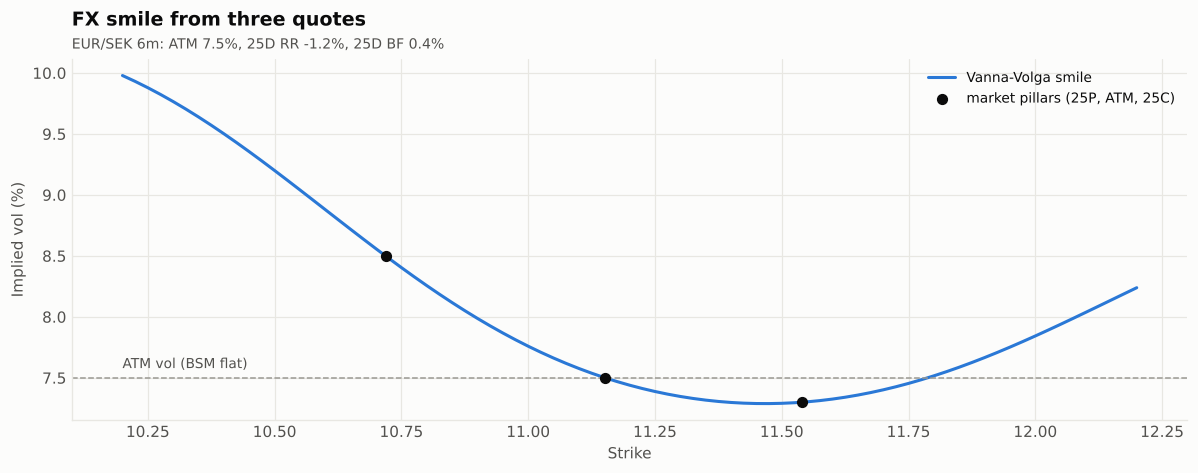

In [22]:
def fx_strike_from_delta(S, T, rd, rf, sigma, delta, kind="call"):
    """Spot delta, premium unadjusted. Real FX desks argue about which delta for hours; we pick one and move on."""
    if kind == "call":
        return S * math.exp(-norm.ppf(delta * math.exp(rf * T)) * sigma * math.sqrt(T) + (rd - rf + 0.5 * sigma ** 2) * T)
    return S * math.exp(norm.ppf(abs(delta) * math.exp(rf * T)) * sigma * math.sqrt(T) + (rd - rf + 0.5 * sigma ** 2) * T)

def vanna_volga(S, K, T, rd, rf, atm, rr25, bf25):
    s_c, s_p = atm + bf25 + 0.5 * rr25, atm + bf25 - 0.5 * rr25
    K1 = fx_strike_from_delta(S, T, rd, rf, s_p, -0.25, "put")
    K2 = S * math.exp((rd - rf + 0.5 * atm ** 2) * T)                 # ATM delta-neutral straddle strike
    K3 = fx_strike_from_delta(S, T, rd, rf, s_c, 0.25, "call")
    Ki, si = np.array([K1, K2, K3]), np.array([s_p, atm, s_c])
    K = np.atleast_1d(np.asarray(K, float))
    vega = lambda k: bsm_greeks(S, k, T, rd, atm, rf)["vega_per_volpt"]
    lnK = np.log(Ki)
    x = np.empty((len(K), 3))
    for i in range(3):
        j = [m for m in range(3) if m != i]
        x[:, i] = vega(K) / vega(Ki[i]) * (lnK[j[0]] - np.log(K)) * (lnK[j[1]] - np.log(K)) / ((lnK[j[0]] - lnK[i]) * (lnK[j[1]] - lnK[i]))
    cost = garman_kohlhagen(S, Ki, T, rd, rf, si) - garman_kohlhagen(S, Ki, T, rd, rf, atm)
    price = garman_kohlhagen(S, K, T, rd, rf, atm) + x @ cost
    return price, implied_vol(price, S, K, T, rd, rf), Ki, si

@demo("vanna_volga")
def demo_vv():
    S, T, rd, rf = 11.15, 0.5, 0.020, 0.0225
    atm, rr, bf = 0.075, -0.012, 0.004              # EUR/SEK-ish: puts on EUR bid (SEK strength is the fear)
    Ks = np.linspace(10.2, 12.2, 81)
    _, iv, Ki, si = vanna_volga(S, Ks, T, rd, rf, atm, rr, bf)
    _, iv_p, _, _ = vanna_volga(S, Ki, T, rd, rf, atm, rr, bf)
    show(pd.DataFrame({"pillar strike": Ki, "market vol": si, "VV vol at pillar": iv_p}),
         "Vanna-Volga hits its three pillars exactly (that is the point)")
    fig, ax = plt.subplots(figsize=(11, 4.4))
    ax.plot(Ks, iv * 100, color=PALETTE[0], label="Vanna-Volga smile")
    ax.scatter(Ki, si * 100, color=INK, s=40, zorder=4, label="market pillars (25P, ATM, 25C)")
    ax.axhline(atm * 100, color=MUTED, ls="--", lw=1); ax.text(Ks[0], atm * 100 + 0.08, "ATM vol (BSM flat)", color=INK2, fontsize=9)
    ax.legend(loc="upper right")
    style(ax, "FX smile from three quotes", "EUR/SEK 6m: ATM 7.5%, 25D RR -1.2%, 25D BF 0.4%", "Strike", "Implied vol (%)")
    plt.tight_layout(); plt.show()

DEMOS["vanna_volga"]()


### Neural surrogate for Heston implied vols


,value
training samples,"21,238.000000"
test samples,"3,748.000000"
train time (s),25.767512
test MAE (vol pts),0.104895
test 99th pct abs error (vol pts),0.409375
NN time per vol (microseconds),1.890383
"COS + bisection implied vol, per vol (microseconds)","15,151.001765"


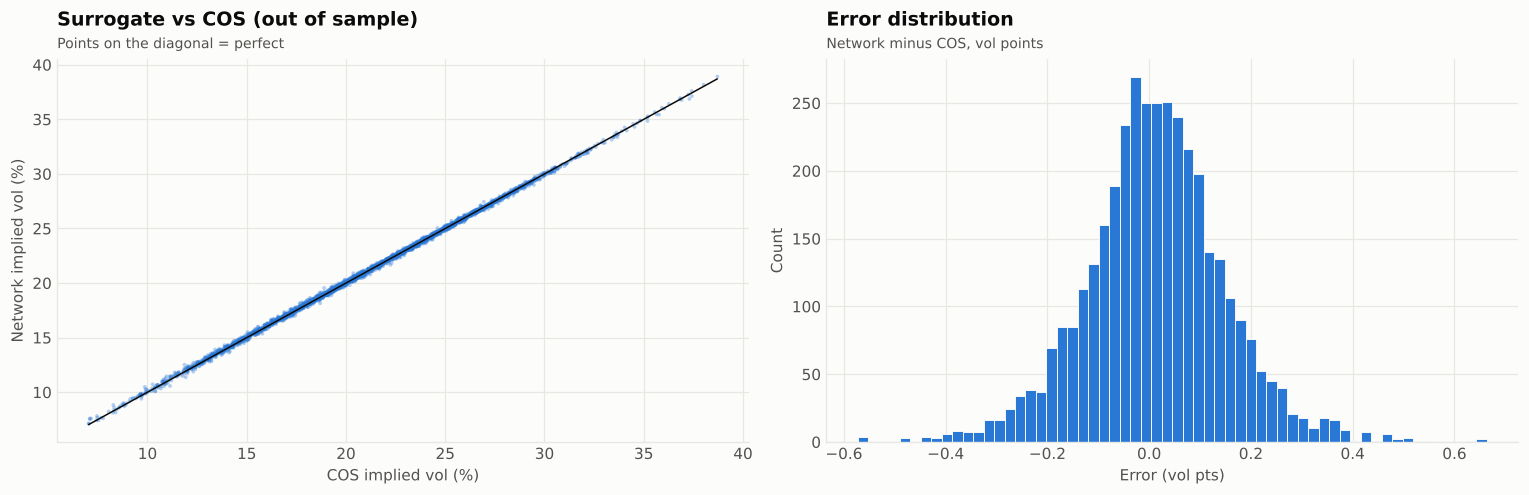


### 30-day variance index from a strip of Heston option prices (vol points)


,value
model-free VIX-style index,20.012701
Heston expected vol sqrt(E[avg v]),20.000000
ATM implied vol,19.398246


Index > ATM vol because the strip includes the expensive downside wing: that gap is the variance risk premium's home.


In [23]:
try:
    from sklearn.neural_network import MLPRegressor
    from sklearn.preprocessing import StandardScaler
    HAVE_SK = True
except ImportError:
    HAVE_SK = False

def heston_training_set(n_sets=2500, seed=SEED):
    rng = np.random.default_rng(seed)
    k = np.linspace(-0.3, 0.2, 10)
    X, y = [], []
    for _ in range(n_sets):
        p = dict(v0=rng.uniform(0.01, 0.09), kappa=rng.uniform(0.5, 4.0), theta=rng.uniform(0.01, 0.09),
                 xi=rng.uniform(0.2, 1.0), rho=rng.uniform(-0.9, -0.1))
        T = rng.uniform(0.1, 2.0)
        iv = heston_iv(100, 100 * np.exp(k), T, 0, 0, **p)
        for kk, v in zip(k, np.atleast_1d(iv)):
            if np.isfinite(v):
                X.append([p["v0"], p["kappa"], p["theta"], p["xi"], p["rho"], T, kk]); y.append(v)
    return np.array(X), np.array(y)

NN = None
@demo("nn")
def demo_nn():
    global NN
    if not HAVE_SK:
        print("scikit-learn not installed: pip install scikit-learn to run the surrogate demo."); return
    if NN is None:
        X, y = heston_training_set()
        n_tr = int(0.85 * len(X))
        sc = StandardScaler().fit(X[:n_tr])
        net = MLPRegressor(hidden_layer_sizes=(64, 64, 64), max_iter=250, early_stopping=True, random_state=SEED, tol=1e-6)
        t0 = time.perf_counter(); net.fit(sc.transform(X[:n_tr]), y[:n_tr]); train_s = time.perf_counter() - t0
        NN = (net, sc, X[n_tr:], y[n_tr:], train_s, n_tr)
    net, sc, Xte, yte, train_s, n_tr = NN
    pred, t_nn = timed(net.predict, sc.transform(Xte))
    err = (pred - yte) * 100
    def cos_loop():  # the slow path: one COS call per parameter set
        for row in Xte[::10]:
            heston_iv(100, 100 * np.exp(np.array([row[6]])), row[5], 0, 0, v0=row[0], kappa=row[1], theta=row[2], xi=row[3], rho=row[4])
    _, t_cos = timed(cos_loop, repeat=1)
    show({"training samples": n_tr, "test samples": len(Xte), "train time (s)": train_s,
          "test MAE (vol pts)": np.abs(err).mean(), "test 99th pct abs error (vol pts)": np.percentile(np.abs(err), 99),
          "NN time per vol (microseconds)": t_nn / len(Xte) * 1e6,
          "COS + bisection implied vol, per vol (microseconds)": t_cos / len(Xte[::10]) * 1e6},
         "Neural surrogate for Heston implied vols")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    axes[0].scatter(yte * 100, pred * 100, s=6, alpha=0.35, color=PALETTE[0], edgecolor="none")
    lim = [yte.min() * 100, yte.max() * 100]; axes[0].plot(lim, lim, color=INK, lw=1)
    style(axes[0], "Surrogate vs COS (out of sample)", "Points on the diagonal = perfect", "COS implied vol (%)", "Network implied vol (%)")
    axes[1].hist(err, bins=60, color=PALETTE[0], edgecolor=SURFACE, linewidth=0.6)
    style(axes[1], "Error distribution", "Network minus COS, vol points", "Error (vol pts)", "Count")
    plt.tight_layout(); plt.show()

@demo("vix")
def demo_vix():
    T, r = 30 / 365, 0.03
    p = P_HESTON
    Ks = np.arange(30.0, 250.0, 0.5)
    cf = make_cf("heston", S0, T, r, 0.0, **p)
    calls = price_cos(cf, S0, Ks, T, r, 0.0, N=512)
    F = S0 * math.exp(r * T)
    puts = calls - S0 + Ks * math.exp(-r * T)
    K0_ = Ks[Ks <= F].max()
    Q = np.where(Ks < K0_, puts, np.where(Ks > K0_, calls, 0.5 * (puts + calls)))
    dK = np.gradient(Ks)
    var = 2 / T * np.sum(dK / Ks ** 2 * math.exp(r * T) * Q) - (F / K0_ - 1) ** 2 / T
    theo = p["theta"] + (p["v0"] - p["theta"]) * (1 - math.exp(-p["kappa"] * T)) / (p["kappa"] * T)
    show({"model-free VIX-style index": math.sqrt(var) * 100, "Heston expected vol sqrt(E[avg v])": math.sqrt(theo) * 100,
          "ATM implied vol": heston_iv(S0, F, T, r, 0.0, **p) * 100},
         "30-day variance index from a strip of Heston option prices (vol points)")
    print("Index > ATM vol because the strip includes the expensive downside wing: that gap is the variance risk premium's home.")

for k in ["nn", "vix"]:
    DEMOS[k]()

## 17. Smile gallery and risk-neutral densities

Every model in one view: the implied vol smile it produces at $T=0.5$, with flat BSM at 20% as the dashed reference. Then the risk-neutral densities behind four of them, recovered by Breeden-Litzenberger: $f(K)=e^{rT}\frac{\partial^2C}{\partial K^2}$.

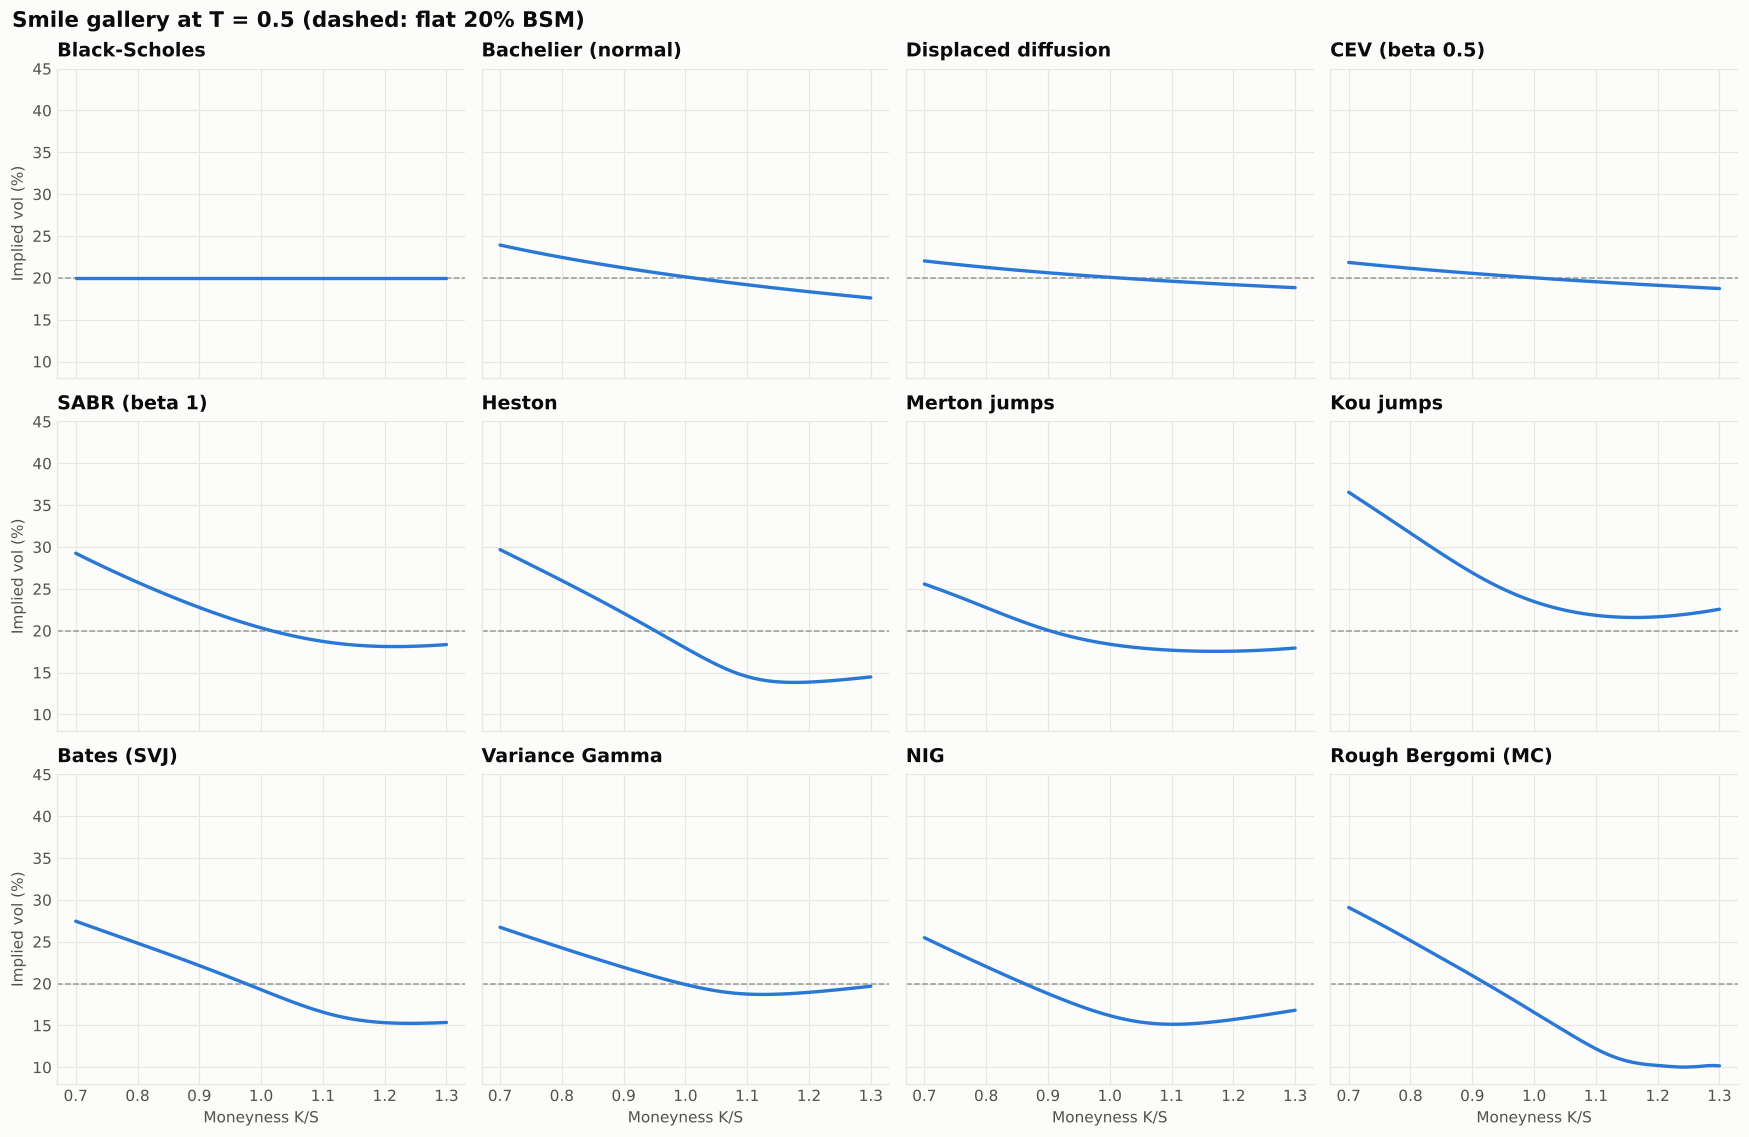

In [24]:
T = 0.5
mny = np.linspace(0.7, 1.3, 61); Kg = S0 * mny
F = S0 * math.exp((R0 - Q0) * T)
i_rb = int(round(T / (RB_T[1] - RB_T[0]))) - 1
gallery = {
    "Black-Scholes": np.full_like(mny, SIG0),
    "Bachelier (normal)": implied_vol(bachelier(F, Kg, T, R0, SIG0 * F), S0, Kg, T, R0, Q0),
    "Displaced diffusion": implied_vol(displaced_diffusion(F, Kg, T, R0, 0.10, F), S0, Kg, T, R0, Q0),
    "CEV (beta 0.5)": implied_vol(cev_call(S0, Kg, T, R0, 0.2 * S0 ** 0.5, 0.5, Q0), S0, Kg, T, R0, Q0),
    "SABR (beta 1)": sabr_vol(F, Kg, T, 0.2, 1.0, -0.5, 0.8),
    "Heston": cf_iv("heston", P_HESTON, Kg, T),
    "Merton jumps": cf_iv("merton", P_MERTON, Kg, T),
    "Kou jumps": cf_iv("kou", P_KOU, Kg, T),
    "Bates (SVJ)": cf_iv("bates", P_BATES, Kg, T),
    "Variance Gamma": cf_iv("vg", P_VG, Kg, T),
    "NIG": cf_iv("nig", P_NIG, Kg, T),
    "Rough Bergomi (MC)": implied_vol(np.maximum(RB_P[:, i_rb][:, None] - mny[None, :] * 100, 0).mean(axis=0), 100, mny * 100, RB_T[i_rb], 0, 0),
}
fig, axes = plt.subplots(3, 4, figsize=(16, 10.5), sharex=True, sharey=True)
for ax, (nm, iv) in zip(axes.ravel(), gallery.items()):
    ax.axhline(SIG0 * 100, color=MUTED, ls="--", lw=1)
    ax.plot(mny, iv * 100, color=PALETTE[0], lw=2.2)
    ax.set_ylim(8, 45)
    style(ax, nm)
for ax in axes[-1]: ax.set_xlabel("Moneyness K/S")
for ax in axes[:, 0]: ax.set_ylabel("Implied vol (%)")
fig.suptitle("Smile gallery at T = 0.5 (dashed: flat 20% BSM)", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

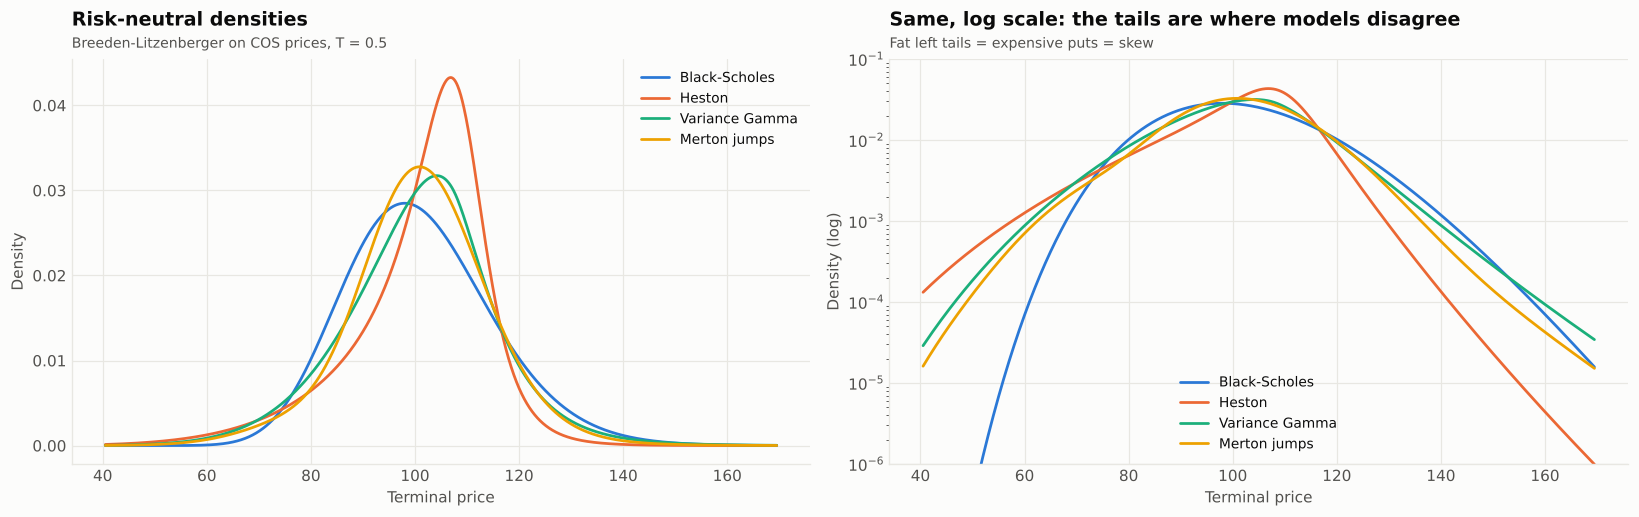

In [25]:
T = 0.5
Kd = np.linspace(40, 170, 1301); h = Kd[1] - Kd[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ser_lin, ser_log = {}, {}
for i, (nm, model, p) in enumerate([("Black-Scholes", "bsm", {"sigma": SIG0}), ("Heston", "heston", P_HESTON),
                                     ("Variance Gamma", "vg", P_VG), ("Merton jumps", "merton", P_MERTON)]):
    C = price_cos(make_cf(model, S0, T, R0, Q0, **p), S0, Kd, T, R0, Q0, N=512)
    dens = math.exp(R0 * T) * np.gradient(np.gradient(C, h), h)
    dens = np.maximum(dens, 1e-12)[5:-5]                    # one-sided differences at the grid edges are junk
    axes[0].plot(Kd[5:-5], dens, color=PALETTE[i], lw=1.8, label=nm)
    axes[1].plot(Kd[5:-5], dens, color=PALETTE[i], lw=1.8, label=nm)
axes[0].legend(loc="upper right"); axes[1].legend(loc="lower center")
axes[1].set_yscale("log"); axes[1].set_ylim(1e-6, 0.1)
style(axes[0], "Risk-neutral densities", "Breeden-Litzenberger on COS prices, T = 0.5", "Terminal price", "Density")
style(axes[1], "Same, log scale: the tails are where models disagree", "Fat left tails = expensive puts = skew", "Terminal price", "Density (log)")
plt.tight_layout(); plt.show()

## 18. Calibration shoot-out

A synthetic "market" is generated from **Bates** (stoch vol + jumps) with 0.2 vol-point noise, at 4 maturities and 9 strikes. Then:

* **Heston** is calibrated once to all 36 quotes (5 parameters, global).
* **SABR** ($\beta=1$) is calibrated slice by slice (3 parameters per maturity, 12 in total).

Expect: SABR fits each slice better (more parameters, no term-structure constraint), Heston misses the short end (no jumps). That is the real trade-off between a *smile interpolator* and a *dynamic model*.

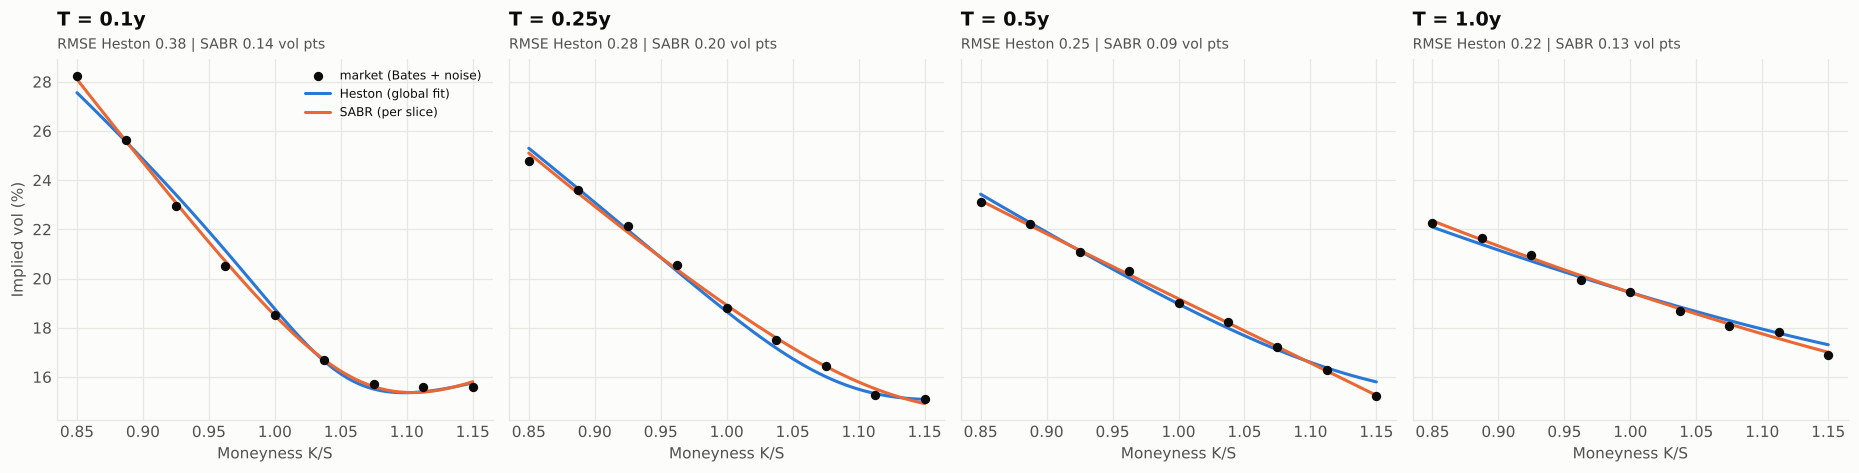


### Fit quality by maturity


,maturity,Heston RMSE (vol pts),SABR RMSE (vol pts)
0,0.100000,0.377590,0.144350
1,0.250000,0.275394,0.197551
2,0.500000,0.254833,0.088924
3,1.000000,0.223243,0.133328



### Calibrated parameters


,value
Heston v0,0.038526
Heston kappa,7.355126
Heston theta,0.041976
Heston xi,0.961058
Heston rho,-0.638708
Heston calibration time (s),5.906087
"SABR calibration time, 4 slices (s)",0.015638


In [26]:
MAT = np.array([0.1, 0.25, 0.5, 1.0]); MNY = np.linspace(0.85, 1.15, 9)
rng = np.random.default_rng(SEED)
MKT = np.array([cf_iv("bates", P_BATES, S0 * MNY, t) for t in MAT]) + rng.normal(0, 0.002, (len(MAT), len(MNY)))

def heston_resid(x):
    p = dict(v0=x[0], kappa=x[1], theta=x[2], xi=x[3], rho=x[4])
    model = np.array([heston_iv(S0, S0 * MNY, t, R0, Q0, **p) for t in MAT])
    return np.nan_to_num((model - MKT).ravel(), nan=0.5)

t0 = time.perf_counter()
fit_h = optimize.least_squares(heston_resid, x0=[0.04, 1.0, 0.04, 0.5, -0.5],
                               bounds=([0.001, 0.05, 0.001, 0.05, -0.99], [0.5, 10, 0.5, 3.0, 0.5]))
t_h = time.perf_counter() - t0
PH = dict(zip(["v0", "kappa", "theta", "xi", "rho"], fit_h.x))

fit_s, t0 = [], time.perf_counter()
for j, t in enumerate(MAT):
    Fw = S0 * math.exp((R0 - Q0) * t)
    res = optimize.least_squares(lambda x: sabr_vol(Fw, S0 * MNY, t, x[0], 1.0, x[1], x[2]) - MKT[j],
                                 x0=[0.2, -0.5, 1.0], bounds=([0.01, -0.999, 0.01], [2.0, 0.999, 10.0]))
    fit_s.append(res.x)
t_s = time.perf_counter() - t0

rmse_h, rmse_s = [], []
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), sharey=True)
fine = np.linspace(0.85, 1.15, 61)
for j, (ax, t) in enumerate(zip(axes, MAT)):
    Fw = S0 * math.exp((R0 - Q0) * t)
    hv = heston_iv(S0, S0 * fine, t, R0, Q0, **PH)
    sv = sabr_vol(Fw, S0 * fine, t, fit_s[j][0], 1.0, fit_s[j][1], fit_s[j][2])
    ax.scatter(MNY, MKT[j] * 100, color=INK, s=26, zorder=4, label="market (Bates + noise)")
    ax.plot(fine, hv * 100, color=PALETTE[0], label="Heston (global fit)")
    ax.plot(fine, sv * 100, color=PALETTE[1], label="SABR (per slice)")
    rmse_h.append(np.sqrt(np.mean((heston_iv(S0, S0 * MNY, t, R0, Q0, **PH) - MKT[j]) ** 2)) * 100)
    rmse_s.append(np.sqrt(np.mean((sabr_vol(Fw, S0 * MNY, t, *[fit_s[j][0], 1.0, fit_s[j][1], fit_s[j][2]]) - MKT[j]) ** 2)) * 100)
    style(ax, f"T = {t}y", f"RMSE Heston {rmse_h[-1]:.2f} | SABR {rmse_s[-1]:.2f} vol pts", "Moneyness K/S")
axes[0].set_ylabel("Implied vol (%)"); axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

show(pd.DataFrame({"maturity": MAT, "Heston RMSE (vol pts)": rmse_h, "SABR RMSE (vol pts)": rmse_s}), "Fit quality by maturity")
show({**{f"Heston {k}": v for k, v in PH.items()}, "Heston calibration time (s)": t_h, "SABR calibration time, 4 slices (s)": t_s},
     "Calibrated parameters")

## 19. Speed vs accuracy benchmark

Every European-capable method prices the same contract (S=K=100, T=1, r=3%, q=1%, vol 20%) under BSM dynamics, so the closed form is the exact answer. Times are best-of-3 wall clock on whatever machine runs this notebook; compare ratios, not absolute numbers.


### Benchmark (exact 8.82732123)


,method,price,abs error,time (ms)
12,COS (128 terms),8.827321,0.000000,0.108575
0,BSM closed form,8.827321,0.000000,0.189394
3,Leisen-Reimer tree (101),8.827283,0.000038,0.294369
11,Carr-Madan FFT (4096),8.828002,0.000680,0.536048
4,Trinomial (300),8.824053,0.003269,1.439382
2,Jarrow-Rudd tree (500),8.823384,0.003937,1.594155
1,CRR tree (500),8.823399,0.003922,1.654344
8,MC antithetic + CV (131k),8.823313,0.004008,2.703569
7,MC plain (131k),8.811228,0.016093,2.827762
9,Sobol QMC (131k),8.827234,0.000087,5.473909


/tmp/ipykernel_428/410314953.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


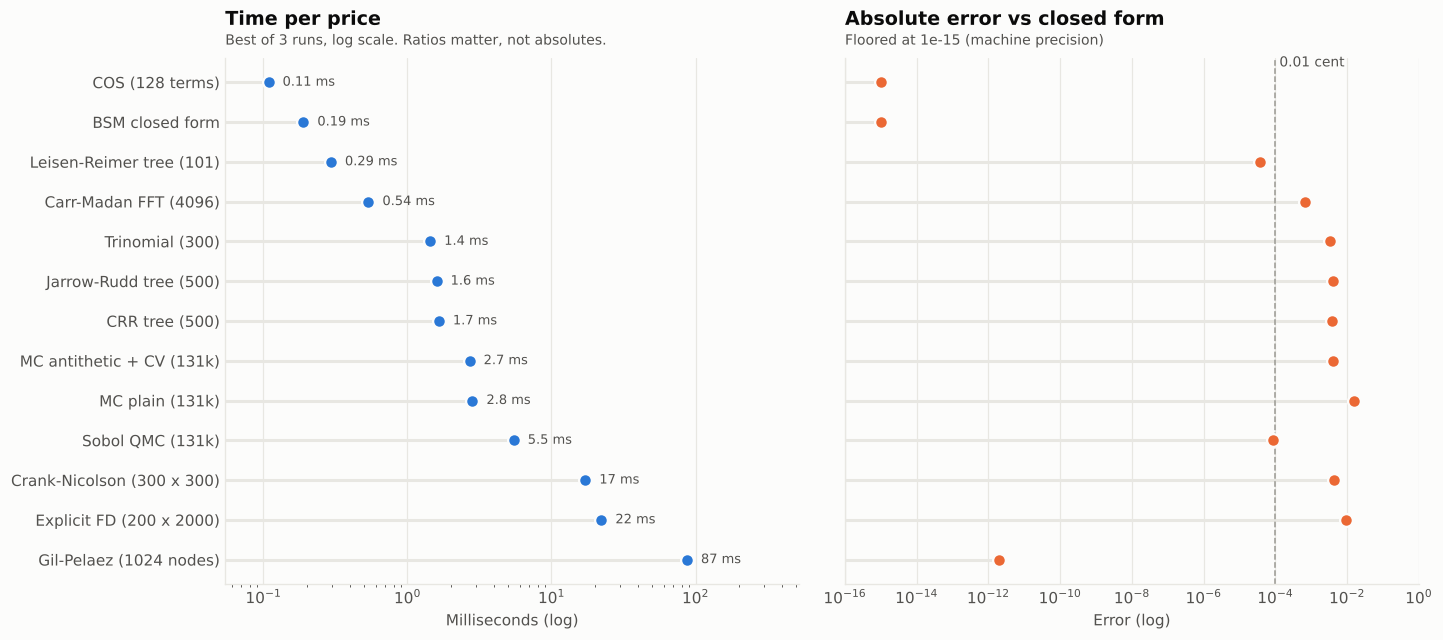

In [27]:
cf0 = make_cf("bsm", S0, T0, R0, Q0, sigma=SIG0)
ex = bsm(S0, K0, T0, R0, SIG0, Q0)
bench = {
    "BSM closed form": lambda: bsm(S0, K0, T0, R0, SIG0, Q0),
    "CRR tree (500)": lambda: binomial(S0, K0, T0, R0, SIG0, Q0, 500),
    "Jarrow-Rudd tree (500)": lambda: binomial(S0, K0, T0, R0, SIG0, Q0, 500, scheme="jr"),
    "Leisen-Reimer tree (101)": lambda: binomial(S0, K0, T0, R0, SIG0, Q0, 101, scheme="lr"),
    "Trinomial (300)": lambda: trinomial(S0, K0, T0, R0, SIG0, Q0, 300),
    "Explicit FD (200 x 2000)": lambda: pde_price(S0, K0, T0, R0, SIG0, Q0, "call", theta=0.0, Ns=200, Nt=2000),
    "Crank-Nicolson (300 x 300)": lambda: pde_price(S0, K0, T0, R0, SIG0, Q0, "call", theta=0.5, Ns=300, Nt=300),
    "MC plain (131k)": lambda: mc_euro(S0, K0, T0, R0, SIG0, Q0, 2 ** 17, "plain")[0],
    "MC antithetic + CV (131k)": lambda: mc_euro(S0, K0, T0, R0, SIG0, Q0, 2 ** 17, "antithetic+cv")[0],
    "Sobol QMC (131k)": lambda: mc_euro(S0, K0, T0, R0, SIG0, Q0, 2 ** 17, "qmc")[0],
    "Gil-Pelaez (1024 nodes)": lambda: price_gil_pelaez(cf0, S0, K0, T0, R0, Q0),
    "Carr-Madan FFT (4096)": lambda: price_fft(cf0, S0, K0, T0, R0),
    "COS (128 terms)": lambda: price_cos(cf0, S0, K0, T0, R0, Q0, N=128),
}
rows = []
for nm, fn in bench.items():
    v, t = timed(fn)
    rows.append({"method": nm, "price": float(np.atleast_1d(v)[0]), "abs error": abs(float(np.atleast_1d(v)[0]) - ex), "time (ms)": t * 1e3})
BENCH = pd.DataFrame(rows).sort_values("time (ms)")
show(BENCH, f"Benchmark (exact {ex:.8f})")

# Paired dot plot: same rows, two log axes. Labels live on the y-axis, so they can never collide.
B = BENCH.sort_values("time (ms)", ascending=False).reset_index(drop=True)
y = np.arange(len(B))
err = np.maximum(B["abs error"].values, 1e-15)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True, gridspec_kw={"wspace": 0.08})
a1.hlines(y, B["time (ms)"].min() / 2, B["time (ms)"], color=GRID, lw=2)
a1.scatter(B["time (ms)"], y, s=70, color=PALETTE[0], edgecolor=SURFACE, lw=1.5, zorder=3)
for yi, t in zip(y, B["time (ms)"]):
    a1.text(t * 1.25, yi, f"{t:.2g} ms", va="center", fontsize=8.5, color=INK2)
a1.set_xscale("log"); a1.set_yticks(y, B["method"]); a1.grid(axis="y", visible=False)
a1.set_xlim(B["time (ms)"].min() / 2, B["time (ms)"].max() * 6)
style(a1, "Time per price", "Best of 3 runs, log scale. Ratios matter, not absolutes.", "Milliseconds (log)")
a2.hlines(y, 1e-16, err, color=GRID, lw=2)
a2.scatter(err, y, s=70, color=PALETTE[1], edgecolor=SURFACE, lw=1.5, zorder=3)
a2.axvline(1e-4, color=MUTED, ls="--", lw=1)
a2.text(1.3e-4, len(B) - 0.6, "0.01 cent", color=INK2, fontsize=9)
a2.set_xscale("log"); a2.set_xlim(1e-16, 1); a2.grid(axis="y", visible=False)
style(a2, "Absolute error vs closed form", "Floored at 1e-15 (machine precision)", "Error (log)")
plt.tight_layout(); plt.show()

## 20. Model selection guide

What desks actually run, by product. "Model + method" because both choices matter.

| Product | Typical choice | Why | Fallback / check |
|---|---|---|---|
| Listed equity/index vanilla (European) | BSM for quoting, SVI/SSVI surface for marks | market quotes are BSM vols | Heston via COS for risk |
| American single-stock options | Leisen-Reimer tree or CN + projected PDE on a local vol surface | early exercise, discrete dividends | Bjerksund-Stensland for speed |
| Short-dated index options, SPX/VIX | Rough Bergomi / rough Heston, or Bates | power-law skew, jumps | Neural surrogate for calibration speed |
| Equity barriers, autocallables | Local-stochastic vol by Monte Carlo | needs vanilla fit + realistic forward skew | Local vol PDE, Heston MC |
| Cliquets, forward starts | Stochastic vol (Heston, Bergomi) | value lives in forward skew | Never pure local vol |
| FX vanillas and first-gen exotics | SABR or Vanna-Volga on Garman-Kohlhagen | three-point smile quotes | LSV for barriers |
| Swaptions, caps | Bachelier / shifted SABR per expiry | negative rates, normal vol quotes | Black-76 where rates are clearly positive |
| Bermudan swaptions, callables | Hull-White (tree/PDE) or LMM + Longstaff-Schwartz | early exercise on the curve | Two-factor models |
| Commodity and power options | Black-76, Kirk for spreads, Turnbull-Wakeman for Asians | futures-based, average-price contracts | Monte Carlo with seasonal vol |
| Variance swaps, vol indices | Model-free replication | no model needed | Heston as sanity check |
| Credit-style / compound | Geske, Merton structural | equity is an option on assets | Monte Carlo |

In [28]:
show(recommend(path_dependent=True, needs_smile=True, kind="Model"), "Models for a path-dependent product that must respect the smile")
show(recommend(path_dependent=True, needs_smile=True, kind="Method"), "...and the numerical methods to price it with")
show(recommend(speed_critical=True, kind="Method"), "Fastest numerical methods")
show(recommend(early_exercise=True, speed_critical=True), "Early exercise under time pressure")


### Models for a path-dependent product that must respect the smile


,name,kind,family,fit_score,early_exercise,products
50,Local-stochastic volatility (LSV),Model,Local volatility,3.985075,Yes,"Barriers, autocalls, TARFs"
43,Bates (SVJ),Model,Jump models,3.940299,No,"Index vanillas, FX vanillas"
48,Dupire local volatility,Model,Local volatility,3.791045,Yes,"Barriers, Americans, autocalls (historically)"
35,Heston,Model,Stochastic volatility,3.597015,No,"Vanillas, cliquets, forward starts"
38,Stein-Stein / Schobel-Zhu,Model,Stochastic volatility,3.447761,No,Vanillas
51,Rough Bergomi,Model,Rough volatility,3.388060,No,"Short-dated index options, VIX options"
40,Bergomi forward-variance (2-factor),Model,Stochastic volatility,3.343284,No,"Cliquets, VIX derivatives"
54,LIBOR / Forward Market Model (BGM),Model,Interest rate,3.238806,Approx,Rates exotics



### ...and the numerical methods to price it with


,name,kind,family,fit_score,early_exercise,products
31,Multilevel Monte Carlo,Method,Monte Carlo,4.238806,No,Exotics under SDE models
29,Quasi-Monte Carlo (Sobol),Method,Monte Carlo,4.149254,No,"Baskets, Asians, CVA"
28,"Variance-reduced MC (antithetic, control variates)",Method,Monte Carlo,4.149254,No,Same as MC
27,Plain Monte Carlo,Method,Monte Carlo,4.104478,No,"Asians, baskets, autocalls, anything exotic"
30,Longstaff-Schwartz (LSM),Method,Monte Carlo,4.044776,Yes,"Bermudan swaptions, callable exotics, American baskets"
26,"ADI schemes (Craig-Sneyd, Hundsdorfer-Verwer)",Method,PDE / finite difference,3.940299,Yes,"Heston barriers, 2D products"
24,Crank-Nicolson (+ Rannacher),Method,PDE / finite difference,3.746269,Yes,"Vanillas, barriers, Americans, local vol"
56,Neural network surrogate,Method,Market practice,3.641791,Approx,Any model with expensive pricing



### Fastest numerical methods


,name,kind,family,fit_score,early_exercise,products
34,COS method,Method,Fourier transform,4.489362,Approx,"Vanillas, digitals, Bermudans"
33,Carr-Madan FFT,Method,Fourier transform,4.382979,No,Vanilla strips for calibration
57,Model-free implied variance (VIX),Method,Market practice,4.212766,No,"Variance swaps, vol indices"
56,Neural network surrogate,Method,Market practice,4.021277,Approx,Any model with expensive pricing
24,Crank-Nicolson (+ Rannacher),Method,PDE / finite difference,3.957447,Yes,"Vanillas, barriers, Americans, local vol"
32,Characteristic function inversion (Gil-Pelaez / Lewis),Method,Fourier transform,3.957447,No,European vanillas under affine and Levy models
18,Leisen-Reimer binomial,Method,Lattice,3.787234,Yes,American vanillas
29,Quasi-Monte Carlo (Sobol),Method,Monte Carlo,3.680851,No,"Baskets, Asians, CVA"



### Early exercise under time pressure


,name,kind,family,fit_score,early_exercise,products
34,COS method,Method,Fourier transform,4.489362,Approx,"Vanillas, digitals, Bermudans"
56,Neural network surrogate,Method,Market practice,4.021277,Approx,Any model with expensive pricing
24,Crank-Nicolson (+ Rannacher),Method,PDE / finite difference,3.957447,Yes,"Vanillas, barriers, Americans, local vol"
53,Hull-White one-factor,Model,Interest rate,3.893617,Yes,"Bond options, caps (via bond puts), Bermudans"
14,Bjerksund-Stensland,Approximation,American approximation,3.787234,Approx,American vanillas
18,Leisen-Reimer binomial,Method,Lattice,3.787234,Yes,American vanillas
15,Roll-Geske-Whaley,Model,American approximation,3.638298,Yes,American calls on dividend stocks
13,Barone-Adesi-Whaley,Approximation,American approximation,3.574468,Approx,American vanillas


In [29]:
describe("Heston", run_demo=False)


### Heston
**Model** | Stochastic volatility | 1993 | Steven Heston | Early exercise: **No**

Mean-reverting variance (CIR) correlated with the asset: produces skew and term structure.

`dv = kappa (theta - v) dt + xi sqrt(v) dW2, corr(dW1, dW2) = rho`

**When it is used:** Equity and FX smile modelling, forward-skew sensitive exotics, the textbook stoch vol model.

**Typical products:** Vanillas, cliquets, forward starts

| | |
|---|---|
| Pros | Semi-closed form via CF, sensible dynamics, 5 parameters |
| Cons | Struggles with short-dated skew; Feller condition headaches |

| Accuracy | Speed | Flexibility | Smile | Ease | Overall |
|---|---|---|---|---|---|
| ■■■■□ | ■■■■□ | ■■■□□ | ■■■■□ | ■■■□□ | 3.60 |


In [30]:
# Coverage check: every implemented catalog entry must have a working demo. Fail loudly, never quietly.
needed = set(catalog["impl"]) - {""}
missing = needed - set(DEMOS)
assert not missing, f"catalog points at undefined demos: {missing}"
cov = catalog.assign(implemented=catalog["impl"] != "").groupby("family")["implemented"].agg(["sum", "size"])
cov["coverage"] = cov["sum"] / cov["size"]
show(cov.rename(columns={"sum": "implemented", "size": "entries"}), "Implementation coverage by family")
print(f"{len(DEMOS)} demos registered, {(catalog['impl'] != '').sum()} of {len(catalog)} catalog entries implemented.")


### Implementation coverage by family


,implemented,entries,coverage
family,,,
American approximation,2,3,0.666667
Closed form,12,13,0.923077
Fourier transform,3,3,1.000000
Interest rate,1,2,0.500000
Jump models,5,6,0.833333
Lattice,4,6,0.666667
Local volatility,3,4,0.750000
Market practice,3,3,1.000000
Monte Carlo,4,5,0.800000


40 demos registered, 44 of 58 catalog entries implemented.


In [31]:
# Export. Colab: lands in /content. Fabric: flip the flag to write a Delta table to the attached Lakehouse.
catalog.to_csv("option_pricing_models_catalog.csv", index=False)
BENCH.to_csv("option_pricing_benchmark.csv", index=False)

WRITE_TO_LAKEHOUSE = False
if WRITE_TO_LAKEHOUSE:
    from pyspark.sql import functions as Fsql
    sdf = spark.createDataFrame(catalog)  # noqa: F821 (spark exists in Fabric notebooks)
    (sdf.withColumn("loaded_at", Fsql.current_timestamp())
        .write.mode("overwrite").option("overwriteSchema", "true").format("delta")
        .saveAsTable("ref_option_pricing_models"))
    print("Written to Lakehouse table ref_option_pricing_models")
else:
    print("Exported CSVs. Lakehouse write skipped (WRITE_TO_LAKEHOUSE = False).")

Exported CSVs. Lakehouse write skipped (WRITE_TO_LAKEHOUSE = False).


### How to extend

* **Add a model:** append a tuple to `MODELS` in section 2 and point `impl` at a new `@demo("key")` function.
* **New CF model:** write `cf_mymodel(u, S, T, r, q, **params)`, register it in `make_cf`, and COS, FFT and Gil-Pelaez all work immediately.
* **Real market data:** replace the synthetic Bates "market" in section 18 with your own implied vol quotes (strike, maturity, vol) and the calibration code runs unchanged.